<a href="https://colab.research.google.com/github/sharath7-dev/robust-multilingual-intent-classification/blob/main/notebooks/phase1_dataset_verification_tfidf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Robust and Calibrated Multilingual Intent Classification

## Phase 1 — Dataset Verification and TF-IDF Baseline

### Goal
Verify the multilingual dataset, construct leakage-safe known and unseen intent groups, and establish a reproducible classical baseline without evaluating the test set.

### Configuration
- Dataset: MASSIVE 1.1
- Languages: English (`en-US`), Hindi (`hi-IN`), Kannada (`kn-IN`)
- Released examples: 49,563
- Original intents: 60
- Known intents used for training: 50
- Validation-OOS intents: 5
- Test-OOS intents: 5
- Random seed: 42

### Verified data integrity
- Official train, development, and test partitions preserved
- No missing utterances or intent labels
- No duplicate IDs within a locale
- Parallel examples remain in the same partition and intent across languages
- No held-out OOS intent appears in training

### TF-IDF validation baseline
The baseline combines word and character TF-IDF features with logistic regression.

| Evaluation group | Accuracy | Macro-F1 |
|---|---:|---:|
| Overall validation | 0.8369 | 0.8210 |
| English | 0.8594 | 0.8394 |
| Hindi | 0.8308 | 0.8140 |
| Kannada | 0.8205 | 0.8043 |

Training completed in 61.8 seconds. The solver converged after 115 iterations. The final test set has not been evaluated.

In [ ]:
import sys
import platform

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
except Exception as error:
    print("PyTorch check failed:", error)

Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
%cd /content
!git clone https://github.com/sharath7-dev/robust-multilingual-intent-classification.git
%cd /content/robust-multilingual-intent-classification
!git status

/content
Cloning into 'robust-multilingual-intent-classification'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.
/content/robust-multilingual-intent-classification
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

folders = [
    "notebooks",
    "src",
    "configs",
    "results/metrics",
    "results/figures",
    "docs",
    "ui",
]

for folder in folders:
    path = repo / folder
    path.mkdir(parents=True, exist_ok=True)
    (path / ".gitkeep").touch()

extra_gitignore = """

# Project data and trained artifacts
data/
models/
checkpoints/
*.pt
*.pth
*.ckpt
*.safetensors
*.bin

# Secrets and experiment services
.env
.env.*
wandb/
mlruns/

# Generated temporary outputs
*.log
.ipynb_checkpoints/
"""

gitignore = repo / ".gitignore"
existing = gitignore.read_text(encoding="utf-8") if gitignore.exists() else ""

if "# Project data and trained artifacts" not in existing:
    gitignore.write_text(existing.rstrip() + extra_gitignore, encoding="utf-8")

print("Created project structure:")
for folder in folders:
    print(" -", folder)

print("\nGit status:")

Created project structure:
 - notebooks
 - src
 - configs
 - results/metrics
 - results/figures
 - docs
 - ui

Git status:


In [ ]:
!git status --short

 M .gitignore
?? configs/
?? docs/
?? notebooks/
?? results/
?? src/
?? ui/


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

if not token:
    raise RuntimeError("GITHUB_TOKEN is unavailable. Check Notebook access in Colab Secrets.")

def run_git(*args, env=None):
    return subprocess.run(
        ["git", *args],
        cwd=repo,
        env=env,
        text=True,
        check=True,
    )

run_git("config", "user.name", "sharath7-dev")
run_git("config", "user.email", "sharath7-dev@users.noreply.github.com")

run_git("add", ".gitignore", "configs", "docs", "notebooks", "results", "src", "ui")
run_git("commit", "-m", "chore: initialize project structure and gitignore")

askpass_path = None

try:
    with tempfile.NamedTemporaryFile(
        mode="w", suffix=".sh", delete=False, encoding="utf-8"
    ) as askpass:
        askpass.write(
            '#!/bin/sh\n'
            'case "$1" in\n'
            '  *Username*) echo "x-access-token" ;;\n'
            '  *) echo "$GITHUB_TOKEN" ;;\n'
            'esac\n'
        )
        askpass_path = askpass.name

    os.chmod(askpass_path, 0o700)

    push_env = os.environ.copy()
    push_env["GITHUB_TOKEN"] = token
    push_env["GIT_ASKPASS"] = askpass_path
    push_env["GIT_TERMINAL_PROMPT"] = "0"

    run_git("push", "origin", "main", env=push_env)

finally:
    if askpass_path and os.path.exists(askpass_path):
        os.remove(askpass_path)

print("\nLatest commit:")
run_git("log", "-1", "--oneline")

print("\nWorking tree:")
run_git("status", "--short")


Latest commit:

Working tree:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

def show_git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=repo,
        text=True,
        capture_output=True,
        check=True,
    )
    print(result.stdout.strip() or "(no output)")

print("Latest local commit:")
show_git("log", "-1", "--oneline")

print("\nRemote tracking status:")
show_git("status", "--short", "--branch")

Latest local commit:
087b5c7 chore: initialize project structure and gitignore

Remote tracking status:
## main...origin/main


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

repo = Path("/content/robust-multilingual-intent-classification")
download_dir = repo / "data"
download_dir.mkdir(exist_ok=True)

url = "https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.1.tar.gz"
archive = download_dir / "amazon-massive-dataset-1.1.tar.gz"

if not archive.exists():
    print("Downloading MASSIVE 1.1...")
    urlretrieve(url, archive)
else:
    print("Archive already exists.")

size_mb = archive.stat().st_size / (1024 * 1024)

print("File:", archive.name)
print(f"Size: {size_mb:.2f} MB")
print("Download verified:", archive.exists() and archive.stat().st_size > 0)

File: amazon-massive-dataset-1.1.tar.gz
Size: 38.39 MB
Download verified: True


In [ ]:
import tarfile
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")
data_dir = repo / "data"
archive = data_dir / "amazon-massive-dataset-1.1.tar.gz"

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(data_dir, filter="data")

required_files = {}

for locale in ["en-US", "hi-IN", "kn-IN"]:
    matches = list(data_dir.rglob(f"{locale}.jsonl"))
    required_files[locale] = matches

print("Required language files:")

for locale, matches in required_files.items():
    if len(matches) == 1:
        print(f"{locale}: FOUND — {matches[0]}")
    else:
        print(f"{locale}: ERROR — found {len(matches)} matching files")

Required language files:
en-US: FOUND — /content/robust-multilingual-intent-classification/data/1.1/data/en-US.jsonl
hi-IN: FOUND — /content/robust-multilingual-intent-classification/data/1.1/data/hi-IN.jsonl
kn-IN: FOUND — /content/robust-multilingual-intent-classification/data/1.1/data/kn-IN.jsonl


In [ ]:
import json
import pandas as pd
from pathlib import Path

data_root = Path(
    "/content/robust-multilingual-intent-classification/data/1.1/data"
)

locales = ["en-US", "hi-IN", "kn-IN"]
frames = []

for locale in locales:
    file_path = data_root / f"{locale}.jsonl"

    with file_path.open("r", encoding="utf-8") as file:
        records = [json.loads(line) for line in file]

    df_locale = pd.DataFrame(records)
    frames.append(df_locale)

    print(f"\n--- {locale} ---")
    print("Rows:", len(df_locale))
    print("Partitions:", df_locale["partition"].value_counts().to_dict())
    print("Unique intents:", df_locale["intent"].nunique())
    print("Missing utterances:", df_locale["utt"].isna().sum())
    print("Missing intents:", df_locale["intent"].isna().sum())
    print("Duplicate IDs:", df_locale["id"].duplicated().sum())
    print("Sample:", df_locale["utt"].iloc[0])

df = pd.concat(frames, ignore_index=True)

print("\nCombined rows:", len(df))
print("Columns:", df.columns.tolist())
print("Locales:", sorted(df["locale"].unique().tolist()))


--- en-US ---
Rows: 16521
Partitions: {'train': 11514, 'test': 2974, 'dev': 2033}
Unique intents: 60
Missing utterances: 0
Missing intents: 0
Duplicate IDs: 0
Sample: wake me up at five am this week

--- hi-IN ---
Rows: 16521
Partitions: {'train': 11514, 'test': 2974, 'dev': 2033}
Unique intents: 60
Missing utterances: 0
Missing intents: 0
Duplicate IDs: 0
Sample: मुझे इस सप्ताह सुबह पांच बजे जगा दो

--- kn-IN ---
Rows: 16521
Partitions: {'train': 11514, 'test': 2974, 'dev': 2033}
Unique intents: 60
Missing utterances: 0
Missing intents: 0
Duplicate IDs: 0
Sample: ಈ ವಾರ ಬೆಳಗ್ಗೆ ಐದು ಗಂಟೆಗೆ ನನ್ನನ್ನು ಎದ್ದೇಳಿ

Combined rows: 49563
Columns: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments']
Locales: ['en-US', 'hi-IN', 'kn-IN']


In [ ]:
# Each shared utterance ID should remain in the same partition
# and have the same intent across all three languages.

id_checks = df.groupby("id").agg(
    locale_count=("locale", "nunique"),
    partition_count=("partition", "nunique"),
    intent_count=("intent", "nunique"),
)

incomplete_ids = (id_checks["locale_count"] != 3).sum()
partition_conflicts = (id_checks["partition_count"] != 1).sum()
intent_conflicts = (id_checks["intent_count"] != 1).sum()

print("Unique shared IDs:", len(id_checks))
print("IDs missing one or more selected languages:", incomplete_ids)
print("IDs assigned to multiple partitions:", partition_conflicts)
print("IDs assigned to multiple intents:", intent_conflicts)

passed = (
    incomplete_ids == 0
    and partition_conflicts == 0
    and intent_conflicts == 0
)

print("Parallel split verification passed:", passed)

Unique shared IDs: 16521
IDs missing one or more selected languages: 0
IDs assigned to multiple partitions: 0
IDs assigned to multiple intents: 0
Parallel split verification passed: True


In [ ]:
import json
import random
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

all_intents = sorted(df["intent"].unique().tolist())

rng = random.Random(42)
held_out_intents = sorted(rng.sample(all_intents, 10))

validation_oos_intents = held_out_intents[:5]
test_oos_intents = held_out_intents[5:]
known_intents = sorted(set(all_intents) - set(held_out_intents))

intent_split = {
    "seed": 42,
    "known_intents": known_intents,
    "validation_oos_intents": validation_oos_intents,
    "test_oos_intents": test_oos_intents,
}

config_path = repo / "configs" / "intent_split.json"
config_path.write_text(
    json.dumps(intent_split, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print("Known intents:", len(known_intents))
print("Validation OOS intents:", validation_oos_intents)
print("Test OOS intents:", test_oos_intents)
print("Overlap between OOS groups:",
      set(validation_oos_intents) & set(test_oos_intents))
print("Saved:", config_path)

Known intents: 50
Validation OOS intents: ['alarm_remove', 'audio_volume_up', 'calendar_query', 'calendar_remove', 'email_addcontact']
Test OOS intents: ['email_query', 'email_sendemail', 'play_music', 'qa_stock', 'transport_taxi']
Overlap between OOS groups: set()
Saved: /content/robust-multilingual-intent-classification/configs/intent_split.json


In [ ]:
known_set = set(known_intents)
validation_oos_set = set(validation_oos_intents)
test_oos_set = set(test_oos_intents)

train_known = df[
    (df["partition"] == "train") &
    (df["intent"].isin(known_set))
].copy()

validation_known = df[
    (df["partition"] == "dev") &
    (df["intent"].isin(known_set))
].copy()

validation_oos = df[
    (df["partition"] == "dev") &
    (df["intent"].isin(validation_oos_set))
].copy()

test_known = df[
    (df["partition"] == "test") &
    (df["intent"].isin(known_set))
].copy()

test_oos = df[
    (df["partition"] == "test") &
    (df["intent"].isin(test_oos_set))
].copy()

splits = {
    "train_known": train_known,
    "validation_known": validation_known,
    "validation_oos": validation_oos,
    "test_known": test_known,
    "test_oos": test_oos,
}

print("Split sizes:")
for name, split_df in splits.items():
    print(f"\n{name}: {len(split_df)}")
    print(split_df["locale"].value_counts().sort_index().to_dict())

training_leakage = set(train_known["intent"]) & (
    validation_oos_set | test_oos_set
)

print("\nHeld-out intents found in training:", training_leakage)
print("Training has exactly 50 intents:", train_known["intent"].nunique() == 50)
print("Verification passed:",
      not training_leakage and train_known["intent"].nunique() == 50)

Split sizes:

train_known: 26193
{'en-US': 8731, 'hi-IN': 8731, 'kn-IN': 8731}

validation_known: 4629
{'en-US': 1543, 'hi-IN': 1543, 'kn-IN': 1543}

validation_oos: 540
{'en-US': 180, 'hi-IN': 180, 'kn-IN': 180}

test_known: 6831
{'en-US': 2277, 'hi-IN': 2277, 'kn-IN': 2277}

test_oos: 1374
{'en-US': 458, 'hi-IN': 458, 'kn-IN': 458}

Held-out intents found in training: set()
Training has exactly 50 intents: True
Verification passed: True


In [ ]:
import json
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

verification_report = {
    "dataset": "MASSIVE 1.1",
    "source_archive": "amazon-massive-dataset-1.1.tar.gz",
    "archive_size_mb": 38.39,
    "locales": ["en-US", "hi-IN", "kn-IN"],
    "rows_per_locale": 16521,
    "combined_rows": 49563,
    "official_split_counts_per_locale": {
        "train": 11514,
        "dev": 2033,
        "test": 2974,
    },
    "unique_intents": 60,
    "missing_utterances": 0,
    "missing_intents": 0,
    "duplicate_ids_per_locale": 0,
    "parallel_split_conflicts": 0,
    "parallel_intent_conflicts": 0,
    "known_intents": 50,
    "validation_oos_intents": validation_oos_intents,
    "test_oos_intents": test_oos_intents,
    "experimental_split_sizes": {
        name: {
            "total": len(split_df),
            "by_locale": split_df["locale"].value_counts().sort_index().to_dict(),
        }
        for name, split_df in splits.items()
    },
    "training_oos_leakage": False,
    "verification_passed": True,
}

report_path = repo / "results" / "metrics" / "dataset_verification.json"
report_path.write_text(
    json.dumps(verification_report, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(report_path.read_text(encoding="utf-8"))
print("\nGit status:")

{
  "dataset": "MASSIVE 1.1",
  "source_archive": "amazon-massive-dataset-1.1.tar.gz",
  "archive_size_mb": 38.39,
  "locales": [
    "en-US",
    "hi-IN",
    "kn-IN"
  ],
  "rows_per_locale": 16521,
  "combined_rows": 49563,
  "official_split_counts_per_locale": {
    "train": 11514,
    "dev": 2033,
    "test": 2974
  },
  "unique_intents": 60,
  "missing_utterances": 0,
  "missing_intents": 0,
  "duplicate_ids_per_locale": 0,
  "parallel_split_conflicts": 0,
  "parallel_intent_conflicts": 0,
  "known_intents": 50,
  "validation_oos_intents": [
    "alarm_remove",
    "audio_volume_up",
    "calendar_query",
    "calendar_remove",
    "email_addcontact"
  ],
  "test_oos_intents": [
    "email_query",
    "email_sendemail",
    "play_music",
    "qa_stock",
    "transport_taxi"
  ],
  "experimental_split_sizes": {
    "train_known": {
      "total": 26193,
      "by_locale": {
        "en-US": 8731,
        "hi-IN": 8731,
        "kn-IN": 8731
      }
    },
    "validation_known": {

In [ ]:
!git status --short

?? configs/intent_split.json
?? results/metrics/dataset_verification.json


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

subprocess.run(
    ["git", "add",
     "configs/intent_split.json",
     "results/metrics/dataset_verification.json"],
    cwd=repo,
    check=True,
)

subprocess.run(
    ["git", "commit", "-m",
     "data: verify MASSIVE multilingual splits and freeze OOS intents"],
    cwd=repo,
    check=True,
)

askpass_path = None

try:
    with tempfile.NamedTemporaryFile(
        mode="w", suffix=".sh", delete=False, encoding="utf-8"
    ) as askpass:
        askpass.write(
            '#!/bin/sh\n'
            'case "$1" in\n'
            '  *Username*) echo "x-access-token" ;;\n'
            '  *) echo "$GITHUB_TOKEN" ;;\n'
            'esac\n'
        )
        askpass_path = askpass.name

    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True,
    )

finally:
    if askpass_path and os.path.exists(askpass_path):
        os.remove(askpass_path)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: a7accaa data: verify MASSIVE multilingual splits and freeze OOS intents
Status: ## main...origin/main


In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print(pull.stdout.strip())
print(status.stdout.strip())

Updating a7accaa..368eab3
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 1025 +++++++++++++++++++++
 1 file changed, 1025 insertions(+)
 create mode 100644 notebooks/phase1_dataset_verification_tfidf.ipynb
## main...origin/main


In [ ]:
import time
import numpy as np
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

tfidf_features = FeatureUnion([
    (
        "word",
        TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            max_features=30_000,
            sublinear_tf=True,
        ),
    ),
    (
        "character",
        TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            max_features=50_000,
            sublinear_tf=True,
        ),
    ),
])

tfidf_model = Pipeline([
    ("features", tfidf_features),
    (
        "classifier",
        LogisticRegression(
            solver="saga",
            max_iter=300,
            C=4.0,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

start_time = time.time()

tfidf_model.fit(
    train_known["utt"],
    train_known["intent"],
)

training_seconds = time.time() - start_time

validation_predictions = tfidf_model.predict(validation_known["utt"])

validation_accuracy = accuracy_score(
    validation_known["intent"],
    validation_predictions,
)

validation_macro_f1 = f1_score(
    validation_known["intent"],
    validation_predictions,
    average="macro",
)

print(f"Training time: {training_seconds:.1f} seconds")
print(f"Validation accuracy: {validation_accuracy:.4f}")
print(f"Validation macro-F1: {validation_macro_f1:.4f}")

print("\nPer-language validation results:")

for locale in ["en-US", "hi-IN", "kn-IN"]:
    mask = validation_known["locale"] == locale

    locale_accuracy = accuracy_score(
        validation_known.loc[mask, "intent"],
        validation_predictions[mask],
    )

    locale_macro_f1 = f1_score(
        validation_known.loc[mask, "intent"],
        validation_predictions[mask],
        average="macro",
    )

    print(
        f"{locale}: accuracy={locale_accuracy:.4f}, "
        f"macro-F1={locale_macro_f1:.4f}"
    )

Training time: 61.8 seconds
Validation accuracy: 0.8369
Validation macro-F1: 0.8210

Per-language validation results:
en-US: accuracy=0.8594, macro-F1=0.8394
hi-IN: accuracy=0.8308, macro-F1=0.8140
kn-IN: accuracy=0.8205, macro-F1=0.8043


In [ ]:
import json
import joblib
import sklearn
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

per_language_results = {}

for locale in ["en-US", "hi-IN", "kn-IN"]:
    mask = validation_known["locale"] == locale

    per_language_results[locale] = {
        "accuracy": float(
            accuracy_score(
                validation_known.loc[mask, "intent"],
                validation_predictions[mask],
            )
        ),
        "macro_f1": float(
            f1_score(
                validation_known.loc[mask, "intent"],
                validation_predictions[mask],
                average="macro",
            )
        ),
    }

baseline_metrics = {
    "model": "word-and-character TF-IDF with logistic regression",
    "random_seed": 42,
    "scikit_learn_version": sklearn.__version__,
    "training_examples": len(train_known),
    "validation_examples": len(validation_known),
    "training_seconds": training_seconds,
    "validation_accuracy": float(validation_accuracy),
    "validation_macro_f1": float(validation_macro_f1),
    "per_language": per_language_results,
    "test_set_evaluated": False,
}

metrics_path = repo / "results" / "metrics" / "tfidf_validation_metrics.json"
metrics_path.write_text(
    json.dumps(baseline_metrics, indent=2),
    encoding="utf-8",
)

model_dir = repo / "models"
model_dir.mkdir(exist_ok=True)
model_path = model_dir / "tfidf_baseline.joblib"
joblib.dump(tfidf_model, model_path)

max_iterations_used = int(
    tfidf_model.named_steps["classifier"].n_iter_.max()
)

print("Metrics saved:", metrics_path)
print("Model saved outside Git tracking:", model_path)
print(f"Model size: {model_path.stat().st_size / (1024**2):.2f} MB")
print("Maximum solver iterations used:", max_iterations_used)
print("Reached configured 300-iteration limit:", max_iterations_used >= 300)
print("\nGit status:")

Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/tfidf_validation_metrics.json
Model saved outside Git tracking: /content/robust-multilingual-intent-classification/models/tfidf_baseline.joblib
Model size: 27.56 MB
Maximum solver iterations used: 115
Reached configured 300-iteration limit: False

Git status:


In [ ]:
%cd /content/robust-multilingual-intent-classification
!git status --short --untracked-files=all
!git check-ignore -v results/metrics/tfidf_validation_metrics.json || echo "Metrics file is not ignored"

/content/robust-multilingual-intent-classification
?? results/metrics/tfidf_validation_metrics.json
Metrics file is not ignored


In [ ]:
%%writefile /content/robust-multilingual-intent-classification/README.md
# Robust and Calibrated Multilingual Intent Classification

A reproducible NLP project studying multilingual intent classification under spelling noise, transliterated input, unseen intents, and uncertainty-aware rejection.

## Current scope

Languages:

- English (`en-US`)
- Hindi (`hi-IN`)
- Kannada (`kn-IN`)

## Dataset

The project uses the public [MASSIVE 1.1 dataset](https://github.com/alexa/massive), licensed under CC BY 4.0. Dataset files are downloaded when required and are not stored in this repository.

Verified statistics:

- 49,563 examples across the selected languages
- 60 original intents
- 50 known training intents
- 5 validation-OOS intents
- 5 separate test-OOS intents
- Official dataset partitions preserved
- No held-out intent leakage into training

The frozen intent groups are stored in [`configs/intent_split.json`](configs/intent_split.json).

## Phase 1 verified baseline

Model: word-and-character TF-IDF with logistic regression.

| Evaluation group | Accuracy | Macro-F1 |
|---|---:|---:|
| Overall validation | 0.8369 | 0.8210 |
| English | 0.8594 | 0.8394 |
| Hindi | 0.8308 | 0.8140 |
| Kannada | 0.8205 | 0.8043 |

Training completed in 61.8 seconds. The solver converged after 115 iterations. The test set has not been evaluated.

## Repository structure

- `configs/`: experiment configurations
- `docs/`: documentation
- `notebooks/`: Colab notebooks
- `results/metrics/`: evaluation metrics
- `results/figures/`: plots
- `src/`: reusable project code
- `ui/`: final interface

Datasets, secrets, environments, and model checkpoints are excluded from Git.

## Current status

- [x] Dataset verification
- [x] Leakage-safe OOS split
- [x] TF-IDF validation baseline
- [ ] XLM-R multilingual model
- [ ] Noise robustness evaluation
- [ ] Transliteration diagnostic
- [ ] OOS detection and calibration
- [ ] Final test evaluation
- [ ] Professional interface

Only verified experimental results are reported.

Overwriting /content/robust-multilingual-intent-classification/README.md


In [ ]:
%cd /content/robust-multilingual-intent-classification
!git status --short
!git diff --check
!git diff --stat

/content/robust-multilingual-intent-classification
 M README.md
?? results/metrics/tfidf_validation_metrics.json
 README.md | 68 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++--
 1 file changed, 66 insertions(+), 2 deletions(-)


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

subprocess.run(
    ["git", "add", "README.md",
     "results/metrics/tfidf_validation_metrics.json"],
    cwd=repo,
    check=True,
)

subprocess.run(
    ["git", "commit", "-m",
     "baseline: add verified TF-IDF validation results"],
    cwd=repo,
    check=True,
)

with tempfile.NamedTemporaryFile(
    mode="w", suffix=".sh", delete=False, encoding="utf-8"
) as askpass:
    askpass.write(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *) echo "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass_path = askpass.name

try:
    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True,
    )
finally:
    os.remove(askpass_path)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: 78f2dfc baseline: add verified TF-IDF validation results
Status: ## main...origin/main


In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print(pull.stdout.strip())
print(status.stdout.strip())

Updating 78f2dfc..8b06ce1
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 545 +++++++++++++++++++++-
 1 file changed, 543 insertions(+), 2 deletions(-)
## main...origin/main


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = Path(
    "/content/robust-multilingual-intent-classification/"
    "models/tfidf_baseline.joblib"
)

destination_dir = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models"
)
destination_dir.mkdir(parents=True, exist_ok=True)

destination = destination_dir / source.name
shutil.copy2(source, destination)

print("Saved:", destination)
print(f"Size: {destination.stat().st_size / (1024**2):.2f} MB")

Mounted at /content/drive
Saved: /content/drive/MyDrive/robust_multilingual_intent/artifacts/models/tfidf_baseline.joblib
Size: 27.56 MB


In [ ]:
import importlib.metadata
import torch

packages = [
    "transformers",
    "datasets",
    "accelerate",
    "scikit-learn",
]

print("Package versions:")

for package in packages:
    try:
        print(f"{package}: {importlib.metadata.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    properties = torch.cuda.get_device_properties(0)
    print("GPU:", properties.name)
    print(f"GPU memory: {properties.total_memory / (1024**3):.2f} GB")

Package versions:
transformers: 5.20.2
datasets: 4.8.5
accelerate: 1.15.0
scikit-learn: 1.6.1

GPU available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [ ]:
import json
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

label_names = sorted(known_intents)
label2id = {label: index for index, label in enumerate(label_names)}
id2label = {index: label for label, index in label2id.items()}

train_xlmr = train_known[["id", "locale", "utt", "intent"]].copy()
validation_xlmr = validation_known[
    ["id", "locale", "utt", "intent"]
].copy()

train_xlmr["label"] = train_xlmr["intent"].map(label2id)
validation_xlmr["label"] = validation_xlmr["intent"].map(label2id)

label_mapping = {
    "number_of_labels": len(label_names),
    "label2id": label2id,
    "id2label": {str(key): value for key, value in id2label.items()},
}

mapping_path = repo / "configs" / "label_mapping.json"
mapping_path.write_text(
    json.dumps(label_mapping, indent=2),
    encoding="utf-8",
)

print("Training examples:", len(train_xlmr))
print("Validation examples:", len(validation_xlmr))
print("Number of labels:", len(label_names))
print("Missing training label IDs:", train_xlmr["label"].isna().sum())
print("Missing validation label IDs:", validation_xlmr["label"].isna().sum())
print("Held-out intents in training:",
      set(train_xlmr["intent"]) &
      (set(validation_oos_intents) | set(test_oos_intents)))
print("Minimum training examples per intent:",
      train_xlmr["intent"].value_counts().min())
print("Maximum training examples per intent:",
      train_xlmr["intent"].value_counts().max())
print("Saved:", mapping_path)

Training examples: 26193
Validation examples: 4629
Number of labels: 50
Missing training label IDs: 0
Missing validation label IDs: 0
Held-out intents in training: set()
Minimum training examples per intent: 12
Maximum training examples per intent: 2430
Saved: /content/robust-multilingual-intent-classification/configs/label_mapping.json


In [ ]:
intent_counts = (
    train_xlmr.groupby("intent")
    .size()
    .sort_values()
)

print("10 smallest training intents:")
print(intent_counts.head(10).to_string())

print("\n10 largest training intents:")
print(intent_counts.tail(10).to_string())

print("\nCounts for the smallest intent by language:")
smallest_intent = intent_counts.index[0]

print(
    train_xlmr[
        train_xlmr["intent"] == smallest_intent
    ]["locale"].value_counts().sort_index().to_string()
)

print("\nSmallest intent:", smallest_intent)

10 smallest training intents:
intent
cooking_query          12
music_dislikeness      42
audio_volume_other     54
iot_hue_lighton        66
general_greet          75
iot_wemo_on           144
music_settings        153
audio_volume_down     156
datetime_convert      156
iot_wemo_off          156

10 largest training intents:
intent
transport_query     681
qa_definition       801
social_post         849
play_radio          849
datetime_query     1050
news_query         1509
qa_factoid         1632
general_quirky     1665
weather_query      1719
calendar_set       2430

Counts for the smallest intent by language:
locale
en-US    4
hi-IN    4
kn-IN    4

Smallest intent: cooking_query


In [ ]:
import numpy as np
from transformers import AutoTokenizer

model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name)

encoded_lengths = tokenizer(
    train_xlmr["utt"].tolist(),
    add_special_tokens=True,
    truncation=False,
    padding=False,
    return_length=True,
)["length"]

encoded_lengths = np.array(encoded_lengths)

print("Tokenizer:", model_name)
print("Training utterances checked:", len(encoded_lengths))
print("Median token length:", int(np.percentile(encoded_lengths, 50)))
print("95th percentile:", int(np.percentile(encoded_lengths, 95)))
print("99th percentile:", int(np.percentile(encoded_lengths, 99)))
print("Maximum token length:", int(encoded_lengths.max()))
print("Examples longer than 64 tokens:", int((encoded_lengths > 64).sum()))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Tokenizer: FacebookAI/xlm-roberta-base
Training utterances checked: 26193
Median token length: 11
95th percentile: 21
99th percentile: 27
Maximum token length: 58
Examples longer than 64 tokens: 0


In [ ]:
from datasets import Dataset
from transformers import DataCollatorWithPadding

train_dataset = Dataset.from_pandas(
    train_xlmr.rename(columns={"label": "labels"}),
    preserve_index=False,
)

validation_dataset = Dataset.from_pandas(
    validation_xlmr.rename(columns={"label": "labels"}),
    preserve_index=False,
)

def tokenize_batch(batch):
    return tokenizer(
        batch["utt"],
        truncation=True,
        max_length=64,
    )

columns_to_remove = ["id", "locale", "utt", "intent"]

tokenized_train = train_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=columns_to_remove,
)

tokenized_validation = validation_dataset.map(
    tokenize_batch,
    batched=True,
    remove_columns=columns_to_remove,
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)

print("Tokenized training rows:", len(tokenized_train))
print("Tokenized validation rows:", len(tokenized_validation))
print("Training columns:", tokenized_train.column_names)
print("First label ID:", tokenized_train[0]["labels"])
print("First token count:", len(tokenized_train[0]["input_ids"]))
print("Label is within 0–49:",
      0 <= tokenized_train[0]["labels"] < 50)

Map:   0%|          | 0/26193 [00:00<?, ? examples/s]

Map:   0%|          | 0/4629 [00:00<?, ? examples/s]

Tokenized training rows: 26193
Tokenized validation rows: 4629
Training columns: ['labels', 'input_ids', 'attention_mask']
First label ID: 1
First token count: 12
Label is within 0–49: True


In [ ]:
import torch
from transformers import AutoModelForSequenceClassification, set_seed

set_seed(42)

xlmr_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=50,
    label2id=label2id,
    id2label=id2label,
)

xlmr_model.to("cuda")

sample_batch = data_collator(
    [tokenized_train[index] for index in range(8)]
)
sample_batch = {
    key: value.to("cuda")
    for key, value in sample_batch.items()
}

xlmr_model.eval()

with torch.no_grad():
    sample_output = xlmr_model(**sample_batch)

print("Logits shape:", tuple(sample_output.logits.shape))
print("Expected shape:", (8, 50))
print("Loss is finite:", torch.isfinite(sample_output.loss).item())
print("Sample loss:", float(sample_output.loss))
print(
    "GPU memory allocated:",
    f"{torch.cuda.memory_allocated() / (1024**3):.2f} GB"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Logits shape: (8, 50)
Expected shape: (8, 50)
Loss is finite: True
Sample loss: 4.160451889038086
GPU memory allocated: 1.05 GB


In [ ]:
import inspect
from transformers import TrainingArguments

signature = inspect.signature(TrainingArguments.__init__)

print(signature)

print("\nRelevant available arguments:")
for name in signature.parameters:
    if any(
        keyword in name
        for keyword in [
            "warmup",
            "eval",
            "save",
            "batch",
            "epoch",
            "learning",
            "weight",
            "fp16",
        ]
    ):
        print("-", name)

(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, gradient_checkpointing: bool = False, gradient_checkpointing_kwargs: dict[str, typing.Any] | str | None = None, torch_compile: bool = False, torch_co

In [ ]:
import gc
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score
from transformers import Trainer, TrainingArguments

# Remove the temporary forward-pass batch from GPU memory.
for variable_name in ["sample_batch", "sample_output"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()

def compute_xlmr_metrics(evaluation_prediction):
    logits, labels = evaluation_prediction
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
    }

training_args = TrainingArguments(
    output_dir=(
        "/content/robust-multilingual-intent-classification/"
        "models/xlmr_clean"
    ),
    num_train_epochs=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=328,
    optim="adamw_torch",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    logging_steps=100,
    report_to="none",
    seed=42,
    data_seed=42,
)

trainer = Trainer(
    model=xlmr_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator,
    compute_metrics=compute_xlmr_metrics,
    processing_class=tokenizer,
)

steps_per_epoch = int(
    np.ceil(
        len(tokenized_train) /
        training_args.per_device_train_batch_size
    )
)

print("Trainer created successfully")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Steps per epoch:", steps_per_epoch)
print("Approximate total steps:",
      steps_per_epoch * int(training_args.num_train_epochs))
print("Warmup steps:", training_args.warmup_steps)
print("FP16 enabled:", training_args.fp16)
print("GPU memory currently allocated:",
      f"{torch.cuda.memory_allocated() / (1024**3):.2f} GB")
print("Test set used:", False)

Trainer created successfully
Epochs: 2
Batch size: 16
Steps per epoch: 1638
Approximate total steps: 3276
Warmup steps: 328
FP16 enabled: True
GPU memory currently allocated: 1.05 GB
Test set used: False


In [ ]:
import time

training_start = time.time()

train_result = trainer.train()

xlmr_training_seconds = time.time() - training_start

print("\nTraining completed.")
print(f"Wall-clock time: {xlmr_training_seconds / 60:.1f} minutes")
print("Training metrics:", train_result.metrics)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.993797,0.834805,0.791748,0.644493
2,0.617946,0.640998,0.845323,0.762466


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed.
Wall-clock time: 12.3 minutes
Training metrics: {'train_runtime': 730.6797, 'train_samples_per_second': 71.695, 'train_steps_per_second': 4.483, 'total_flos': 600434504413320.0, 'train_loss': 1.3001708809709374, 'epoch': 2.0}
Best checkpoint: /content/robust-multilingual-intent-classification/models/xlmr_clean/checkpoint-3276
Best validation macro-F1: 0.7624657472558254


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

validation_output = trainer.predict(tokenized_validation)
xlmr_validation_predictions = np.argmax(
    validation_output.predictions,
    axis=-1,
)

xlmr_validation_accuracy = accuracy_score(
    validation_xlmr["label"],
    xlmr_validation_predictions,
)

xlmr_validation_macro_f1 = f1_score(
    validation_xlmr["label"],
    xlmr_validation_predictions,
    average="macro",
    zero_division=0,
)

print(f"Overall accuracy: {xlmr_validation_accuracy:.4f}")
print(f"Overall macro-F1: {xlmr_validation_macro_f1:.4f}")

print("\nPer-language validation results:")

xlmr_per_language = {}

for locale in ["en-US", "hi-IN", "kn-IN"]:
    mask = validation_xlmr["locale"].to_numpy() == locale

    locale_accuracy = accuracy_score(
        validation_xlmr.loc[mask, "label"],
        xlmr_validation_predictions[mask],
    )

    locale_macro_f1 = f1_score(
        validation_xlmr.loc[mask, "label"],
        xlmr_validation_predictions[mask],
        average="macro",
        zero_division=0,
    )

    xlmr_per_language[locale] = {
        "accuracy": float(locale_accuracy),
        "macro_f1": float(locale_macro_f1),
    }

    print(
        f"{locale}: accuracy={locale_accuracy:.4f}, "
        f"macro-F1={locale_macro_f1:.4f}"
    )

print("\nTest set evaluated:", False)

Overall accuracy: 0.8453
Overall macro-F1: 0.7625

Per-language validation results:
en-US: accuracy=0.8652, macro-F1=0.7899
hi-IN: accuracy=0.8464, macro-F1=0.7559
kn-IN: accuracy=0.8244, macro-F1=0.7307

Test set evaluated: False


In [ ]:
import json
import shutil
from pathlib import Path
import transformers

repo = Path("/content/robust-multilingual-intent-classification")

# Save the best model loaded by Trainer.
local_model_dir = repo / "models" / "xlmr_clean_final"
trainer.save_model(local_model_dir)
tokenizer.save_pretrained(local_model_dir)

xlmr_metrics = {
    "model": "FacebookAI/xlm-roberta-base",
    "training_type": "standard_cross_entropy",
    "random_seed": 42,
    "epochs": 2,
    "learning_rate": 2e-5,
    "train_batch_size": 16,
    "maximum_sequence_length": 64,
    "training_examples": len(train_xlmr),
    "validation_examples": len(validation_xlmr),
    "training_minutes": xlmr_training_seconds / 60,
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_epoch": 2,
    "validation_accuracy": float(xlmr_validation_accuracy),
    "validation_macro_f1": float(xlmr_validation_macro_f1),
    "per_language": xlmr_per_language,
    "tfidf_validation_macro_f1": float(validation_macro_f1),
    "macro_f1_difference_vs_tfidf": float(
        xlmr_validation_macro_f1 - validation_macro_f1
    ),
    "transformers_version": transformers.__version__,
    "test_set_evaluated": False,
}

metrics_path = repo / "results" / "metrics" / "xlmr_clean_validation_metrics.json"
metrics_path.write_text(
    json.dumps(xlmr_metrics, indent=2),
    encoding="utf-8",
)

# Store the large model outside GitHub.
drive_model_dir = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models/xlmr_clean_final"
)

if drive_model_dir.exists():
    shutil.rmtree(drive_model_dir)

shutil.copytree(local_model_dir, drive_model_dir)

total_size = sum(
    path.stat().st_size
    for path in drive_model_dir.rglob("*")
    if path.is_file()
)

print("Metrics saved:", metrics_path)
print("Model saved to Drive:", drive_model_dir)
print(f"Drive model size: {total_size / (1024**3):.2f} GB")
print("Test set evaluated:", False)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/xlmr_clean_validation_metrics.json
Model saved to Drive: /content/drive/MyDrive/robust_multilingual_intent/artifacts/models/xlmr_clean_final
Drive model size: 1.05 GB
Test set evaluated: False


In [ ]:
%cd /content/robust-multilingual-intent-classification
!git status --short --untracked-files=all
!git check-ignore -v models/xlmr_clean_final/model.safetensors
!git diff --check

/content/robust-multilingual-intent-classification
?? configs/label_mapping.json
?? results/metrics/xlmr_clean_validation_metrics.json
.gitignore:224:models/	models/xlmr_clean_final/model.safetensors


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

subprocess.run(
    ["git", "add",
     "configs/label_mapping.json",
     "results/metrics/xlmr_clean_validation_metrics.json"],
    cwd=repo,
    check=True,
)

subprocess.run(
    ["git", "commit", "-m",
     "model: add verified clean XLM-R validation results"],
    cwd=repo,
    check=True,
)

with tempfile.NamedTemporaryFile(
    mode="w", suffix=".sh", delete=False, encoding="utf-8"
) as askpass:
    askpass.write(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *) echo "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass_path = askpass.name

try:
    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True,
    )
finally:
    os.remove(askpass_path)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: f9514f6 model: add verified clean XLM-R validation results
Status: ## main...origin/main


In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print(pull.stdout.strip())
print(status.stdout.strip())

Updating f9514f6..e2ab604
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 5557 ++++++++++++++++++++-
 1 file changed, 5536 insertions(+), 21 deletions(-)
## main...origin/main


In [ ]:
import numpy as np
import pandas as pd
import torch

label_counts = (
    train_xlmr["label"]
    .value_counts()
    .sort_index()
    .reindex(range(50))
)

number_of_examples = len(train_xlmr)
number_of_classes = 50

raw_weights = np.sqrt(
    number_of_examples /
    (number_of_classes * label_counts.to_numpy())
)

# Normalise so the average class weight is 1.
normalised_weights = raw_weights / raw_weights.mean()

class_weights = torch.tensor(
    normalised_weights,
    dtype=torch.float32,
)

weight_report = pd.DataFrame({
    "intent": [id2label[index] for index in range(50)],
    "training_examples": label_counts.to_numpy(),
    "class_weight": normalised_weights,
}).sort_values("class_weight", ascending=False)

print("Number of class weights:", len(class_weights))
print(f"Minimum weight: {class_weights.min().item():.4f}")
print(f"Maximum weight: {class_weights.max().item():.4f}")
print(f"Mean weight: {class_weights.mean().item():.4f}")

print("\nHighest-weight rare intents:")
print(weight_report.head(10).to_string(index=False))

print("\nLowest-weight frequent intents:")
print(weight_report.tail(5).to_string(index=False))

Number of class weights: 50
Minimum weight: 0.3305
Maximum weight: 4.7027
Mean weight: 1.0000

Highest-weight rare intents:
            intent  training_examples  class_weight
     cooking_query                 12      4.702686
 music_dislikeness                 42      2.513691
audio_volume_other                 54      2.216867
   iot_hue_lighton                 66      2.005232
     general_greet                 75      1.881074
       iot_wemo_on                144      1.357548
    music_settings                153      1.317015
  datetime_convert                156      1.304290
 audio_volume_down                156      1.304290
      iot_wemo_off                156      1.304290

Lowest-weight frequent intents:
        intent  training_examples  class_weight
    news_query               1509      0.419365
    qa_factoid               1632      0.403252
general_quirky               1665      0.399236
 weather_query               1719      0.392915
  calendar_set               24

In [ ]:
import gc
import torch
import torch.nn.functional as F
from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    set_seed,
)

# Release the previous clean model from GPU memory.
for variable_name in [
    "trainer",
    "xlmr_model",
    "validation_output",
]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()
torch.cuda.empty_cache()

class ClassWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        labels = inputs["labels"]

        model_inputs = {
            key: value
            for key, value in inputs.items()
            if key != "labels"
        }

        outputs = model(**model_inputs)
        logits = outputs.logits

        loss = F.cross_entropy(
            logits,
            labels,
            weight=self.class_weights.to(logits.device),
        )

        return (loss, outputs) if return_outputs else loss

set_seed(42)

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=50,
    label2id=label2id,
    id2label=id2label,
)

weighted_args = TrainingArguments(
    output_dir=(
        "/content/robust-multilingual-intent-classification/"
        "models/xlmr_weighted"
    ),
    num_train_epochs=2,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=328,
    optim="adamw_torch",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    logging_steps=100,
    report_to="none",
    seed=42,
    data_seed=42,
)

weighted_trainer = ClassWeightedTrainer(
    model=weighted_model,
    args=weighted_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,
    data_collator=data_collator,
    compute_metrics=compute_xlmr_metrics,
    processing_class=tokenizer,
    class_weights=class_weights,
)

# Verify the custom loss before full training.
check_batch = data_collator(
    [tokenized_train[index] for index in range(8)]
)

check_batch = {
    key: value.to(weighted_model.device)
    for key, value in check_batch.items()
}

weighted_model.eval()

with torch.no_grad():
    check_loss = weighted_trainer.compute_loss(
        weighted_model,
        check_batch,
    )

print("Weighted trainer created successfully")
print("Weighted loss is finite:", torch.isfinite(check_loss).item())
print("Sample weighted loss:", float(check_loss))
print("Epochs:", weighted_args.num_train_epochs)
print("Test set used:", False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Weighted trainer created successfully
Weighted loss is finite: True
Sample weighted loss: 4.161773681640625
Epochs: 2
Test set used: False


In [ ]:
import gc
import time
import torch

if "check_batch" in globals():
    del check_batch
gc.collect()
torch.cuda.empty_cache()

weighted_training_start = time.time()

weighted_train_result = weighted_trainer.train()

weighted_training_seconds = (
    time.time() - weighted_training_start
)

print("\nWeighted training completed.")
print(
    "Wall-clock time:",
    f"{weighted_training_seconds / 60:.1f} minutes",
)
print("Training metrics:", weighted_train_result.metrics)
print(
    "Best checkpoint:",
    weighted_trainer.state.best_model_checkpoint,
)
print(
    "Best validation macro-F1:",
    weighted_trainer.state.best_metric,
)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.032274,0.858322,0.812054,0.733888
2,0.658845,0.657302,0.852236,0.766656


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Weighted training completed.
Wall-clock time: 12.4 minutes
Training metrics: {'train_runtime': 741.6387, 'train_samples_per_second': 70.635, 'train_steps_per_second': 4.417, 'total_flos': 600434504413320.0, 'train_loss': 1.3811232935960185, 'epoch': 2.0}
Best checkpoint: /content/robust-multilingual-intent-classification/models/xlmr_weighted/checkpoint-3276
Best validation macro-F1: 0.7666557770079698


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

weighted_validation_output = weighted_trainer.predict(
    tokenized_validation
)

weighted_validation_predictions = np.argmax(
    weighted_validation_output.predictions,
    axis=-1,
)

weighted_validation_accuracy = accuracy_score(
    validation_xlmr["label"],
    weighted_validation_predictions,
)

weighted_validation_macro_f1 = f1_score(
    validation_xlmr["label"],
    weighted_validation_predictions,
    average="macro",
    zero_division=0,
)

weighted_per_language = {}

print(
    f"Overall accuracy: "
    f"{weighted_validation_accuracy:.4f}"
)
print(
    f"Overall macro-F1: "
    f"{weighted_validation_macro_f1:.4f}"
)

print("\nPer-language validation results:")

for locale in ["en-US", "hi-IN", "kn-IN"]:
    mask = validation_xlmr["locale"].to_numpy() == locale

    locale_accuracy = accuracy_score(
        validation_xlmr.loc[mask, "label"],
        weighted_validation_predictions[mask],
    )

    locale_macro_f1 = f1_score(
        validation_xlmr.loc[mask, "label"],
        weighted_validation_predictions[mask],
        average="macro",
        zero_division=0,
    )

    weighted_per_language[locale] = {
        "accuracy": float(locale_accuracy),
        "macro_f1": float(locale_macro_f1),
    }

    print(
        f"{locale}: accuracy={locale_accuracy:.4f}, "
        f"macro-F1={locale_macro_f1:.4f}"
    )

print("\nMacro-F1 comparisons:")
print(f"TF-IDF: {validation_macro_f1:.4f}")
print(f"Clean XLM-R: {xlmr_validation_macro_f1:.4f}")
print(f"Weighted XLM-R: {weighted_validation_macro_f1:.4f}")
print("Test set evaluated:", False)

Overall accuracy: 0.8522
Overall macro-F1: 0.7667

Per-language validation results:
en-US: accuracy=0.8717, macro-F1=0.8027
hi-IN: accuracy=0.8496, macro-F1=0.7770
kn-IN: accuracy=0.8354, macro-F1=0.7443

Macro-F1 comparisons:
TF-IDF: 0.8210
Clean XLM-R: 0.7625
Weighted XLM-R: 0.7667
Test set evaluated: False


In [ ]:
import json
import shutil
from pathlib import Path
import transformers

repo = Path("/content/robust-multilingual-intent-classification")

local_weighted_dir = repo / "models" / "xlmr_weighted_final"
weighted_trainer.save_model(local_weighted_dir)
tokenizer.save_pretrained(local_weighted_dir)

weighting_config = {
    "method": "square_root_inverse_frequency",
    "normalisation": "mean weight equals 1",
    "formula": "sqrt(N / (K * class_count)), then divide by mean",
    "number_of_classes": 50,
    "weights": {
        id2label[index]: {
            "training_examples": int(label_counts.iloc[index]),
            "weight": float(class_weights[index]),
        }
        for index in range(50)
    },
}

weighting_path = repo / "configs" / "xlmr_class_weights.json"
weighting_path.write_text(
    json.dumps(weighting_config, indent=2),
    encoding="utf-8",
)

weighted_metrics = {
    "model": "FacebookAI/xlm-roberta-base",
    "training_type": "square_root_inverse_frequency_weighted_cross_entropy",
    "random_seed": 42,
    "epochs": 2,
    "learning_rate": 2e-5,
    "train_batch_size": 16,
    "maximum_sequence_length": 64,
    "training_examples": len(train_xlmr),
    "validation_examples": len(validation_xlmr),
    "training_minutes": weighted_training_seconds / 60,
    "best_checkpoint": weighted_trainer.state.best_model_checkpoint,
    "best_epoch": 2,
    "validation_accuracy": float(weighted_validation_accuracy),
    "validation_macro_f1": float(weighted_validation_macro_f1),
    "per_language": weighted_per_language,
    "clean_xlmr_macro_f1": float(xlmr_validation_macro_f1),
    "tfidf_macro_f1": float(validation_macro_f1),
    "improvement_vs_clean_xlmr": float(
        weighted_validation_macro_f1 -
        xlmr_validation_macro_f1
    ),
    "difference_vs_tfidf": float(
        weighted_validation_macro_f1 -
        validation_macro_f1
    ),
    "transformers_version": transformers.__version__,
    "test_set_evaluated": False,
}

weighted_metrics_path = (
    repo / "results" / "metrics" /
    "xlmr_weighted_validation_metrics.json"
)

weighted_metrics_path.write_text(
    json.dumps(weighted_metrics, indent=2),
    encoding="utf-8",
)

drive_weighted_dir = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models/"
    "xlmr_weighted_final"
)

if drive_weighted_dir.exists():
    shutil.rmtree(drive_weighted_dir)

shutil.copytree(local_weighted_dir, drive_weighted_dir)

total_size = sum(
    path.stat().st_size
    for path in drive_weighted_dir.rglob("*")
    if path.is_file()
)

print("Weighting configuration:", weighting_path)
print("Metrics:", weighted_metrics_path)
print("Model saved to Drive:", drive_weighted_dir)
print(f"Drive model size: {total_size / (1024**3):.2f} GB")
print("Test set evaluated:", False)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Weighting configuration: /content/robust-multilingual-intent-classification/configs/xlmr_class_weights.json
Metrics: /content/robust-multilingual-intent-classification/results/metrics/xlmr_weighted_validation_metrics.json
Model saved to Drive: /content/drive/MyDrive/robust_multilingual_intent/artifacts/models/xlmr_weighted_final
Drive model size: 1.05 GB
Test set evaluated: False


In [ ]:
%cd /content/robust-multilingual-intent-classification
!git status --short --untracked-files=all
!git check-ignore -v models/xlmr_weighted_final/model.safetensors
!git diff --check

/content/robust-multilingual-intent-classification
?? configs/xlmr_class_weights.json
?? results/metrics/xlmr_weighted_validation_metrics.json
.gitignore:224:models/	models/xlmr_weighted_final/model.safetensors


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

subprocess.run(
    ["git", "add",
     "configs/xlmr_class_weights.json",
     "results/metrics/xlmr_weighted_validation_metrics.json"],
    cwd=repo,
    check=True,
)

subprocess.run(
    ["git", "commit", "-m",
     "model: evaluate class-weighted XLM-R baseline"],
    cwd=repo,
    check=True,
)

with tempfile.NamedTemporaryFile(
    mode="w", suffix=".sh", delete=False, encoding="utf-8"
) as askpass:
    askpass.write(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *) echo "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass_path = askpass.name

try:
    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True,
    )
finally:
    os.remove(askpass_path)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: e24c79d model: evaluate class-weighted XLM-R baseline
Status: ## main...origin/main


In [ ]:
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")
readme_path = repo / "README.md"
readme = readme_path.read_text(encoding="utf-8")

phase2_section = """
## Phase 2 verified multilingual models

Two XLM-R-base models were fine-tuned for two epochs using the same 50 known intents.

| Model | Validation accuracy | Validation macro-F1 |
|---|---:|---:|
| TF-IDF baseline | 0.8369 | **0.8210** |
| Clean XLM-R | 0.8453 | 0.7625 |
| Weighted XLM-R | **0.8522** | 0.7667 |

Weighted XLM-R improved over clean XLM-R across all three languages:

| Language | Clean XLM-R macro-F1 | Weighted XLM-R macro-F1 |
|---|---:|---:|
| English | 0.7899 | **0.8027** |
| Hindi | 0.7559 | **0.7770** |
| Kannada | 0.7307 | **0.7443** |

TF-IDF remains the strongest clean-text model by macro-F1. Weighted XLM-R is retained for later robustness and transliteration comparisons. Large checkpoints are stored outside GitHub in Google Drive.

"""

if "## Phase 2 verified multilingual models" not in readme:
    readme = readme.replace(
        "## Repository structure",
        phase2_section + "## Repository structure",
    )

readme = readme.replace(
    "- [ ] XLM-R multilingual model",
    "- [x] XLM-R multilingual model",
)

readme_path.write_text(readme, encoding="utf-8")

print("README updated.")
print("\nGit status:")

README updated.

Git status:


In [ ]:
%cd /content/robust-multilingual-intent-classification
!git status --short
!git diff --check
!git diff --stat

/content/robust-multilingual-intent-classification
 M README.md
 README.md | 23 ++++++++++++++++++++++-
 1 file changed, 22 insertions(+), 1 deletion(-)


In [ ]:
from google.colab import userdata
from pathlib import Path
import os
import subprocess
import tempfile

repo = Path("/content/robust-multilingual-intent-classification")
token = userdata.get("GITHUB_TOKEN")

subprocess.run(
    ["git", "add", "README.md"],
    cwd=repo,
    check=True,
)

subprocess.run(
    ["git", "commit", "-m",
     "docs: report verified XLM-R validation results"],
    cwd=repo,
    check=True,
)

with tempfile.NamedTemporaryFile(
    mode="w", suffix=".sh", delete=False, encoding="utf-8"
) as askpass:
    askpass.write(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *) echo "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass_path = askpass.name

try:
    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GITHUB_TOKEN"] = token
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True,
    )
finally:
    os.remove(askpass_path)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: f7f58af docs: report verified XLM-R validation results
Status: ## main...origin/main


In [ ]:
import subprocess
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    text=True,
    capture_output=True,
    check=True,
)

print(pull.stdout.strip())
print(status.stdout.strip())

FileNotFoundError: [Errno 2] No such file or directory: PosixPath('/content/robust-multilingual-intent-classification')

In [ ]:
%cd /content
!git clone https://github.com/sharath7-dev/robust-multilingual-intent-classification.git
%cd /content/robust-multilingual-intent-classification
!git status --short --branch
!git log -1 --oneline

/content
Cloning into 'robust-multilingual-intent-classification'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 56 (delta 22), reused 33 (delta 9), pack-reused 0 (from 0)
Receiving objects: 100% (56/56), 48.71 KiB | 1.80 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/content/robust-multilingual-intent-classification
## main...origin/main
65d2c00 (HEAD -> main, origin/main, origin/HEAD) notebook: add weighted XLM-R comparison


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

artifact_root = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models"
)

expected_artifacts = [
    artifact_root / "tfidf_baseline.joblib",
    artifact_root / "xlmr_clean_final",
    artifact_root / "xlmr_weighted_final",
]

for artifact in expected_artifacts:
    print(
        artifact.name,
        "FOUND" if artifact.exists() else "MISSING",
    )

Mounted at /content/drive
tfidf_baseline.joblib FOUND
xlmr_clean_final FOUND
xlmr_weighted_final FOUND


In [ ]:
import json
import tarfile
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd

repo = Path("/content/robust-multilingual-intent-classification")
data_dir = repo / "data"
data_dir.mkdir(exist_ok=True)

archive = data_dir / "amazon-massive-dataset-1.1.tar.gz"
url = (
    "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
    "amazon-massive-dataset-1.1.tar.gz"
)

if not archive.exists():
    print("Downloading MASSIVE 1.1...")
    urlretrieve(url, archive)

data_root = data_dir / "1.1" / "data"

if not data_root.exists():
    print("Extracting MASSIVE 1.1...")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(data_dir, filter="data")

frames = []

for locale in ["en-US", "hi-IN", "kn-IN"]:
    with (data_root / f"{locale}.jsonl").open(
        "r", encoding="utf-8"
    ) as file:
        records = [json.loads(line) for line in file]

    frames.append(pd.DataFrame(records))

df = pd.concat(frames, ignore_index=True)

intent_split = json.loads(
    (repo / "configs" / "intent_split.json").read_text(
        encoding="utf-8"
    )
)

known_intents = intent_split["known_intents"]
validation_oos_intents = intent_split[
    "validation_oos_intents"
]
test_oos_intents = intent_split["test_oos_intents"]

known_set = set(known_intents)

validation_known = df[
    (df["partition"] == "dev") &
    (df["intent"].isin(known_set))
].copy()

validation_oos = df[
    (df["partition"] == "dev") &
    (df["intent"].isin(validation_oos_intents))
].copy()

test_known = df[
    (df["partition"] == "test") &
    (df["intent"].isin(known_set))
].copy()

test_oos = df[
    (df["partition"] == "test") &
    (df["intent"].isin(test_oos_intents))
].copy()

print("Combined rows:", len(df))
print("Validation known:", len(validation_known))
print("Validation OOS:", len(validation_oos))
print("Test known:", len(test_known))
print("Test OOS:", len(test_oos))
print("Test set evaluated:", False)

Extracting MASSIVE 1.1...
Combined rows: 49563
Validation known: 4629
Validation OOS: 540
Test known: 6831
Test OOS: 1374
Test set evaluated: False


In [ ]:
import hashlib
import random
import regex

noise_rates = [0.05, 0.10, 0.15]
word_pattern = regex.compile(r"\p{L}[\p{L}\p{M}]*")

def stable_seed(key, base_seed=42):
    value = f"{base_seed}|{key}".encode("utf-8")
    return int.from_bytes(
        hashlib.sha256(value).digest()[:8],
        "big",
    )

def corrupt_word(word, rng, noise_rate):
    graphemes = regex.findall(r"\X", word)

    # Very short words are not modified.
    if len(graphemes) < 3:
        return word

    selection_value = rng.random()
    operation = rng.choice(["delete", "transpose"])

    if operation == "delete":
        if len(graphemes) > 3:
            index = rng.randrange(1, len(graphemes) - 1)
        else:
            index = rng.randrange(len(graphemes))
    else:
        index = rng.randrange(len(graphemes) - 1)

    if selection_value >= noise_rate:
        return word

    if operation == "delete":
        del graphemes[index]
    else:
        graphemes[index], graphemes[index + 1] = (
            graphemes[index + 1],
            graphemes[index],
        )

    return "".join(graphemes)

def make_noisy_text(text, key, noise_rate):
    rng = random.Random(stable_seed(key))

    return word_pattern.sub(
        lambda match: corrupt_word(
            match.group(0),
            rng,
            noise_rate,
        ),
        text,
    )

noisy_validation_sets = {}

for noise_rate in noise_rates:
    noisy_df = validation_known.copy()

    noisy_df["utt_noisy"] = [
        make_noisy_text(
            text=utterance,
            key=f"{locale}|{example_id}",
            noise_rate=noise_rate,
        )
        for utterance, locale, example_id in zip(
            noisy_df["utt"],
            noisy_df["locale"],
            noisy_df["id"],
        )
    ]

    noisy_df["changed"] = (
        noisy_df["utt"] != noisy_df["utt_noisy"]
    )

    noisy_validation_sets[noise_rate] = noisy_df

    print(f"\nNoise rate: {noise_rate:.0%}")
    print("Rows:", len(noisy_df))
    print("Changed rows:", int(noisy_df["changed"].sum()))
    print(
        "Changed percentage:",
        f"{100 * noisy_df['changed'].mean():.2f}%",
    )

print("\nManual samples from the 10% noise set:")

sample_source = noisy_validation_sets[0.10]

for locale in ["en-US", "hi-IN", "kn-IN"]:
    candidates = sample_source[
        (sample_source["locale"] == locale) &
        sample_source["changed"]
    ]

    samples = candidates.sample(
        n=min(3, len(candidates)),
        random_state=42,
    )

    print(f"\n--- {locale} ---")
    for _, row in samples.iterrows():
        print("CLEAN:", row["utt"])
        print("NOISY:", row["utt_noisy"])
        print()


Noise rate: 5%
Rows: 4629
Changed rows: 753
Changed percentage: 16.27%

Noise rate: 10%
Rows: 4629
Changed rows: 1425
Changed percentage: 30.78%

Noise rate: 15%
Rows: 4629
Changed rows: 1978
Changed percentage: 42.73%

Manual samples from the 10% noise set:

--- en-US ---
CLEAN: tweet consumer service that i am very disappointed with my recent interaction
NOISY: tweet consumer service that i am very disappointed iwth my recent interaction

CLEAN: new notification for meeting in two hours
NOISY: new notification or meeting in two hours

CLEAN: what places can i order take-out from near by
NOISY: what places an i order take-out from near by


--- hi-IN ---
CLEAN: मेरे पास पांच अमरीकी डॉलर हैं भारतीय रुपया में वह कितना है
NOISY: मेरे पास पांच अमरीकी डॉलर हैं भारतीय रुपया में वह किनात है

CLEAN: olly एक अलग बत्ती रंग को सक्रिय करें
NOISY: oly एक अलग बत्ती रंग को सक्रिय करें

CLEAN: मोहन के फेसबुक से मुझे सप्ताहांत के अपडेट बताएं
NOISY: मोहन के फेसबुक से मुझे सप्ताहांत के अडेट बताएं


---

In [ ]:
import gc
import json
import joblib
import torch
from pathlib import Path
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
)

repo = Path("/content/robust-multilingual-intent-classification")
drive_models = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models"
)

label_mapping = json.loads(
    (repo / "configs" / "label_mapping.json").read_text(
        encoding="utf-8"
    )
)

label2id = label_mapping["label2id"]
id2label = {
    int(index): label
    for index, label in label_mapping["id2label"].items()
}

tfidf_model = joblib.load(
    drive_models / "tfidf_baseline.joblib"
)

weighted_model_path = (
    drive_models / "xlmr_weighted_final"
)

weighted_tokenizer = AutoTokenizer.from_pretrained(
    weighted_model_path
)

weighted_model = (
    AutoModelForSequenceClassification
    .from_pretrained(weighted_model_path)
    .to("cuda")
)

weighted_model.eval()
gc.collect()
torch.cuda.empty_cache()

print(
    "TF-IDF classes:",
    len(tfidf_model.named_steps["classifier"].classes_),
)
print(
    "Weighted XLM-R labels:",
    weighted_model.config.num_labels,
)
print("XLM-R device:", next(weighted_model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))
print("Models restored successfully:", True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TF-IDF classes: 50
Weighted XLM-R labels: 50
XLM-R device: cuda:0
GPU: Tesla T4
Models restored successfully: True


In [4]:
from pathlib import Path
import urllib.request
import tarfile

repo = Path("/content/robust-multilingual-intent-classification")
archive = repo / "data/amazon-massive-dataset-1.1.tar.gz"
data_root = repo / "data"

data_root.mkdir(parents=True, exist_ok=True)

url = (
    "https://amazon-massive-nlu-dataset.s3.amazonaws.com/"
    "amazon-massive-dataset-1.1.tar.gz"
)

print("Downloading MASSIVE 1.1...")
urllib.request.urlretrieve(url, archive)

print("Extracting...")
with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(data_root, filter="data")

for locale in ["en-US", "hi-IN", "kn-IN"]:
    file_path = data_root / "1.1/data" / f"{locale}.jsonl"
    print(locale, "FOUND" if file_path.is_file() else "MISSING")

print("Download size:", round(archive.stat().st_size / 1024**2, 2), "MB")

Extracting...
en-US FOUND
hi-IN FOUND
kn-IN FOUND
Download size: 38.39 MB


In [6]:
from pathlib import Path

repo = Path("/content/robust-multilingual-intent-classification")

print("Repository folder exists:", repo.exists())
print("Git repository exists:", (repo / ".git").exists())
print("Configs folder exists:", (repo / "configs").exists())

if repo.exists():
    print("Current contents:", sorted(item.name for item in repo.iterdir()))

Repository folder exists: True
Git repository exists: False
Configs folder exists: False
Current contents: ['data']


In [7]:
from pathlib import Path
import shutil
import subprocess

repo = Path("/content/robust-multilingual-intent-classification")
dataset_folder = repo / "data"
backup = Path("/content/massive_data_temporary_backup")

assert dataset_folder.is_dir(), "Dataset folder was not found."
assert not backup.exists(), "Temporary backup already exists."

# Temporarily preserve the downloaded dataset
shutil.move(str(dataset_folder), str(backup))
repo.rmdir()

try:
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/sharath7-dev/robust-multilingual-intent-classification.git",
            str(repo),
        ],
        check=True,
    )
except Exception:
    repo.mkdir(parents=True, exist_ok=True)
    shutil.move(str(backup), str(repo / "data"))
    raise

# Restore the dataset into the cloned repository
shutil.move(str(backup), str(repo / "data"))

print("Git repository restored:", (repo / ".git").is_dir())
print(
    "Intent configuration restored:",
    (repo / "configs/intent_split.json").is_file(),
)
print(
    "Dataset preserved:",
    (repo / "data/1.1/data/en-US.jsonl").is_file(),
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)
print(status.stdout)

Git repository restored: True
Intent configuration restored: True
Dataset preserved: True
## main...origin/main



In [8]:
from pathlib import Path
import json
import pandas as pd

repo = Path("/content/robust-multilingual-intent-classification")
data_dir = repo / "data/1.1/data"

# Load English, Hindi, and Kannada
frames = []

for locale in ["en-US", "hi-IN", "kn-IN"]:
    file_path = data_dir / f"{locale}.jsonl"

    frame = pd.read_json(
        str(file_path),
        lines=True
    )

    frame["locale"] = locale
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)

# Load the previously frozen known/OOS intent configuration
with open(
    repo / "configs/intent_split.json",
    encoding="utf-8"
) as file:
    split_config = json.load(file)

validation_oos_intents = split_config["validation_oos_intents"]
test_oos_intents = split_config["test_oos_intents"]

known_intents = split_config.get(
    "known_intents",
    sorted(
        set(df["intent"])
        - set(validation_oos_intents)
        - set(test_oos_intents)
    ),
)

# Reconstruct the experimental splits
train_known = df[
    (df["partition"] == "train")
    & df["intent"].isin(known_intents)
].copy()

validation_known = df[
    (df["partition"] == "dev")
    & df["intent"].isin(known_intents)
].copy()

validation_oos = df[
    (df["partition"] == "dev")
    & df["intent"].isin(validation_oos_intents)
].copy()

test_known = df[
    (df["partition"] == "test")
    & df["intent"].isin(known_intents)
].copy()

test_oos = df[
    (df["partition"] == "test")
    & df["intent"].isin(test_oos_intents)
].copy()

# Verify the exact expected sizes
print("train_known:", len(train_known))
print("validation_known:", len(validation_known))
print("validation_oos:", len(validation_oos))
print("test_known:", len(test_known))
print("test_oos:", len(test_oos))

assert len(train_known) == 26193
assert len(validation_known) == 4629
assert len(validation_oos) == 540
assert len(test_known) == 6831
assert len(test_oos) == 1374

print("Dataset variables restored successfully:", True)
print("Test set evaluated:", False)

train_known: 26193
validation_known: 4629
validation_oos: 540
test_known: 6831
test_oos: 1374
Dataset variables restored successfully: True
Test set evaluated: False


In [9]:
required_variables = [
    "tfidf_model",
    "weighted_model",
    "weighted_tokenizer",
    "label2id",
    "noisy_validation_sets",
]

for name in required_variables:
    print(name, "READY" if name in globals() else "MISSING")

tfidf_model MISSING
weighted_model MISSING
weighted_tokenizer MISSING
label2id MISSING
noisy_validation_sets MISSING


In [10]:
from pathlib import Path
import json
import gc
import joblib
import torch

from google.colab import drive
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Mount Drive
drive.mount("/content/drive")

repo = Path("/content/robust-multilingual-intent-classification")
artifact_root = Path(
    "/content/drive/MyDrive/robust_multilingual_intent/artifacts/models"
)

tfidf_path = artifact_root / "tfidf_baseline.joblib"
weighted_model_path = artifact_root / "xlmr_weighted_final"
label_mapping_path = repo / "configs/label_mapping.json"

assert tfidf_path.is_file(), f"Missing: {tfidf_path}"
assert weighted_model_path.is_dir(), f"Missing: {weighted_model_path}"
assert label_mapping_path.is_file(), f"Missing: {label_mapping_path}"
assert torch.cuda.is_available(), "Enable the T4 GPU before continuing."

# Restore label mapping
with open(label_mapping_path, encoding="utf-8") as file:
    mapping = json.load(file)

label2id = {
    label: int(index)
    for label, index in mapping["label2id"].items()
}

id2label = {
    int(index): label
    for index, label in mapping["id2label"].items()
}

# Restore TF-IDF baseline
tfidf_model = joblib.load(tfidf_path)

# Restore weighted XLM-R
weighted_tokenizer = AutoTokenizer.from_pretrained(
    str(weighted_model_path)
)

weighted_model = (
    AutoModelForSequenceClassification
    .from_pretrained(str(weighted_model_path))
    .to("cuda")
)

weighted_model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    "TF-IDF classes:",
    len(tfidf_model.named_steps["classifier"].classes_)
)
print("Weighted XLM-R labels:", weighted_model.config.num_labels)
print("XLM-R device:", next(weighted_model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))
print("Models restored successfully:", True)

Mounted at /content/drive


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TF-IDF classes: 50
Weighted XLM-R labels: 50
XLM-R device: cuda:0
GPU: Tesla T4
Models restored successfully: True


In [11]:
import hashlib
import random
import regex

RANDOM_SEED = 42
noise_rates = [0.05, 0.10, 0.15]

# Matches Unicode words while preserving spaces and punctuation
word_pattern = regex.compile(r"\p{L}[\p{L}\p{M}]*")


def create_stable_seed(locale, example_id):
    value = f"{RANDOM_SEED}|{locale}|{example_id}".encode("utf-8")
    digest = hashlib.sha256(value).digest()
    return int.from_bytes(digest[:8], byteorder="big")


def modify_word(word, rng, noise_rate):
    graphemes = regex.findall(r"\X", word)

    # Short words are left unchanged
    if len(graphemes) < 3:
        return word

    if rng.random() >= noise_rate:
        return word

    operation = rng.choice(["delete", "transpose"])

    if operation == "delete":
        position = rng.randrange(len(graphemes))
        del graphemes[position]

    else:
        position = rng.randrange(len(graphemes) - 1)
        graphemes[position], graphemes[position + 1] = (
            graphemes[position + 1],
            graphemes[position],
        )

    return "".join(graphemes)


def add_spelling_noise(text, locale, example_id, noise_rate):
    rng = random.Random(create_stable_seed(locale, example_id))

    return word_pattern.sub(
        lambda match: modify_word(
            match.group(0),
            rng,
            noise_rate
        ),
        str(text),
    )


noisy_validation_sets = {}

for rate in noise_rates:
    noisy_frame = validation_known[
        ["id", "locale", "intent", "utt"]
    ].copy()

    noisy_frame["utt_noisy"] = [
        add_spelling_noise(text, locale, example_id, rate)
        for text, locale, example_id in zip(
            noisy_frame["utt"],
            noisy_frame["locale"],
            noisy_frame["id"],
        )
    ]

    changed = (
        noisy_frame["utt_noisy"] != noisy_frame["utt"]
    ).sum()

    noisy_validation_sets[rate] = noisy_frame

    print(f"\nNoise rate: {rate:.0%}")
    print("Rows:", len(noisy_frame))
    print("Changed rows:", changed)
    print(
        "Changed percentage:",
        f"{100 * changed / len(noisy_frame):.2f}%"
    )

print("\nNoise sets created:", sorted(noisy_validation_sets))
print("Test set evaluated:", False)


Noise rate: 5%
Rows: 4629
Changed rows: 781
Changed percentage: 16.87%

Noise rate: 10%
Rows: 4629
Changed rows: 1463
Changed percentage: 31.61%

Noise rate: 15%
Rows: 4629
Changed rows: 2004
Changed percentage: 43.29%

Noise sets created: [0.05, 0.1, 0.15]
Test set evaluated: False


In [12]:
import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score


def predict_weighted_xlmr(texts, batch_size=64):
    predicted_ids = []

    weighted_model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = weighted_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to("cuda")

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = weighted_model(**encoded).logits

        predicted_ids.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    return [id2label[index] for index in predicted_ids]


evaluation_sets = {
    0.00: validation_known["utt"].tolist(),
    0.05: noisy_validation_sets[0.05]["utt_noisy"].tolist(),
    0.10: noisy_validation_sets[0.10]["utt_noisy"].tolist(),
    0.15: noisy_validation_sets[0.15]["utt_noisy"].tolist(),
}

true_labels = validation_known["intent"].tolist()

robustness_rows = []
robustness_predictions = {
    "TF-IDF": {},
    "Weighted XLM-R": {},
}

start_time = time.time()

for rate, texts in evaluation_sets.items():
    print(f"Evaluating noise rate {rate:.0%}...")

    tfidf_predictions = tfidf_model.predict(texts).tolist()
    xlmr_predictions = predict_weighted_xlmr(texts)

    robustness_predictions["TF-IDF"][rate] = tfidf_predictions
    robustness_predictions["Weighted XLM-R"][rate] = xlmr_predictions

    for model_name, predictions in [
        ("TF-IDF", tfidf_predictions),
        ("Weighted XLM-R", xlmr_predictions),
    ]:
        robustness_rows.append({
            "model": model_name,
            "noise_rate": rate,
            "accuracy": accuracy_score(
                true_labels,
                predictions
            ),
            "macro_f1": f1_score(
                true_labels,
                predictions,
                average="macro",
                zero_division=0,
            ),
        })

robustness_results = pd.DataFrame(robustness_rows)

clean_f1 = (
    robustness_results[
        robustness_results["noise_rate"] == 0
    ]
    .set_index("model")["macro_f1"]
    .to_dict()
)

robustness_results["macro_f1_drop"] = robustness_results.apply(
    lambda row: clean_f1[row["model"]] - row["macro_f1"],
    axis=1,
)

print("\nRobustness results:")
print(
    robustness_results.to_string(
        index=False,
        formatters={
            "noise_rate": lambda value: f"{value:.0%}",
            "accuracy": lambda value: f"{value:.4f}",
            "macro_f1": lambda value: f"{value:.4f}",
            "macro_f1_drop": lambda value: f"{value:.4f}",
        },
    )
)

print(
    "\nEvaluation time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

print(
    "TF-IDF clean result reproduced:",
    abs(clean_f1["TF-IDF"] - 0.8210) < 0.002
)
print(
    "Weighted XLM-R clean result reproduced:",
    abs(clean_f1["Weighted XLM-R"] - 0.7667) < 0.002
)
print("Test set evaluated:", False)

Evaluating noise rate 0%...
Evaluating noise rate 5%...
Evaluating noise rate 10%...
Evaluating noise rate 15%...

Robustness results:
         model noise_rate accuracy macro_f1 macro_f1_drop
        TF-IDF         0%   0.8369   0.8210        0.0000
Weighted XLM-R         0%   0.8522   0.7667        0.0000
        TF-IDF         5%   0.8283   0.8133        0.0076
Weighted XLM-R         5%   0.8365   0.7571        0.0096
        TF-IDF        10%   0.8177   0.7958        0.0252
Weighted XLM-R        10%   0.8220   0.7383        0.0284
        TF-IDF        15%   0.8062   0.7937        0.0273
Weighted XLM-R        15%   0.8075   0.7253        0.0413

Evaluation time: 0.21 minutes
TF-IDF clean result reproduced: True
Weighted XLM-R clean result reproduced: True
Test set evaluated: False


In [13]:
import numpy as np
import pandas as pd

true_array = np.array(true_labels)
locale_array = validation_known["locale"].to_numpy()

language_rows = []

for model_name, rate_predictions in robustness_predictions.items():
    for rate, predictions in rate_predictions.items():
        prediction_array = np.array(predictions)

        for locale in ["en-US", "hi-IN", "kn-IN"]:
            mask = locale_array == locale

            language_rows.append({
                "model": model_name,
                "noise_rate": rate,
                "locale": locale,
                "samples": int(mask.sum()),
                "accuracy": accuracy_score(
                    true_array[mask],
                    prediction_array[mask],
                ),
                "macro_f1": f1_score(
                    true_array[mask],
                    prediction_array[mask],
                    average="macro",
                    zero_division=0,
                ),
            })

language_robustness_results = pd.DataFrame(language_rows)

clean_language_f1 = (
    language_robustness_results[
        language_robustness_results["noise_rate"] == 0
    ]
    .set_index(["model", "locale"])["macro_f1"]
    .to_dict()
)

language_robustness_results["macro_f1_drop"] = (
    language_robustness_results.apply(
        lambda row: (
            clean_language_f1[(row["model"], row["locale"])]
            - row["macro_f1"]
        ),
        axis=1,
    )
)

print(
    language_robustness_results.to_string(
        index=False,
        formatters={
            "noise_rate": lambda value: f"{value:.0%}",
            "accuracy": lambda value: f"{value:.4f}",
            "macro_f1": lambda value: f"{value:.4f}",
            "macro_f1_drop": lambda value: f"{value:.4f}",
        },
    )
)

print("\nTest set evaluated:", False)

         model noise_rate locale  samples accuracy macro_f1 macro_f1_drop
        TF-IDF         0%  en-US     1543   0.8594   0.8394        0.0000
        TF-IDF         0%  hi-IN     1543   0.8308   0.8140        0.0000
        TF-IDF         0%  kn-IN     1543   0.8205   0.8043        0.0000
        TF-IDF         5%  en-US     1543   0.8471   0.8280        0.0114
        TF-IDF         5%  hi-IN     1543   0.8237   0.8083        0.0057
        TF-IDF         5%  kn-IN     1543   0.8140   0.7985        0.0058
        TF-IDF        10%  en-US     1543   0.8360   0.8103        0.0291
        TF-IDF        10%  hi-IN     1543   0.8140   0.7961        0.0179
        TF-IDF        10%  kn-IN     1543   0.8030   0.7719        0.0324
        TF-IDF        15%  en-US     1543   0.8237   0.8187        0.0207
        TF-IDF        15%  hi-IN     1543   0.8049   0.7884        0.0256
        TF-IDF        15%  kn-IN     1543   0.7900   0.7616        0.0427
Weighted XLM-R         0%  en-US     1

In [14]:
from pathlib import Path
import json
import subprocess

repo = Path("/content/robust-multilingual-intent-classification")
config_dir = repo / "configs"
metrics_dir = repo / "results/metrics"

config_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

changed_rows = {}

for rate, frame in noisy_validation_sets.items():
    changed_rows[str(rate)] = int(
        (frame["utt"] != frame["utt_noisy"]).sum()
    )

noise_config = {
    "name": "synthetic_spelling_noise",
    "random_seed": 42,
    "noise_rates": [0.05, 0.10, 0.15],
    "selection_unit": "eligible Unicode word",
    "minimum_graphemes": 3,
    "operations": [
        "single_grapheme_deletion",
        "adjacent_grapheme_transposition"
    ],
    "operation_selection": "uniform_random",
    "grapheme_library": "regex_X",
    "seed_components": [
        "random_seed",
        "locale",
        "example_id"
    ],
    "evaluation_split": "validation_known",
    "test_set_used": False
}

metrics_output = {
    "dataset": "MASSIVE 1.1",
    "languages": ["en-US", "hi-IN", "kn-IN"],
    "validation_samples": len(validation_known),
    "noise_configuration": noise_config,
    "changed_rows": changed_rows,
    "overall_results": json.loads(
        robustness_results.round(6).to_json(
            orient="records"
        )
    ),
    "per_language_results": json.loads(
        language_robustness_results.round(6).to_json(
            orient="records"
        )
    ),
    "clean_scores_reproduced": {
        "tfidf_macro_f1": True,
        "weighted_xlmr_macro_f1": True
    },
    "test_set_evaluated": False
}

config_path = config_dir / "spelling_noise.json"
metrics_path = (
    metrics_dir /
    "spelling_noise_validation_metrics.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        noise_config,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(
        metrics_output,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Configuration saved:", config_path)
print("Metrics saved:", metrics_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Configuration saved: /content/robust-multilingual-intent-classification/configs/spelling_noise.json
Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/spelling_noise_validation_metrics.json

Git status:
?? configs/spelling_noise.json
?? results/metrics/spelling_noise_validation_metrics.json



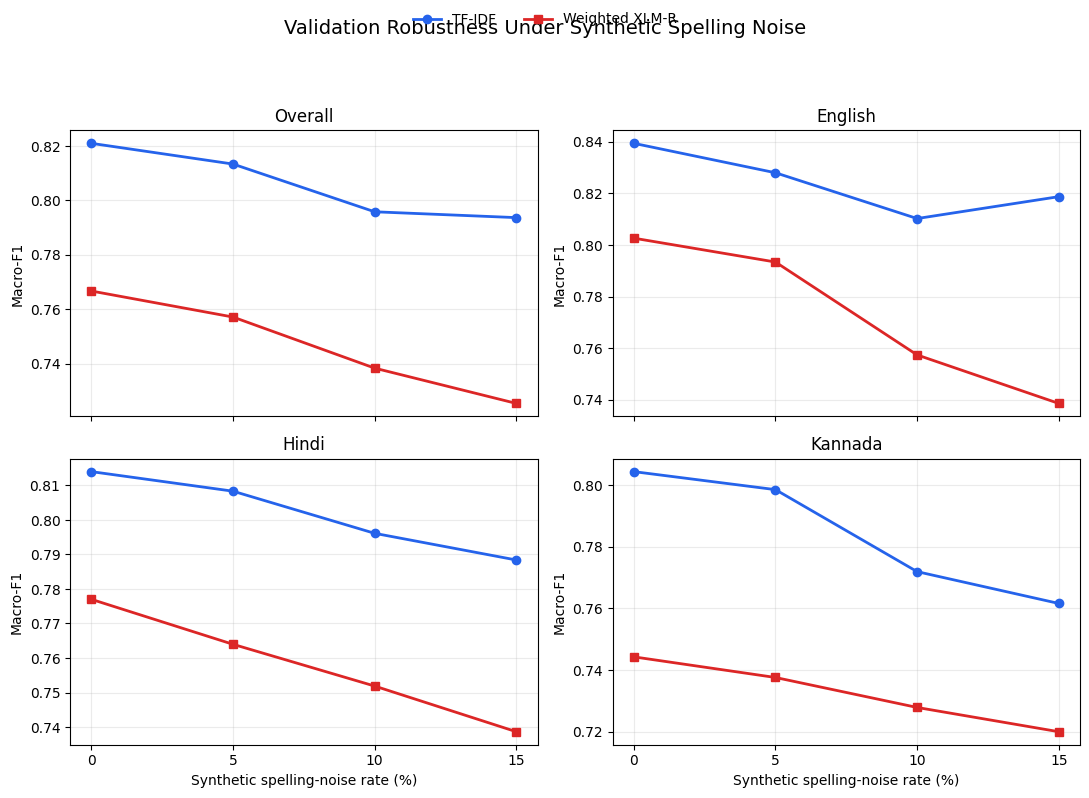

Figure saved: /content/robust-multilingual-intent-classification/results/figures/spelling_noise_robustness.png
Test set evaluated: False


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt

figure_dir = repo / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

model_styles = {
    "TF-IDF": {
        "color": "#2563eb",
        "marker": "o"
    },
    "Weighted XLM-R": {
        "color": "#dc2626",
        "marker": "s"
    }
}

panels = [
    ("Overall", robustness_results),
    (
        "English",
        language_robustness_results[
            language_robustness_results["locale"] == "en-US"
        ]
    ),
    (
        "Hindi",
        language_robustness_results[
            language_robustness_results["locale"] == "hi-IN"
        ]
    ),
    (
        "Kannada",
        language_robustness_results[
            language_robustness_results["locale"] == "kn-IN"
        ]
    ),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(11, 8),
    sharex=True
)

for axis, (title, frame) in zip(axes.flat, panels):
    for model_name, style in model_styles.items():
        model_results = (
            frame[frame["model"] == model_name]
            .sort_values("noise_rate")
        )

        axis.plot(
            model_results["noise_rate"] * 100,
            model_results["macro_f1"],
            label=model_name,
            color=style["color"],
            marker=style["marker"],
            linewidth=2,
            markersize=6,
        )

    axis.set_title(title)
    axis.set_ylabel("Macro-F1")
    axis.set_xticks([0, 5, 10, 15])
    axis.grid(alpha=0.25)

for axis in axes[1]:
    axis.set_xlabel("Synthetic spelling-noise rate (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Validation Robustness Under Synthetic Spelling Noise",
    fontsize=14,
    y=0.98
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

figure_path = (
    figure_dir /
    "spelling_noise_robustness.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)
print("Test set evaluated:", False)

In [16]:
from pathlib import Path
import subprocess

readme_path = repo / "README.md"

start_marker = "<!-- SPELLING_NOISE_RESULTS_START -->"
end_marker = "<!-- SPELLING_NOISE_RESULTS_END -->"

section = """<!-- SPELLING_NOISE_RESULTS_START -->
## Phase 3 — Synthetic spelling-noise robustness

We evaluated the TF-IDF baseline and class-weighted XLM-R on the known-intent validation set under deterministic Unicode-aware spelling noise.

Noise operations:

- Single-grapheme deletion
- Adjacent-grapheme transposition
- Rates of 5%, 10%, and 15% per eligible word
- Fixed random seed: 42
- Test set remained untouched

Changed validation utterances:

| Noise rate | Changed rows | Percentage |
|---:|---:|---:|
| 5% | 781 / 4,629 | 16.87% |
| 10% | 1,463 / 4,629 | 31.61% |
| 15% | 2,004 / 4,629 | 43.29% |

Overall validation results:

| Model | Noise rate | Accuracy | Macro-F1 | Macro-F1 drop |
|---|---:|---:|---:|---:|
| TF-IDF | 0% | 0.8369 | 0.8210 | 0.0000 |
| TF-IDF | 5% | 0.8283 | 0.8133 | 0.0076 |
| TF-IDF | 10% | 0.8177 | 0.7958 | 0.0252 |
| TF-IDF | 15% | 0.8062 | 0.7937 | 0.0273 |
| Weighted XLM-R | 0% | 0.8522 | 0.7667 | 0.0000 |
| Weighted XLM-R | 5% | 0.8365 | 0.7571 | 0.0096 |
| Weighted XLM-R | 10% | 0.8220 | 0.7383 | 0.0284 |
| Weighted XLM-R | 15% | 0.8075 | 0.7253 | 0.0413 |

Both models degrade under spelling noise. TF-IDF retains the stronger macro-F1, while weighted XLM-R retains slightly higher accuracy. These results measure robustness to controlled synthetic perturbations and should not be interpreted as performance on naturally occurring user typos.

![Spelling-noise robustness](results/figures/spelling_noise_robustness.png)
<!-- SPELLING_NOISE_RESULTS_END -->"""

readme = readme_path.read_text(encoding="utf-8")

if start_marker in readme and end_marker in readme:
    before = readme.split(start_marker)[0]
    after = readme.split(end_marker, 1)[1]
    readme = before + section + after
else:
    readme = readme.rstrip() + "\n\n" + section + "\n"

readme_path.write_text(readme, encoding="utf-8")

print("README updated:", readme_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
?? configs/spelling_noise.json
?? results/figures/spelling_noise_robustness.png
?? results/metrics/spelling_noise_validation_metrics.json



In [17]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

repo = Path("/content/robust-multilingual-intent-classification")

# Configure Git identity for this fresh runtime
subprocess.run(
    ["git", "config", "user.name", "sharath7-dev"],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "config",
        "user.email",
        "sharath7-dev@users.noreply.github.com",
    ],
    cwd=repo,
    check=True,
)

# Stage only the verified Phase 3 files
subprocess.run(
    [
        "git",
        "add",
        "README.md",
        "configs/spelling_noise.json",
        "results/figures/spelling_noise_robustness.png",
        "results/metrics/spelling_noise_validation_metrics.json",
    ],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "eval: add spelling-noise robustness results",
    ],
    cwd=repo,
    check=True,
)

# Authenticate securely without printing the token
token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found in Colab Secrets."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: b4484af eval: add spelling-noise robustness results
Status: ## main...origin/main


In [18]:
import subprocess

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print(pull.stdout)
print(pull.stderr)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("Status:", status.stdout.strip())

Updating b4484af..7d6975e
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 7989 ++++++++++++++-------
 1 file changed, 5272 insertions(+), 2717 deletions(-)

From https://github.com/sharath7-dev/robust-multilingual-intent-classification
 * branch            main       -> FETCH_HEAD
   b4484af..7d6975e  main       -> origin/main

Status: ## main...origin/main


In [19]:
import pandas as pd

TRAIN_NOISE_RATE = 0.10

noisy_training = train_known[
    ["id", "locale", "intent", "utt"]
].copy()

noisy_training["original_utt"] = noisy_training["utt"]

noisy_training["utt"] = [
    add_spelling_noise(
        text,
        locale,
        example_id,
        TRAIN_NOISE_RATE,
    )
    for text, locale, example_id in zip(
        noisy_training["original_utt"],
        noisy_training["locale"],
        noisy_training["id"],
    )
]

# Add only examples that were actually changed
noisy_training = noisy_training[
    noisy_training["utt"]
    != noisy_training["original_utt"]
].copy()

clean_training = train_known[
    ["id", "locale", "intent", "utt"]
].copy()

clean_training["source"] = "clean"
noisy_training["source"] = "synthetic_noise_10"

train_augmented = pd.concat(
    [
        clean_training[
            ["id", "locale", "intent", "utt", "source"]
        ],
        noisy_training[
            ["id", "locale", "intent", "utt", "source"]
        ],
    ],
    ignore_index=True,
)

print("Original training rows:", len(clean_training))
print("Noisy examples added:", len(noisy_training))
print("Augmented training rows:", len(train_augmented))

print("\nAdded noisy examples by language:")
print(noisy_training["locale"].value_counts().sort_index())

print(
    "\nOnly official training partition used:",
    set(clean_training["id"]).issubset(
        set(train_known["id"])
    )
)
print("Validation rows added:", False)
print("Test rows added:", False)

Original training rows: 26193
Noisy examples added: 8402
Augmented training rows: 34595

Added noisy examples by language:
locale
en-US    3558
hi-IN    1989
kn-IN    2855
Name: count, dtype: int64

Only official training partition used: True
Validation rows added: False
Test rows added: False


In [20]:
BALANCED_NOISY_PER_LANGUAGE = (
    noisy_training["locale"]
    .value_counts()
    .min()
)

noisy_training_balanced = (
    noisy_training
    .groupby("locale", group_keys=False)
    .sample(
        n=BALANCED_NOISY_PER_LANGUAGE,
        random_state=42
    )
    .reset_index(drop=True)
)

train_augmented = pd.concat(
    [
        clean_training[
            ["id", "locale", "intent", "utt", "source"]
        ],
        noisy_training_balanced[
            ["id", "locale", "intent", "utt", "source"]
        ],
    ],
    ignore_index=True,
)

print(
    "Noisy examples per language:",
    BALANCED_NOISY_PER_LANGUAGE
)
print(
    noisy_training_balanced["locale"]
    .value_counts()
    .sort_index()
)
print("Clean training rows:", len(clean_training))
print(
    "Balanced noisy rows:",
    len(noisy_training_balanced)
)
print(
    "Final augmented rows:",
    len(train_augmented)
)
print(
    "Final rows by language:"
)
print(
    train_augmented["locale"]
    .value_counts()
    .sort_index()
)
print("Validation/test data used:", False)

Noisy examples per language: 1989
locale
en-US    1989
hi-IN    1989
kn-IN    1989
Name: count, dtype: int64
Clean training rows: 26193
Balanced noisy rows: 5967
Final augmented rows: 32160
Final rows by language:
locale
en-US    10720
hi-IN    10720
kn-IN    10720
Name: count, dtype: int64
Validation/test data used: False


In [21]:
import numpy as np
from datasets import Dataset

# Convert intent names to fixed label IDs
train_augmented_model = train_augmented[
    ["utt", "intent"]
].copy()

validation_model = validation_known[
    ["utt", "intent"]
].copy()

train_augmented_model["labels"] = (
    train_augmented_model["intent"].map(label2id)
)

validation_model["labels"] = (
    validation_model["intent"].map(label2id)
)

assert train_augmented_model["labels"].notna().all()
assert validation_model["labels"].notna().all()

train_augmented_model["labels"] = (
    train_augmented_model["labels"].astype(int)
)

validation_model["labels"] = (
    validation_model["labels"].astype(int)
)

# Recalculate class weights using the augmented data
label_counts = np.bincount(
    train_augmented_model["labels"],
    minlength=50
)

augmented_class_weights = 1.0 / np.sqrt(label_counts)
augmented_class_weights /= augmented_class_weights.mean()

# Create Hugging Face datasets
augmented_train_dataset = Dataset.from_pandas(
    train_augmented_model[["utt", "labels"]],
    preserve_index=False
)

clean_validation_dataset = Dataset.from_pandas(
    validation_model[["utt", "labels"]],
    preserve_index=False
)


def tokenize_augmented_batch(batch):
    return weighted_tokenizer(
        batch["utt"],
        truncation=True,
        max_length=64,
    )


tokenized_augmented_train = augmented_train_dataset.map(
    tokenize_augmented_batch,
    batched=True,
    remove_columns=["utt"],
)

tokenized_clean_validation = clean_validation_dataset.map(
    tokenize_augmented_batch,
    batched=True,
    remove_columns=["utt"],
)

print(
    "Tokenized augmented training rows:",
    len(tokenized_augmented_train)
)
print(
    "Tokenized validation rows:",
    len(tokenized_clean_validation)
)
print(
    "Training columns:",
    tokenized_augmented_train.column_names
)
print(
    "Minimum augmented class weight:",
    round(float(augmented_class_weights.min()), 4)
)
print(
    "Maximum augmented class weight:",
    round(float(augmented_class_weights.max()), 4)
)
print("Missing training labels:", int((label_counts == 0).sum()))
print("Test set used:", False)

Map:   0%|          | 0/32160 [00:00<?, ? examples/s]

Map:   0%|          | 0/4629 [00:00<?, ? examples/s]

Tokenized augmented training rows: 32160
Tokenized validation rows: 4629
Training columns: ['labels', 'input_ids', 'attention_mask']
Minimum augmented class weight: 0.3194
Maximum augmented class weight: 4.4891
Missing training labels: 0
Test set used: False


In [22]:
import gc
import math
import torch
import torch.nn.functional as F

from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)
from sklearn.metrics import accuracy_score, f1_score

# Free GPU memory occupied by the saved baseline.
# The baseline remains available in CPU memory.
weighted_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

augmented_model = AutoModelForSequenceClassification.from_pretrained(
    "FacebookAI/xlm-roberta-base",
    num_labels=50,
    label2id=label2id,
    id2label=id2label,
)

data_collator = DataCollatorWithPadding(
    tokenizer=weighted_tokenizer
)


def compute_augmented_metrics(evaluation):
    predictions = evaluation.predictions.argmax(axis=-1)
    labels = evaluation.label_ids

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
    }


class AugmentedWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = torch.tensor(
            class_weights,
            dtype=torch.float32,
        )

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):
        labels = inputs.pop("labels")
        outputs = model(**inputs)

        loss = F.cross_entropy(
            outputs.logits,
            labels,
            weight=self.class_weights.to(
                outputs.logits.device
            ),
        )

        return (loss, outputs) if return_outputs else loss


steps_per_epoch = math.ceil(
    len(tokenized_augmented_train) / 16
)

total_steps = steps_per_epoch * 2
warmup_steps = round(total_steps * 0.10)

augmented_training_args = TrainingArguments(
    output_dir=str(
        repo / "models/xlmr_noise_augmented_checkpoints"
    ),
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    data_seed=42,
    report_to="none",
)

augmented_trainer = AugmentedWeightedTrainer(
    model=augmented_model,
    args=augmented_training_args,
    train_dataset=tokenized_augmented_train,
    eval_dataset=tokenized_clean_validation,
    processing_class=weighted_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_augmented_metrics,
    class_weights=augmented_class_weights,
)

print("Trainer created successfully:", True)
print("Training examples:", len(tokenized_augmented_train))
print("Validation examples:", len(tokenized_clean_validation))
print("Epochs:", 2)
print("Steps per epoch:", steps_per_epoch)
print("Approximate total steps:", total_steps)
print("Warmup steps:", warmup_steps)
print("FP16 enabled:", augmented_training_args.fp16)
print("Test set used:", False)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainer created successfully: True
Training examples: 32160
Validation examples: 4629
Epochs: 2
Steps per epoch: 2010
Approximate total steps: 4020
Warmup steps: 402
FP16 enabled: True
Test set used: False


In [23]:
import time

training_start = time.time()

augmented_training_output = augmented_trainer.train()

training_minutes = (
    time.time() - training_start
) / 60

print("\nNoise-augmented training completed.")
print(
    "Wall-clock time:",
    round(training_minutes, 1),
    "minutes"
)
print(
    "Best checkpoint:",
    augmented_trainer.state.best_model_checkpoint
)
print(
    "Best validation macro-F1:",
    augmented_trainer.state.best_metric
)
print("Test set used:", False)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.875680,0.740684,0.833009,0.767137
2,0.614879,0.582877,0.863685,0.822207


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Noise-augmented training completed.
Wall-clock time: 8.9 minutes
Best checkpoint: /content/robust-multilingual-intent-classification/models/xlmr_noise_augmented_checkpoints/checkpoint-4020
Best validation macro-F1: 0.8222069687116312
Test set used: False


In [24]:
def predict_augmented_xlmr(texts, batch_size=64):
    predicted_ids = []

    augmented_model = augmented_trainer.model
    augmented_model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = weighted_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to("cuda")

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = augmented_model(**encoded).logits

        predicted_ids.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    return [id2label[index] for index in predicted_ids]


augmented_rows = []
augmented_predictions = {}

for rate, texts in evaluation_sets.items():
    print(f"Evaluating augmented model at {rate:.0%} noise...")

    predictions = predict_augmented_xlmr(texts)
    augmented_predictions[rate] = predictions

    augmented_rows.append({
        "model": "Noise-Augmented XLM-R",
        "noise_rate": rate,
        "accuracy": accuracy_score(
            true_labels,
            predictions
        ),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
    })

augmented_results = pd.DataFrame(augmented_rows)

augmented_clean_f1 = augmented_results.loc[
    augmented_results["noise_rate"] == 0,
    "macro_f1"
].iloc[0]

augmented_results["macro_f1_drop"] = (
    augmented_clean_f1
    - augmented_results["macro_f1"]
)

robustness_comparison = pd.concat(
    [
        robustness_results,
        augmented_results
    ],
    ignore_index=True
)

print("\nComplete model comparison:")
print(
    robustness_comparison.to_string(
        index=False,
        formatters={
            "noise_rate": lambda value: f"{value:.0%}",
            "accuracy": lambda value: f"{value:.4f}",
            "macro_f1": lambda value: f"{value:.4f}",
            "macro_f1_drop": lambda value: f"{value:.4f}",
        },
    )
)

print("Test set evaluated:", False)

Evaluating augmented model at 0% noise...
Evaluating augmented model at 5% noise...
Evaluating augmented model at 10% noise...
Evaluating augmented model at 15% noise...

Complete model comparison:
                model noise_rate accuracy macro_f1 macro_f1_drop
               TF-IDF         0%   0.8369   0.8210        0.0000
       Weighted XLM-R         0%   0.8522   0.7667        0.0000
               TF-IDF         5%   0.8283   0.8133        0.0076
       Weighted XLM-R         5%   0.8365   0.7571        0.0096
               TF-IDF        10%   0.8177   0.7958        0.0252
       Weighted XLM-R        10%   0.8220   0.7383        0.0284
               TF-IDF        15%   0.8062   0.7937        0.0273
       Weighted XLM-R        15%   0.8075   0.7253        0.0413
Noise-Augmented XLM-R         0%   0.8635   0.8221        0.0000
Noise-Augmented XLM-R         5%   0.8516   0.8111        0.0110
Noise-Augmented XLM-R        10%   0.8404   0.7817        0.0405
Noise-Augmented XLM-R 

In [25]:
augmented_language_rows = []

for rate, predictions in augmented_predictions.items():
    prediction_array = np.array(predictions)

    for locale in ["en-US", "hi-IN", "kn-IN"]:
        mask = locale_array == locale

        augmented_language_rows.append({
            "model": "Noise-Augmented XLM-R",
            "noise_rate": rate,
            "locale": locale,
            "samples": int(mask.sum()),
            "accuracy": accuracy_score(
                true_array[mask],
                prediction_array[mask],
            ),
            "macro_f1": f1_score(
                true_array[mask],
                prediction_array[mask],
                average="macro",
                zero_division=0,
            ),
        })

augmented_language_results = pd.DataFrame(
    augmented_language_rows
)

augmented_clean_language_f1 = (
    augmented_language_results[
        augmented_language_results["noise_rate"] == 0
    ]
    .set_index("locale")["macro_f1"]
    .to_dict()
)

augmented_language_results["macro_f1_drop"] = (
    augmented_language_results.apply(
        lambda row: (
            augmented_clean_language_f1[row["locale"]]
            - row["macro_f1"]
        ),
        axis=1,
    )
)

complete_language_results = pd.concat(
    [
        language_robustness_results,
        augmented_language_results,
    ],
    ignore_index=True,
)

print(
    augmented_language_results.to_string(
        index=False,
        formatters={
            "noise_rate": lambda value: f"{value:.0%}",
            "accuracy": lambda value: f"{value:.4f}",
            "macro_f1": lambda value: f"{value:.4f}",
            "macro_f1_drop": lambda value: f"{value:.4f}",
        },
    )
)

print("\nTest set evaluated:", False)

                model noise_rate locale  samples accuracy macro_f1 macro_f1_drop
Noise-Augmented XLM-R         0%  en-US     1543   0.8808   0.8459        0.0000
Noise-Augmented XLM-R         0%  hi-IN     1543   0.8613   0.8147        0.0000
Noise-Augmented XLM-R         0%  kn-IN     1543   0.8483   0.8064        0.0000
Noise-Augmented XLM-R         5%  en-US     1543   0.8684   0.8344        0.0115
Noise-Augmented XLM-R         5%  hi-IN     1543   0.8529   0.8077        0.0070
Noise-Augmented XLM-R         5%  kn-IN     1543   0.8334   0.7926        0.0138
Noise-Augmented XLM-R        10%  en-US     1543   0.8561   0.8164        0.0295
Noise-Augmented XLM-R        10%  hi-IN     1543   0.8445   0.7793        0.0354
Noise-Augmented XLM-R        10%  kn-IN     1543   0.8205   0.7814        0.0250
Noise-Augmented XLM-R        15%  en-US     1543   0.8367   0.7941        0.0519
Noise-Augmented XLM-R        15%  hi-IN     1543   0.8360   0.7724        0.0423
Noise-Augmented XLM-R       

In [26]:
from pathlib import Path

augmented_drive_path = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models/"
    "xlmr_noise_augmented_final"
)

augmented_drive_path.mkdir(
    parents=True,
    exist_ok=True
)

augmented_trainer.save_model(
    str(augmented_drive_path)
)

weighted_tokenizer.save_pretrained(
    str(augmented_drive_path)
)

model_size_bytes = sum(
    file.stat().st_size
    for file in augmented_drive_path.rglob("*")
    if file.is_file()
)

print("Model saved to Drive:", augmented_drive_path)
print(
    "Model directory size:",
    round(model_size_bytes / 1024**3, 2),
    "GB"
)
print(
    "Model file exists:",
    (augmented_drive_path / "model.safetensors").is_file()
)
print("Test set evaluated:", False)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to Drive: /content/drive/MyDrive/robust_multilingual_intent/artifacts/models/xlmr_noise_augmented_final
Model directory size: 1.05 GB
Model file exists: True
Test set evaluated: False


In [27]:
import json
import subprocess

augmentation_config = {
    "base_model": "FacebookAI/xlm-roberta-base",
    "random_seed": 42,
    "clean_training_rows": 26193,
    "added_noisy_rows": 5967,
    "final_training_rows": 32160,
    "added_noisy_rows_per_language": {
        "en-US": 1989,
        "hi-IN": 1989,
        "kn-IN": 1989
    },
    "training_noise_rate": 0.10,
    "augmentation_strategy": (
        "clean training set plus balanced changed noisy copies"
    ),
    "noise_operations": [
        "single_grapheme_deletion",
        "adjacent_grapheme_transposition"
    ],
    "class_weighting": (
        "normalized square-root inverse class frequency"
    ),
    "epochs": 2,
    "learning_rate": 0.00002,
    "train_batch_size": 16,
    "evaluation_batch_size": 32,
    "weight_decay": 0.01,
    "warmup_steps": 402,
    "maximum_token_length": 64,
    "fp16": True,
    "selection_metric": "validation_macro_f1",
    "validation_only": True,
    "test_set_used": False
}

augmentation_metrics = {
    "dataset": "MASSIVE 1.1",
    "model": "Noise-Augmented XLM-R",
    "training_time_minutes": round(
        float(training_minutes),
        2
    ),
    "best_validation_macro_f1": round(
        float(augmented_trainer.state.best_metric),
        6
    ),
    "overall_results": json.loads(
        augmented_results.round(6).to_json(
            orient="records"
        )
    ),
    "per_language_results": json.loads(
        augmented_language_results.round(6).to_json(
            orient="records"
        )
    ),
    "complete_model_comparison": json.loads(
        robustness_comparison.round(6).to_json(
            orient="records"
        )
    ),
    "drive_model_location": (
        "MyDrive/robust_multilingual_intent/"
        "artifacts/models/xlmr_noise_augmented_final"
    ),
    "test_set_evaluated": False
}

augmentation_config_path = (
    repo / "configs/noise_augmentation.json"
)

augmentation_metrics_path = (
    repo / "results/metrics/"
    "xlmr_noise_augmented_validation_metrics.json"
)

with open(
    augmentation_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        augmentation_config,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(
    augmentation_metrics_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        augmentation_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Configuration saved:", augmentation_config_path)
print("Metrics saved:", augmentation_metrics_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Configuration saved: /content/robust-multilingual-intent-classification/configs/noise_augmentation.json
Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/xlmr_noise_augmented_validation_metrics.json

Git status:
?? configs/noise_augmentation.json
?? results/metrics/xlmr_noise_augmented_validation_metrics.json



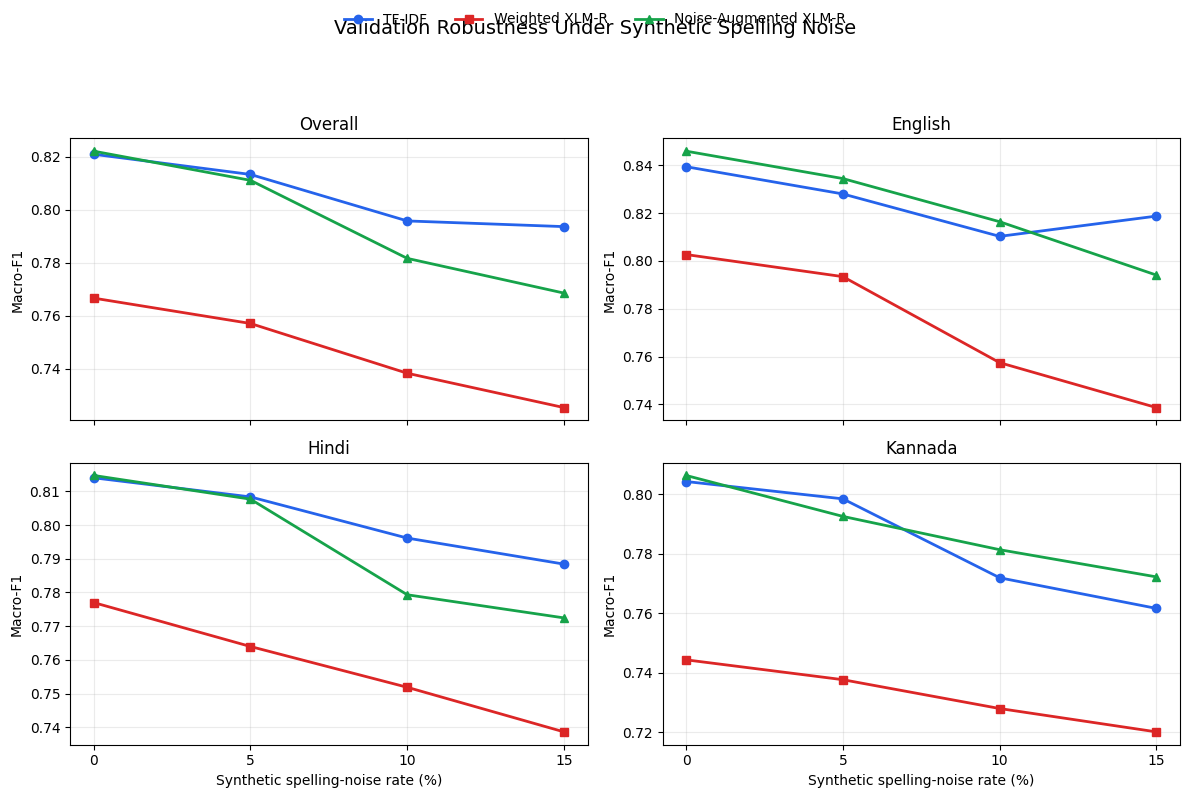

Updated figure saved: /content/robust-multilingual-intent-classification/results/figures/spelling_noise_robustness.png
Test set evaluated: False


In [28]:
import matplotlib.pyplot as plt

model_styles = {
    "TF-IDF": {
        "color": "#2563eb",
        "marker": "o"
    },
    "Weighted XLM-R": {
        "color": "#dc2626",
        "marker": "s"
    },
    "Noise-Augmented XLM-R": {
        "color": "#16a34a",
        "marker": "^"
    }
}

panels = [
    ("Overall", robustness_comparison),
    (
        "English",
        complete_language_results[
            complete_language_results["locale"] == "en-US"
        ]
    ),
    (
        "Hindi",
        complete_language_results[
            complete_language_results["locale"] == "hi-IN"
        ]
    ),
    (
        "Kannada",
        complete_language_results[
            complete_language_results["locale"] == "kn-IN"
        ]
    ),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    sharex=True
)

for axis, (title, frame) in zip(axes.flat, panels):
    for model_name, style in model_styles.items():
        model_results = (
            frame[frame["model"] == model_name]
            .sort_values("noise_rate")
        )

        axis.plot(
            model_results["noise_rate"] * 100,
            model_results["macro_f1"],
            label=model_name,
            color=style["color"],
            marker=style["marker"],
            linewidth=2,
            markersize=6,
        )

    axis.set_title(title)
    axis.set_ylabel("Macro-F1")
    axis.set_xticks([0, 5, 10, 15])
    axis.grid(alpha=0.25)

for axis in axes[1]:
    axis.set_xlabel("Synthetic spelling-noise rate (%)")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Validation Robustness Under Synthetic Spelling Noise",
    fontsize=14,
    y=0.98
)

fig.tight_layout(rect=[0, 0, 1, 0.92])

figure_path = (
    repo / "results/figures/"
    "spelling_noise_robustness.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Updated figure saved:", figure_path)
print("Test set evaluated:", False)

In [29]:
from pathlib import Path
import subprocess

readme_path = repo / "README.md"

start_marker = "<!-- SPELLING_NOISE_RESULTS_START -->"
end_marker = "<!-- SPELLING_NOISE_RESULTS_END -->"

section = """<!-- SPELLING_NOISE_RESULTS_START -->
## Phase 3 — Synthetic spelling-noise robustness

We evaluated three models on the known-intent validation set under deterministic Unicode-aware spelling noise:

- TF-IDF with logistic regression
- Class-weighted XLM-R
- Noise-augmented, class-weighted XLM-R

The perturbations use single-grapheme deletion and adjacent-grapheme transposition at rates of 5%, 10%, and 15% per eligible word. All experiments use random seed 42.

### Noise augmentation

The augmented XLM-R was trained using:

- 26,193 clean training examples
- 5,967 synthetic noisy copies
- 1,989 noisy copies per language
- 32,160 total training examples
- Two training epochs
- No validation or test examples in training

### Overall validation results

| Model | Noise | Accuracy | Macro-F1 | Drop from clean |
|---|---:|---:|---:|---:|
| TF-IDF | 0% | 0.8369 | 0.8210 | 0.0000 |
| TF-IDF | 5% | 0.8283 | 0.8133 | 0.0076 |
| TF-IDF | 10% | 0.8177 | 0.7958 | 0.0252 |
| TF-IDF | 15% | 0.8062 | 0.7937 | 0.0273 |
| Weighted XLM-R | 0% | 0.8522 | 0.7667 | 0.0000 |
| Weighted XLM-R | 5% | 0.8365 | 0.7571 | 0.0096 |
| Weighted XLM-R | 10% | 0.8220 | 0.7383 | 0.0284 |
| Weighted XLM-R | 15% | 0.8075 | 0.7253 | 0.0413 |
| Noise-Augmented XLM-R | 0% | 0.8635 | 0.8221 | 0.0000 |
| Noise-Augmented XLM-R | 5% | 0.8516 | 0.8111 | 0.0110 |
| Noise-Augmented XLM-R | 10% | 0.8404 | 0.7817 | 0.0405 |
| Noise-Augmented XLM-R | 15% | 0.8280 | 0.7685 | 0.0536 |

Noise augmentation improves XLM-R's absolute accuracy and macro-F1 at every evaluated noise level. However, the augmented model still degrades relative to its own stronger clean score. TF-IDF retains the highest macro-F1 at 5%, 10%, and 15% noise, while the augmented XLM-R has the highest accuracy.

These experiments use controlled synthetic perturbations and do not establish performance on naturally occurring spelling errors. The final test set remains untouched.

![Spelling-noise robustness](results/figures/spelling_noise_robustness.png)
<!-- SPELLING_NOISE_RESULTS_END -->"""

readme = readme_path.read_text(encoding="utf-8")

assert start_marker in readme
assert end_marker in readme

before = readme.split(start_marker, 1)[0]
after = readme.split(end_marker, 1)[1]

readme_path.write_text(
    before + section + after,
    encoding="utf-8"
)

print("README updated:", readme_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
 M results/figures/spelling_noise_robustness.png
?? configs/noise_augmentation.json
?? results/metrics/xlmr_noise_augmented_validation_metrics.json



In [30]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

files_to_commit = [
    "README.md",
    "results/figures/spelling_noise_robustness.png",
    "configs/noise_augmentation.json",
    "results/metrics/xlmr_noise_augmented_validation_metrics.json",
]

subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "model: evaluate noise-augmented XLM-R",
    ],
    cwd=repo,
    check=True,
)

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: dbb2368 model: evaluate noise-augmented XLM-R
Status: ## main...origin/main


In [32]:
import subprocess

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print(pull.stdout)
print(pull.stderr)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("Status:", status.stdout.strip())

Updating dbb2368..8bf41ce
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 12298 ++++++++++++++------
 1 file changed, 8524 insertions(+), 3774 deletions(-)

From https://github.com/sharath7-dev/robust-multilingual-intent-classification
 * branch            main       -> FETCH_HEAD
   dbb2368..8bf41ce  main       -> origin/main

Status: ## main...origin/main


In [33]:
!pip -q install indic-transliteration

from importlib.metadata import version
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate

print(
    "indic-transliteration version:",
    version("indic-transliteration")
)

hindi_example = "मुझे इस सप्ताह सुबह पांच बजे जगा दो"
kannada_example = "ಈ ವಾರ ಬೆಳಗ್ಗೆ ಐದು ಗಂಟೆಗೆ ನನ್ನನ್ನು ಎದ್ದೇಳಿ"

print(
    "\nHindi:",
    transliterate(
        hindi_example,
        sanscript.DEVANAGARI,
        sanscript.ITRANS
    )
)

print(
    "Kannada:",
    transliterate(
        kannada_example,
        sanscript.KANNADA,
        sanscript.ITRANS
    )
)

print("Test set used:", False)

indic-transliteration version: 2.3.82

Hindi: mujhe isa saptAha subaha pAMcha baje jagA do
Kannada: I vAra bèLaggè aidu gaMTègè nannannu èddeLi
Test set used: False


In [35]:
def simplify_transliteration(text):
    text = unicodedata.normalize("NFKD", text)

    text = "".join(
        character
        for character in text
        if not unicodedata.combining(character)
    )

    text = text.encode(
        "ascii",
        errors="ignore"
    ).decode("ascii")

    text = text.lower()

    # Convert ITRANS markers such as hu.n and kaha.n
    text = regex.sub(
        r"(?<=[a-z])\.(?=[a-z])",
        "",
        text
    )

    text = regex.sub(
        r"[^a-z0-9\s.,!?'\-]",
        " ",
        text
    )

    return " ".join(text.split())


# Regenerate using the corrected normalisation
transliterated_validation["utt_transliterated"] = [
    create_synthetic_transliteration(text, locale)
    for text, locale in zip(
        transliterated_validation["utt"],
        transliterated_validation["locale"],
    )
]

for locale in ["en-US", "hi-IN", "kn-IN"]:
    locale_rows = transliterated_validation[
        transliterated_validation["locale"] == locale
    ]

    changed = (
        locale_rows["utt"]
        != locale_rows["utt_transliterated"]
    ).sum()

    print(locale, "changed rows:", changed)

# Use the `regex` package directly for Unicode script checking
native_script_remaining = sum(
    bool(
        regex.search(
            r"\p{Script=Devanagari}|\p{Script=Kannada}",
            text
        )
    )
    for text in transliterated_validation.loc[
        transliterated_validation["locale"].isin(
            ["hi-IN", "kn-IN"]
        ),
        "utt_transliterated"
    ]
)

print(
    "Rows still containing Hindi/Kannada script:",
    native_script_remaining
)

print("\nCorrected Hindi samples:")
for _, row in (
    transliterated_validation[
        transliterated_validation["locale"] == "hi-IN"
    ]
    .sample(3, random_state=42)
    .iterrows()
):
    print(row["utt_transliterated"])

print("\nTest set used:", False)

en-US changed rows: 0
hi-IN changed rows: 1543
kn-IN changed rows: 1542
Rows still containing Hindi/Kannada script: 0

Corrected Hindi samples:
yunaiteda eyaralaimsa ko tvita bhejem maim naraza hun apane mera baiga kho diya
dilli ki akhiri train ka ticket phira se kharido
arjita simha ka ghara kahan hai

Test set used: False


In [36]:
import gc
import numpy as np
import pandas as pd

transliterated_texts = (
    transliterated_validation["utt_transliterated"].tolist()
)

# TF-IDF
print("Evaluating TF-IDF...")
tfidf_transliterated_predictions = (
    tfidf_model.predict(transliterated_texts).tolist()
)

# Noise-augmented XLM-R is currently on the GPU
print("Evaluating noise-augmented XLM-R...")
augmented_transliterated_predictions = (
    predict_augmented_xlmr(transliterated_texts)
)

# Swap models to avoid GPU memory problems
augmented_trainer.model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

weighted_model.to("cuda")

print("Evaluating weighted XLM-R...")
weighted_transliterated_predictions = (
    predict_weighted_xlmr(transliterated_texts)
)

# Restore the augmented model as the active GPU model
weighted_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()
augmented_trainer.model.to("cuda")

transliteration_predictions = {
    "TF-IDF": tfidf_transliterated_predictions,
    "Weighted XLM-R": weighted_transliterated_predictions,
    "Noise-Augmented XLM-R":
        augmented_transliterated_predictions,
}

clean_predictions = {
    "TF-IDF":
        robustness_predictions["TF-IDF"][0.00],
    "Weighted XLM-R":
        robustness_predictions["Weighted XLM-R"][0.00],
    "Noise-Augmented XLM-R":
        augmented_predictions[0.00],
}

evaluation_groups = {
    "all_languages": np.ones(
        len(validation_known),
        dtype=bool
    ),
    "english_control": locale_array == "en-US",
    "hindi_transliterated": locale_array == "hi-IN",
    "kannada_transliterated": locale_array == "kn-IN",
    "hindi_kannada_combined": np.isin(
        locale_array,
        ["hi-IN", "kn-IN"]
    ),
}

transliteration_rows = []

for model_name in transliteration_predictions:
    clean_array = np.array(
        clean_predictions[model_name]
    )

    transliterated_array = np.array(
        transliteration_predictions[model_name]
    )

    for group_name, mask in evaluation_groups.items():
        clean_macro_f1 = f1_score(
            true_array[mask],
            clean_array[mask],
            average="macro",
            zero_division=0,
        )

        transliterated_macro_f1 = f1_score(
            true_array[mask],
            transliterated_array[mask],
            average="macro",
            zero_division=0,
        )

        transliteration_rows.append({
            "model": model_name,
            "group": group_name,
            "samples": int(mask.sum()),
            "clean_accuracy": accuracy_score(
                true_array[mask],
                clean_array[mask],
            ),
            "transliterated_accuracy": accuracy_score(
                true_array[mask],
                transliterated_array[mask],
            ),
            "clean_macro_f1": clean_macro_f1,
            "transliterated_macro_f1":
                transliterated_macro_f1,
            "macro_f1_drop":
                clean_macro_f1
                - transliterated_macro_f1,
        })

transliteration_results = pd.DataFrame(
    transliteration_rows
)

print("\nTransliteration results:")
print(
    transliteration_results.to_string(
        index=False,
        formatters={
            "clean_accuracy":
                lambda value: f"{value:.4f}",
            "transliterated_accuracy":
                lambda value: f"{value:.4f}",
            "clean_macro_f1":
                lambda value: f"{value:.4f}",
            "transliterated_macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nTest set evaluated:", False)

Evaluating TF-IDF...
Evaluating noise-augmented XLM-R...
Evaluating weighted XLM-R...

Transliteration results:
                model                  group  samples clean_accuracy transliterated_accuracy clean_macro_f1 transliterated_macro_f1 macro_f1_drop
               TF-IDF          all_languages     4629         0.8369                  0.3573         0.8210                  0.4221        0.3989
               TF-IDF        english_control     1543         0.8594                  0.8594         0.8394                  0.8394        0.0000
               TF-IDF   hindi_transliterated     1543         0.8308                  0.1082         0.8140                  0.0769        0.7371
               TF-IDF kannada_transliterated     1543         0.8205                  0.1043         0.8043                  0.0532        0.7511
               TF-IDF hindi_kannada_combined     3086         0.8257                  0.1063         0.8121                  0.0700        0.7421
       Weigh

In [37]:
import json
import subprocess

transliteration_config = {
    "method": "synthetic deterministic transliteration",
    "library": "indic-transliteration",
    "library_version": "2.3.82",
    "source_scripts": {
        "hi-IN": "Devanagari",
        "kn-IN": "Kannada"
    },
    "target_scheme": "ITRANS",
    "normalization": [
        "Unicode NFKD normalization",
        "remove combining accents",
        "convert to ASCII",
        "lowercase",
        "remove specialist transliteration symbols",
        "collapse whitespace"
    ],
    "english_handling": "unchanged control",
    "validation_rows": 4629,
    "changed_rows": {
        "en-US": 0,
        "hi-IN": 1543,
        "kn-IN": 1542
    },
    "native_script_rows_remaining": 0,
    "limitation": (
        "Synthetic scholarly transliteration is not equivalent "
        "to naturally typed Romanized user text."
    ),
    "test_set_used": False
}

transliteration_metrics = {
    "dataset": "MASSIVE 1.1",
    "evaluation_split": "validation_known",
    "models": [
        "TF-IDF",
        "Weighted XLM-R",
        "Noise-Augmented XLM-R"
    ],
    "results": json.loads(
        transliteration_results.round(6).to_json(
            orient="records"
        )
    ),
    "english_control_unchanged": True,
    "test_set_evaluated": False
}

config_path = (
    repo / "configs/transliteration.json"
)

metrics_path = (
    repo / "results/metrics/"
    "transliteration_validation_metrics.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        transliteration_config,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(
        transliteration_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Configuration saved:", config_path)
print("Metrics saved:", metrics_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Configuration saved: /content/robust-multilingual-intent-classification/configs/transliteration.json
Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/transliteration_validation_metrics.json

Git status:
?? configs/transliteration.json
?? results/metrics/transliteration_validation_metrics.json



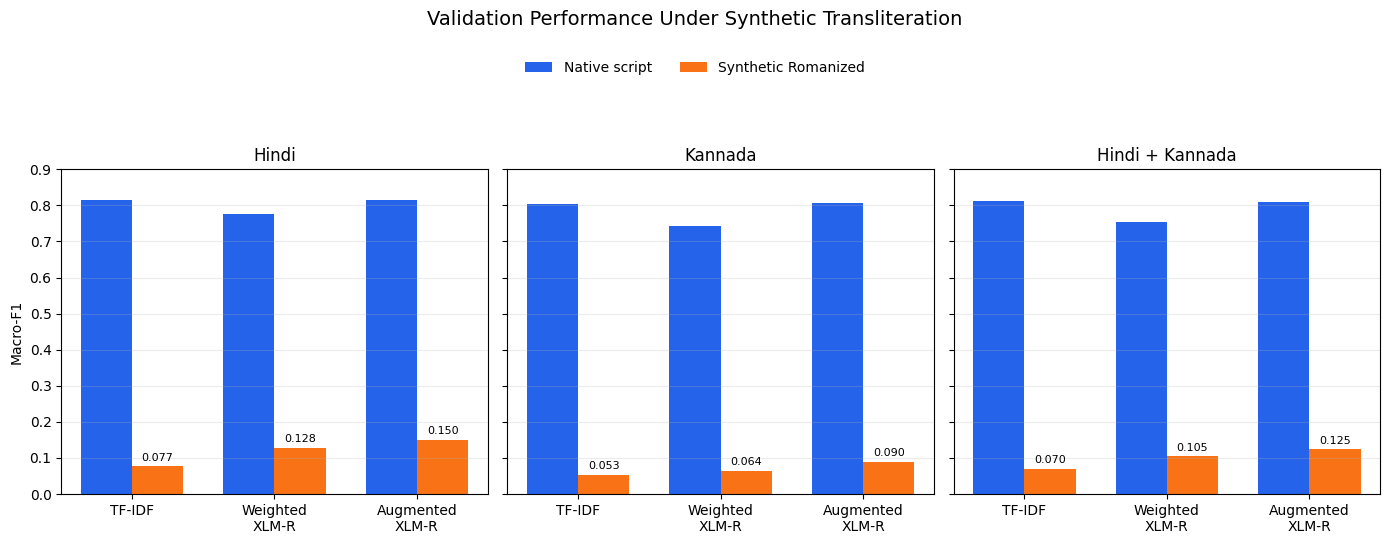

Corrected figure saved: /content/robust-multilingual-intent-classification/results/figures/transliteration_robustness.png


In [40]:
import matplotlib.pyplot as plt
import numpy as np

plot_groups = [
    ("hindi_transliterated", "Hindi"),
    ("kannada_transliterated", "Kannada"),
    ("hindi_kannada_combined", "Hindi + Kannada"),
]

model_order = [
    "TF-IDF",
    "Weighted XLM-R",
    "Noise-Augmented XLM-R",
]

short_model_names = [
    "TF-IDF",
    "Weighted\nXLM-R",
    "Augmented\nXLM-R",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 5.5),
    sharey=True
)

x = np.arange(len(model_order))
bar_width = 0.36

for axis, (group_key, title) in zip(
    axes,
    plot_groups
):
    group_results = (
        transliteration_results[
            transliteration_results["group"] == group_key
        ]
        .set_index("model")
        .loc[model_order]
    )

    clean_values = group_results[
        "clean_macro_f1"
    ].to_numpy()

    transliterated_values = group_results[
        "transliterated_macro_f1"
    ].to_numpy()

    axis.bar(
        x - bar_width / 2,
        clean_values,
        width=bar_width,
        label="Native script",
        color="#2563eb",
    )

    axis.bar(
        x + bar_width / 2,
        transliterated_values,
        width=bar_width,
        label="Synthetic Romanized",
        color="#f97316",
    )

    axis.set_title(title)
    axis.set_xticks(x)
    axis.set_xticklabels(short_model_names)
    axis.set_ylim(0, 0.9)
    axis.grid(axis="y", alpha=0.25)

    for position, value in zip(
        x + bar_width / 2,
        transliterated_values
    ):
        axis.text(
            position,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            fontsize=8,
        )

axes[0].set_ylabel("Macro-F1")

handles, labels = axes[0].get_legend_handles_labels()

fig.suptitle(
    "Validation Performance Under Synthetic Transliteration",
    fontsize=14,
    y=0.98
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.82])

figure_path = (
    repo / "results/figures/"
    "transliteration_robustness.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Corrected figure saved:", figure_path)

In [41]:
from pathlib import Path
import subprocess

readme_path = repo / "README.md"

start_marker = "<!-- TRANSLITERATION_RESULTS_START -->"
end_marker = "<!-- TRANSLITERATION_RESULTS_END -->"

section = """<!-- TRANSLITERATION_RESULTS_START -->
## Phase 4 — Synthetic transliteration robustness

Hindi and Kannada validation utterances were converted from their native scripts into simplified Latin text using `indic-transliteration` 2.3.82 with the ITRANS scheme and deterministic ASCII normalization. English was retained unchanged as a control.

The final test set was not evaluated.

### Macro-F1 results

| Model | Hindi native | Hindi Romanized | Kannada native | Kannada Romanized | Combined native | Combined Romanized |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF | 0.8140 | 0.0769 | 0.8043 | 0.0532 | 0.8121 | 0.0700 |
| Weighted XLM-R | 0.7770 | 0.1282 | 0.7443 | 0.0645 | 0.7552 | 0.1045 |
| Noise-Augmented XLM-R | 0.8147 | 0.1503 | 0.8064 | 0.0897 | 0.8101 | 0.1246 |

All three models show severe performance degradation on synthetic Romanized Hindi and Kannada. The noise-augmented XLM-R obtains the strongest Romanized macro-F1, but its combined score remains only 0.1246. English control results remain unchanged, supporting that the degradation is associated with the script transformation rather than an evaluation-order error.

This experiment uses deterministic scholarly transliteration followed by ASCII simplification. It does not represent the full variation of naturally typed Romanized Hindi or Kannada and should be interpreted as a controlled script-shift stress test.

![Transliteration robustness](results/figures/transliteration_robustness.png)
<!-- TRANSLITERATION_RESULTS_END -->"""

readme = readme_path.read_text(encoding="utf-8")

if start_marker in readme and end_marker in readme:
    before = readme.split(start_marker, 1)[0]
    after = readme.split(end_marker, 1)[1]
    readme = before + section + after
else:
    readme = readme.rstrip() + "\n\n" + section + "\n"

readme_path.write_text(
    readme,
    encoding="utf-8"
)

print("README updated:", readme_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
?? configs/transliteration.json
?? results/figures/transliteration_robustness.png
?? results/metrics/transliteration_validation_metrics.json



In [42]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

files_to_commit = [
    "README.md",
    "configs/transliteration.json",
    "results/figures/transliteration_robustness.png",
    "results/metrics/transliteration_validation_metrics.json",
]

subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "eval: add synthetic transliteration robustness results",
    ],
    cwd=repo,
    check=True,
)

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: ea34f6b eval: add synthetic transliteration robustness results
Status: ## main...origin/main


In [43]:
import subprocess

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print(pull.stdout)
print(pull.stderr)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("Status:", status.stdout.strip())

Updating ea34f6b..2014ed9
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 879 +++++++++++++++++++++-
 1 file changed, 872 insertions(+), 7 deletions(-)

From https://github.com/sharath7-dev/robust-multilingual-intent-classification
 * branch            main       -> FETCH_HEAD
   ea34f6b..2014ed9  main       -> origin/main

Status: ## main...origin/main


In [44]:
import hashlib


def assign_validation_subset(example_id):
    value = f"42|calibration_split|{example_id}".encode(
        "utf-8"
    )

    digest = hashlib.sha256(value).digest()
    fraction = int.from_bytes(
        digest[:8],
        byteorder="big"
    ) / 2**64

    return (
        "calibration"
        if fraction < 0.5
        else "evaluation"
    )


validation_known_with_subset = validation_known.copy()
validation_oos_with_subset = validation_oos.copy()

validation_known_with_subset["subset"] = (
    validation_known_with_subset["id"].map(
        assign_validation_subset
    )
)

validation_oos_with_subset["subset"] = (
    validation_oos_with_subset["id"].map(
        assign_validation_subset
    )
)

calibration_known = validation_known_with_subset[
    validation_known_with_subset["subset"]
    == "calibration"
].copy()

evaluation_known = validation_known_with_subset[
    validation_known_with_subset["subset"]
    == "evaluation"
].copy()

calibration_oos = validation_oos_with_subset[
    validation_oos_with_subset["subset"]
    == "calibration"
].copy()

evaluation_oos = validation_oos_with_subset[
    validation_oos_with_subset["subset"]
    == "evaluation"
].copy()

print("Calibration known:", len(calibration_known))
print(
    calibration_known["locale"]
    .value_counts()
    .sort_index()
)

print("\nEvaluation known:", len(evaluation_known))
print(
    evaluation_known["locale"]
    .value_counts()
    .sort_index()
)

print("\nCalibration OOS:", len(calibration_oos))
print(
    calibration_oos["locale"]
    .value_counts()
    .sort_index()
)

print("\nEvaluation OOS:", len(evaluation_oos))
print(
    evaluation_oos["locale"]
    .value_counts()
    .sort_index()
)

calibration_ids = set(
    calibration_known["id"]
).union(calibration_oos["id"])

evaluation_ids = set(
    evaluation_known["id"]
).union(evaluation_oos["id"])

print(
    "\nID overlap:",
    calibration_ids.intersection(evaluation_ids)
)
print(
    "Known intents represented in calibration:",
    calibration_known["intent"].nunique()
)
print(
    "Known intents represented in evaluation:",
    evaluation_known["intent"].nunique()
)
print(
    "All validation rows preserved:",
    (
        len(calibration_known)
        + len(evaluation_known)
        == len(validation_known)
    )
    and (
        len(calibration_oos)
        + len(evaluation_oos)
        == len(validation_oos)
    )
)
print("Test set evaluated:", False)

Calibration known: 2343
locale
en-US    781
hi-IN    781
kn-IN    781
Name: count, dtype: int64

Evaluation known: 2286
locale
en-US    762
hi-IN    762
kn-IN    762
Name: count, dtype: int64

Calibration OOS: 291
locale
en-US    97
hi-IN    97
kn-IN    97
Name: count, dtype: int64

Evaluation OOS: 249
locale
en-US    83
hi-IN    83
kn-IN    83
Name: count, dtype: int64

ID overlap: set()
Known intents represented in calibration: 46
Known intents represented in evaluation: 49
All validation rows preserved: True
Test set evaluated: False


In [45]:
# Ensure every known intent appears in the evaluation subset
all_known_intents = set(
    validation_known_with_subset["intent"].unique()
)

evaluation_known_intents = set(
    validation_known_with_subset.loc[
        validation_known_with_subset["subset"]
        == "evaluation",
        "intent"
    ]
)

missing_evaluation_intents = (
    all_known_intents
    - evaluation_known_intents
)

print(
    "Missing evaluation intents before repair:",
    sorted(missing_evaluation_intents)
)

for intent in sorted(missing_evaluation_intents):
    candidate_id = (
        validation_known_with_subset.loc[
            (
                validation_known_with_subset["intent"]
                == intent
            )
            & (
                validation_known_with_subset["subset"]
                == "calibration"
            ),
            "id"
        ]
        .iloc[0]
    )

    validation_known_with_subset.loc[
        validation_known_with_subset["id"]
        == candidate_id,
        "subset"
    ] = "evaluation"

# Reconstruct the known subsets
calibration_known = validation_known_with_subset[
    validation_known_with_subset["subset"]
    == "calibration"
].copy()

evaluation_known = validation_known_with_subset[
    validation_known_with_subset["subset"]
    == "evaluation"
].copy()

calibration_ids = set(
    calibration_known["id"]
).union(calibration_oos["id"])

evaluation_ids = set(
    evaluation_known["id"]
).union(evaluation_oos["id"])

print("\nCalibration known:", len(calibration_known))
print("Evaluation known:", len(evaluation_known))
print(
    "Calibration known intents:",
    calibration_known["intent"].nunique()
)
print(
    "Evaluation known intents:",
    evaluation_known["intent"].nunique()
)
print(
    "Evaluation OOS intents:",
    evaluation_oos["intent"].nunique()
)
print(
    "ID overlap:",
    calibration_ids.intersection(evaluation_ids)
)
print(
    "All known validation rows preserved:",
    (
        len(calibration_known)
        + len(evaluation_known)
        == len(validation_known)
    )
)
print("Test set evaluated:", False)

Missing evaluation intents before repair: []

Calibration known: 2343
Evaluation known: 2286
Calibration known intents: 46
Evaluation known intents: 49
Evaluation OOS intents: 5
ID overlap: set()
All known validation rows preserved: True
Test set evaluated: False


In [46]:
configured_known_intents = set(known_intents)
validation_available_intents = set(
    validation_known["intent"].unique()
)

absent_from_validation = (
    configured_known_intents
    - validation_available_intents
)

print(
    "Configured known intents:",
    len(configured_known_intents)
)
print(
    "Known intents present in validation:",
    len(validation_available_intents)
)
print(
    "Known intents absent from validation:",
    sorted(absent_from_validation)
)

for intent in sorted(absent_from_validation):
    print(
        intent,
        "training rows:",
        int(
            (train_known["intent"] == intent).sum()
        )
    )

print("Test set evaluated:", False)

Configured known intents: 50
Known intents present in validation: 49
Known intents absent from validation: ['audio_volume_other']
audio_volume_other training rows: 54
Test set evaluated: False


In [47]:
import gc
import numpy as np
import pandas as pd
import torch
from scipy.special import softmax

validation_detection_data = pd.concat(
    [
        validation_known_with_subset[
            ["id", "locale", "intent", "utt", "subset"]
        ].assign(is_oos=0),
        validation_oos_with_subset[
            ["id", "locale", "intent", "utt", "subset"]
        ].assign(is_oos=1),
    ],
    ignore_index=True,
)

detection_texts = (
    validation_detection_data["utt"].tolist()
)


def collect_xlmr_logits(model, texts, batch_size=64):
    collected_logits = []
    model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = weighted_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to("cuda")

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(**encoded).logits

        collected_logits.append(
            logits.float().cpu().numpy()
        )

    return np.concatenate(
        collected_logits,
        axis=0
    )


# TF-IDF probabilities
print("Collecting TF-IDF confidence scores...")

tfidf_probabilities = tfidf_model.predict_proba(
    detection_texts
)

tfidf_classes = np.array(
    tfidf_model.named_steps["classifier"].classes_
)

# Augmented XLM-R
print("Collecting noise-augmented XLM-R logits...")

augmented_model = augmented_trainer.model
augmented_model.to("cuda")

augmented_logits = collect_xlmr_logits(
    augmented_model,
    detection_texts
)

# Swap models to stay within GPU memory
augmented_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

weighted_model.to("cuda")

print("Collecting weighted XLM-R logits...")

weighted_logits = collect_xlmr_logits(
    weighted_model,
    detection_texts
)

weighted_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()
augmented_model.to("cuda")

weighted_probabilities = softmax(
    weighted_logits,
    axis=1
)

augmented_probabilities = softmax(
    augmented_logits,
    axis=1
)

detection_outputs = {
    "TF-IDF": {
        "logits": np.log(
            np.clip(
                tfidf_probabilities,
                1e-12,
                1.0
            )
        ),
        "probabilities": tfidf_probabilities,
        "classes": tfidf_classes,
    },
    "Weighted XLM-R": {
        "logits": weighted_logits,
        "probabilities": weighted_probabilities,
        "classes": np.array(
            [id2label[index] for index in range(50)]
        ),
    },
    "Noise-Augmented XLM-R": {
        "logits": augmented_logits,
        "probabilities": augmented_probabilities,
        "classes": np.array(
            [id2label[index] for index in range(50)]
        ),
    },
}

known_mask = (
    validation_detection_data["is_oos"].to_numpy()
    == 0
)

oos_mask = ~known_mask

print("\nConfidence summary:")

for model_name, output in detection_outputs.items():
    confidence = output[
        "probabilities"
    ].max(axis=1)

    print(f"\n{model_name}")
    print(
        "Mean known confidence:",
        round(float(confidence[known_mask].mean()), 4)
    )
    print(
        "Mean OOS confidence:",
        round(float(confidence[oos_mask].mean()), 4)
    )
    print(
        "Output shape:",
        output["probabilities"].shape
    )

print("\nValidation rows:", len(validation_detection_data))
print("Test set evaluated:", False)


Confidence summary:

TF-IDF
Mean known confidence: 0.7492
Mean OOS confidence: 0.5997
Output shape: (5169, 50)

Weighted XLM-R
Mean known confidence: 0.839
Mean OOS confidence: 0.7143
Output shape: (5169, 50)

Noise-Augmented XLM-R
Mean known confidence: 0.8707
Mean OOS confidence: 0.7339
Output shape: (5169, 50)

Validation rows: 5169
Test set evaluated: False


In [48]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize_scalar
from scipy.special import softmax


def negative_log_likelihood(
    probabilities,
    true_indices
):
    selected = probabilities[
        np.arange(len(true_indices)),
        true_indices
    ]

    return float(
        -np.log(
            np.clip(selected, 1e-12, 1.0)
        ).mean()
    )


def expected_calibration_error(
    probabilities,
    true_indices,
    bins=15
):
    confidence = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    correct = predictions == true_indices

    boundaries = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for index in range(bins):
        lower = boundaries[index]
        upper = boundaries[index + 1]

        if index == 0:
            in_bin = (
                (confidence >= lower)
                & (confidence <= upper)
            )
        else:
            in_bin = (
                (confidence > lower)
                & (confidence <= upper)
            )

        if in_bin.any():
            bin_accuracy = correct[in_bin].mean()
            bin_confidence = confidence[in_bin].mean()

            ece += (
                in_bin.mean()
                * abs(
                    bin_accuracy
                    - bin_confidence
                )
            )

    return float(ece)


calibration_known_mask = (
    (
        validation_detection_data["subset"]
        == "calibration"
    )
    & (
        validation_detection_data["is_oos"]
        == 0
    )
).to_numpy()

evaluation_known_mask = (
    (
        validation_detection_data["subset"]
        == "evaluation"
    )
    & (
        validation_detection_data["is_oos"]
        == 0
    )
).to_numpy()

temperature_rows = []

for model_name, output in detection_outputs.items():
    classes = output["classes"]
    class_to_index = {
        label: index
        for index, label in enumerate(classes)
    }

    all_true_indices = np.array([
        class_to_index.get(intent, -1)
        for intent in validation_detection_data["intent"]
    ])

    calibration_true = all_true_indices[
        calibration_known_mask
    ]

    evaluation_true = all_true_indices[
        evaluation_known_mask
    ]

    calibration_logits = output["logits"][
        calibration_known_mask
    ]

    evaluation_logits = output["logits"][
        evaluation_known_mask
    ]

    def temperature_objective(temperature):
        probabilities = softmax(
            calibration_logits / temperature,
            axis=1
        )

        return negative_log_likelihood(
            probabilities,
            calibration_true
        )

    optimization = minimize_scalar(
        temperature_objective,
        bounds=(0.05, 10.0),
        method="bounded",
        options={"xatol": 1e-4},
    )

    temperature = float(optimization.x)

    uncalibrated_evaluation = softmax(
        evaluation_logits,
        axis=1
    )

    calibrated_evaluation = softmax(
        evaluation_logits / temperature,
        axis=1
    )

    output["temperature"] = temperature
    output["calibrated_probabilities"] = softmax(
        output["logits"] / temperature,
        axis=1
    )

    temperature_rows.append({
        "model": model_name,
        "temperature": temperature,
        "evaluation_nll_before":
            negative_log_likelihood(
                uncalibrated_evaluation,
                evaluation_true
            ),
        "evaluation_nll_after":
            negative_log_likelihood(
                calibrated_evaluation,
                evaluation_true
            ),
        "evaluation_ece_before":
            expected_calibration_error(
                uncalibrated_evaluation,
                evaluation_true
            ),
        "evaluation_ece_after":
            expected_calibration_error(
                calibrated_evaluation,
                evaluation_true
            ),
        "evaluation_accuracy":
            float(
                (
                    calibrated_evaluation.argmax(axis=1)
                    == evaluation_true
                ).mean()
            ),
    })

temperature_results = pd.DataFrame(
    temperature_rows
)

print(
    temperature_results.to_string(
        index=False,
        formatters={
            "temperature":
                lambda value: f"{value:.4f}",
            "evaluation_nll_before":
                lambda value: f"{value:.4f}",
            "evaluation_nll_after":
                lambda value: f"{value:.4f}",
            "evaluation_ece_before":
                lambda value: f"{value:.4f}",
            "evaluation_ece_after":
                lambda value: f"{value:.4f}",
            "evaluation_accuracy":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nCalibration-known rows:", calibration_known_mask.sum())
print("Evaluation-known rows:", evaluation_known_mask.sum())
print("Test set evaluated:", False)

                model temperature evaluation_nll_before evaluation_nll_after evaluation_ece_before evaluation_ece_after evaluation_accuracy
               TF-IDF      0.7398                0.6917               0.6381                0.0938               0.0184              0.8355
       Weighted XLM-R      0.9204                0.6228               0.6177                0.0319               0.0266              0.8430
Noise-Augmented XLM-R      0.9655                0.5761               0.5757                0.0187               0.0259              0.8574

Calibration-known rows: 2343
Evaluation-known rows: 2286
Test set evaluated: False


In [64]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)

calibration_mask = (
    validation_detection_data["subset"]
    == "calibration"
).to_numpy()

evaluation_mask = (
    validation_detection_data["subset"]
    == "evaluation"
).to_numpy()

is_oos = (
    validation_detection_data["is_oos"]
    .to_numpy()
    .astype(int)
)

true_intents_all = (
    validation_detection_data["intent"]
    .to_numpy()
)

threshold_rows = []
oos_evaluation_predictions = {}

threshold_grid = np.linspace(
    0.0,
    1.0,
    1001
)

for model_name, output in detection_outputs.items():
    probabilities = output[
        "calibrated_probabilities"
    ]

    confidence = probabilities.max(axis=1)
    predicted_indices = probabilities.argmax(axis=1)
    predicted_intents = output["classes"][
        predicted_indices
    ]

    calibration_confidence = confidence[
        calibration_mask
    ]

    calibration_oos = is_oos[
        calibration_mask
    ]

    # Choose the confidence threshold that maximizes
    # binary known-vs-OOS macro-F1 on calibration data.
    calibration_scores = []

    for threshold in threshold_grid:
        predicted_oos = (
            calibration_confidence < threshold
        ).astype(int)

        score = f1_score(
            calibration_oos,
            predicted_oos,
            average="macro",
            zero_division=0,
        )

        calibration_scores.append(score)

    best_index = int(
        np.argmax(calibration_scores)
    )

    best_threshold = float(
        threshold_grid[best_index]
    )

    evaluation_confidence = confidence[
        evaluation_mask
    ]

    evaluation_oos = is_oos[
        evaluation_mask
    ]

    evaluation_predicted_oos = (
        evaluation_confidence < best_threshold
    ).astype(int)

    oos_scores = 1.0 - evaluation_confidence

    precision, recall, oos_f1, _ = (
        precision_recall_fscore_support(
            evaluation_oos,
            evaluation_predicted_oos,
            average="binary",
            zero_division=0,
        )
    )

    fpr, tpr, _ = roc_curve(
        evaluation_oos,
        oos_scores
    )

    eligible_fpr = fpr[tpr >= 0.95]
    fpr_at_95_tpr = (
        float(eligible_fpr.min())
        if len(eligible_fpr)
        else 1.0
    )

    evaluation_known = evaluation_oos == 0
    accepted_known = (
        evaluation_known
        & (evaluation_predicted_oos == 0)
    )

    evaluation_predicted_intents = (
        predicted_intents[evaluation_mask]
    )

    evaluation_true_intents = (
        true_intents_all[evaluation_mask]
    )

    selective_accuracy = (
        accuracy_score(
            evaluation_true_intents[accepted_known],
            evaluation_predicted_intents[accepted_known],
        )
        if accepted_known.any()
        else float("nan")
    )

    threshold_rows.append({
        "model": model_name,
        "threshold": best_threshold,
        "calibration_binary_macro_f1":
            calibration_scores[best_index],
        "evaluation_auroc": roc_auc_score(
            evaluation_oos,
            oos_scores
        ),
        "evaluation_aupr_oos":
            average_precision_score(
                evaluation_oos,
                oos_scores
            ),
        "evaluation_fpr_at_95_tpr":
            fpr_at_95_tpr,
        "evaluation_binary_accuracy":
            accuracy_score(
                evaluation_oos,
                evaluation_predicted_oos
            ),
        "evaluation_balanced_accuracy":
            balanced_accuracy_score(
                evaluation_oos,
                evaluation_predicted_oos
            ),
        "evaluation_binary_macro_f1":
            f1_score(
                evaluation_oos,
                evaluation_predicted_oos,
                average="macro",
                zero_division=0,
            ),
        "oos_precision": precision,
        "oos_recall": recall,
        "oos_f1": oos_f1,
        "known_coverage":
            float(accepted_known.sum())
            / float(evaluation_known.sum()),
        "selective_known_accuracy":
            selective_accuracy,
    })

    oos_evaluation_predictions[model_name] = {
        "confidence": evaluation_confidence,
        "predicted_oos": evaluation_predicted_oos,
        "true_oos": evaluation_oos,
        "predicted_intent":
            evaluation_predicted_intents,
        "true_intent":
            evaluation_true_intents,
    }

threshold_results = pd.DataFrame(
    threshold_rows
)

print(
    threshold_results.to_string(
        index=False,
        formatters={
            column: (
                lambda value: f"{value:.4f}"
            )
            for column in threshold_results.columns
            if column != "model"
        },
    )
)

print("\nCalibration rows:", calibration_mask.sum())
print("Evaluation rows:", evaluation_mask.sum())
print("Test set evaluated:", False)

                   model threshold calibration_binary_macro_f1 evaluation_auroc evaluation_aupr_oos evaluation_fpr_at_95_tpr evaluation_binary_accuracy evaluation_balanced_accuracy evaluation_binary_macro_f1 oos_precision oos_recall oos_f1 known_coverage selective_known_accuracy
                  TF-IDF    0.5360                      0.5765           0.6717              0.1524                   0.8027                     0.7941                       0.5512                     0.5370        0.1562     0.2490 0.1920         0.8535                   0.9113
          Weighted XLM-R    0.5670                      0.5866           0.6693              0.1739                   0.8377                     0.8347                       0.5612                     0.5578        0.1964     0.2209 0.2079         0.9016                   0.9044
   Noise-Augmented XLM-R    0.7970                      0.6132           0.6960              0.2050                   0.7550                     0.7775         

In [65]:
evaluation_locales = (
    validation_detection_data.loc[
        evaluation_mask,
        "locale"
    ]
    .to_numpy()
)

threshold_by_model = (
    threshold_results
    .set_index("model")["threshold"]
    .to_dict()
)

language_oos_rows = []

for model_name, predictions in (
    oos_evaluation_predictions.items()
):
    true_oos = predictions["true_oos"]
    predicted_oos = predictions["predicted_oos"]
    confidence = predictions["confidence"]
    predicted_intent = predictions["predicted_intent"]
    true_intent = predictions["true_intent"]

    for locale in ["en-US", "hi-IN", "kn-IN"]:
        locale_mask = evaluation_locales == locale

        locale_true_oos = true_oos[locale_mask]
        locale_predicted_oos = predicted_oos[locale_mask]
        locale_scores = (
            1.0 - confidence[locale_mask]
        )

        precision, recall, oos_f1, _ = (
            precision_recall_fscore_support(
                locale_true_oos,
                locale_predicted_oos,
                average="binary",
                zero_division=0,
            )
        )

        locale_known = locale_true_oos == 0
        locale_accepted_known = (
            locale_known
            & (locale_predicted_oos == 0)
        )

        selective_accuracy = accuracy_score(
            true_intent[locale_mask][
                locale_accepted_known
            ],
            predicted_intent[locale_mask][
                locale_accepted_known
            ],
        )

        language_oos_rows.append({
            "model": model_name,
            "locale": locale,
            "samples": int(locale_mask.sum()),
            "threshold":
                threshold_by_model[model_name],
            "auroc": roc_auc_score(
                locale_true_oos,
                locale_scores
            ),
            "aupr_oos":
                average_precision_score(
                    locale_true_oos,
                    locale_scores
                ),
            "binary_macro_f1":
                f1_score(
                    locale_true_oos,
                    locale_predicted_oos,
                    average="macro",
                    zero_division=0,
                ),
            "oos_precision": precision,
            "oos_recall": recall,
            "oos_f1": oos_f1,
            "known_coverage":
                float(locale_accepted_known.sum())
                / float(locale_known.sum()),
            "selective_known_accuracy":
                selective_accuracy,
        })

language_oos_results = pd.DataFrame(
    language_oos_rows
)

print(
    language_oos_results.to_string(
        index=False,
        formatters={
            column: (
                lambda value: f"{value:.4f}"
            )
            for column in language_oos_results.columns
            if column not in [
                "model",
                "locale",
                "samples"
            ]
        },
    )
)

print("\nTest set evaluated:", False)

                   model locale  samples threshold  auroc aupr_oos binary_macro_f1 oos_precision oos_recall oos_f1 known_coverage selective_known_accuracy
                  TF-IDF  en-US      845    0.5360 0.6902   0.1673          0.5408        0.1636     0.2169 0.1865         0.8793                   0.9149
                  TF-IDF  hi-IN      845    0.5360 0.6629   0.1610          0.5410        0.1618     0.2651 0.2009         0.8504                   0.9136
                  TF-IDF  kn-IN      845    0.5360 0.6622   0.1451          0.5288        0.1457     0.2651 0.1880         0.8307                   0.9052
          Weighted XLM-R  en-US      845    0.5670 0.6772   0.2053          0.5824        0.2500     0.2410 0.2454         0.9213                   0.9160
          Weighted XLM-R  hi-IN      845    0.5670 0.7020   0.2081          0.5370        0.1613     0.1807 0.1705         0.8976                   0.9050
          Weighted XLM-R  kn-IN      845    0.5670 0.6288   0.1463    

In [51]:
import json
import subprocess

oos_config = {
    "method": "maximum calibrated class probability",
    "oos_score": "1 - maximum calibrated probability",
    "validation_partition_method": (
        "SHA-256 deterministic split grouped by parallel ID"
    ),
    "random_seed": 42,
    "calibration_rows": {
        "known": int(calibration_known_mask.sum()),
        "oos": int(
            (
                calibration_mask
                & (is_oos == 1)
            ).sum()
        )
    },
    "evaluation_rows": {
        "known": int(evaluation_known_mask.sum()),
        "oos": int(
            (
                evaluation_mask
                & (is_oos == 1)
            ).sum()
        )
    },
    "temperature_fitting_data": (
        "calibration-known examples only"
    ),
    "threshold_selection_data": (
        "calibration known and OOS examples"
    ),
    "threshold_objective": (
        "maximize binary known-vs-OOS macro-F1"
    ),
    "threshold_grid_points": 1001,
    "ece_bins": 15,
    "configured_known_intents": 50,
    "known_intents_present_in_validation": 49,
    "known_intent_absent_from_validation":
        "audio_volume_other",
    "test_set_used": False
}

oos_metrics = {
    "dataset": "MASSIVE 1.1",
    "temperature_results": json.loads(
        temperature_results.round(6).to_json(
            orient="records"
        )
    ),
    "overall_oos_results": json.loads(
        threshold_results.round(6).to_json(
            orient="records"
        )
    ),
    "per_language_oos_results": json.loads(
        language_oos_results.round(6).to_json(
            orient="records"
        )
    ),
    "test_set_evaluated": False
}

config_path = (
    repo / "configs/oos_calibration.json"
)

metrics_path = (
    repo / "results/metrics/"
    "oos_calibration_validation_metrics.json"
)

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(
        oos_config,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(
        oos_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Configuration saved:", config_path)
print("Metrics saved:", metrics_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Configuration saved: /content/robust-multilingual-intent-classification/configs/oos_calibration.json
Metrics saved: /content/robust-multilingual-intent-classification/results/metrics/oos_calibration_validation_metrics.json

Git status:
?? configs/oos_calibration.json
?? results/metrics/oos_calibration_validation_metrics.json



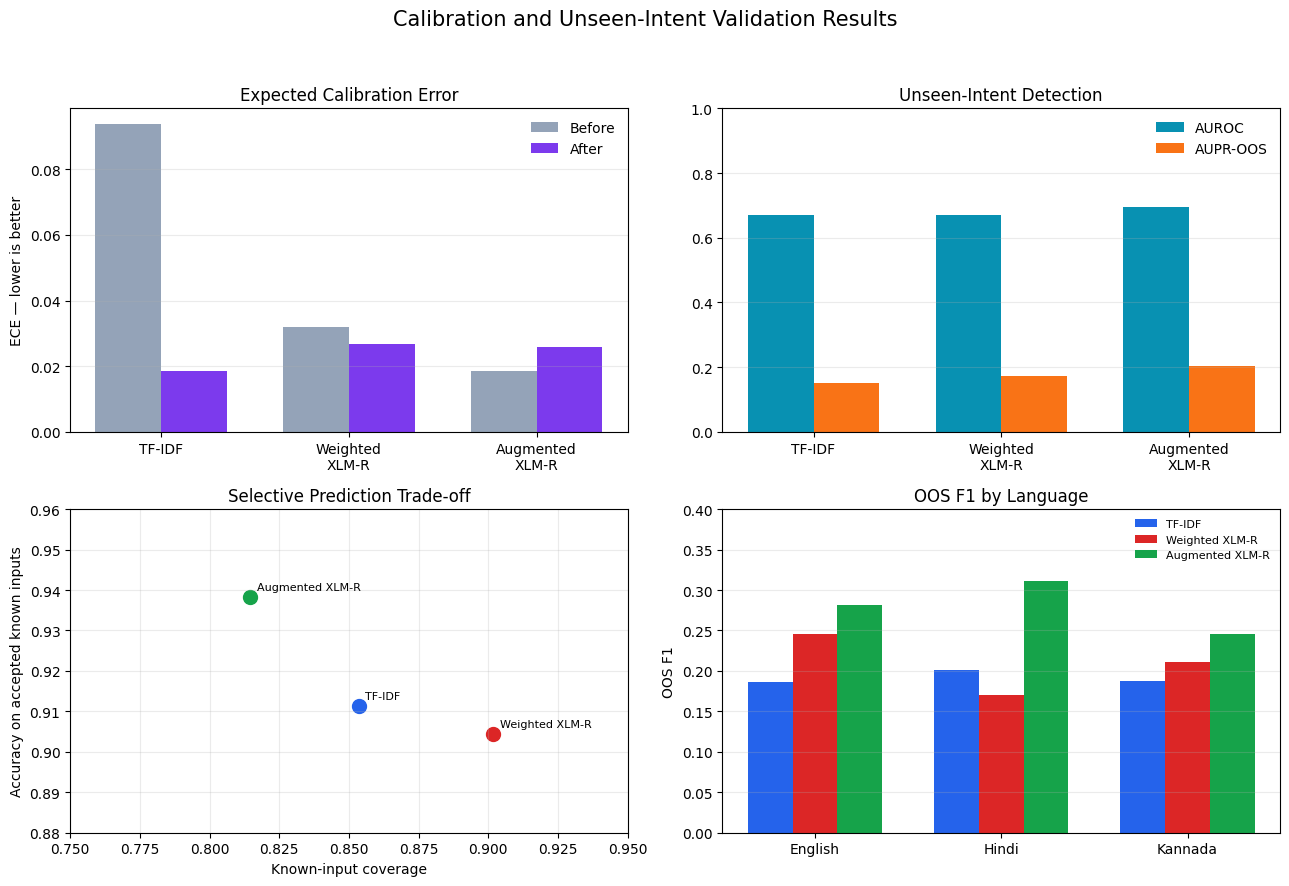

Figure saved: /content/robust-multilingual-intent-classification/results/figures/oos_calibration_summary.png
Test set evaluated: False


In [52]:
import matplotlib.pyplot as plt
import numpy as np

model_order = [
    "TF-IDF",
    "Weighted XLM-R",
    "Noise-Augmented XLM-R",
]

short_names = [
    "TF-IDF",
    "Weighted\nXLM-R",
    "Augmented\nXLM-R",
]

colors = [
    "#2563eb",
    "#dc2626",
    "#16a34a",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)

x = np.arange(len(model_order))
width = 0.35

# Panel 1: ECE before and after temperature scaling
temperature_plot = (
    temperature_results
    .set_index("model")
    .loc[model_order]
)

axes[0, 0].bar(
    x - width / 2,
    temperature_plot["evaluation_ece_before"],
    width,
    label="Before",
    color="#94a3b8",
)

axes[0, 0].bar(
    x + width / 2,
    temperature_plot["evaluation_ece_after"],
    width,
    label="After",
    color="#7c3aed",
)

axes[0, 0].set_title("Expected Calibration Error")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(short_names)
axes[0, 0].set_ylabel("ECE — lower is better")
axes[0, 0].legend(frameon=False)
axes[0, 0].grid(axis="y", alpha=0.25)

# Panel 2: threshold-free OOS detection
threshold_plot = (
    threshold_results
    .set_index("model")
    .loc[model_order]
)

axes[0, 1].bar(
    x - width / 2,
    threshold_plot["evaluation_auroc"],
    width,
    label="AUROC",
    color="#0891b2",
)

axes[0, 1].bar(
    x + width / 2,
    threshold_plot["evaluation_aupr_oos"],
    width,
    label="AUPR-OOS",
    color="#f97316",
)

axes[0, 1].set_title("Unseen-Intent Detection")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(short_names)
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend(frameon=False)
axes[0, 1].grid(axis="y", alpha=0.25)

# Panel 3: coverage versus selective accuracy
for model_name, short_name, color in zip(
    model_order,
    short_names,
    colors
):
    row = threshold_plot.loc[model_name]

    axes[1, 0].scatter(
        row["known_coverage"],
        row["selective_known_accuracy"],
        s=100,
        color=color,
        label=short_name.replace("\n", " "),
    )

    axes[1, 0].annotate(
        short_name.replace("\n", " "),
        (
            row["known_coverage"],
            row["selective_known_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

axes[1, 0].set_title(
    "Selective Prediction Trade-off"
)
axes[1, 0].set_xlabel("Known-input coverage")
axes[1, 0].set_ylabel(
    "Accuracy on accepted known inputs"
)
axes[1, 0].set_xlim(0.75, 0.95)
axes[1, 0].set_ylim(0.88, 0.96)
axes[1, 0].grid(alpha=0.25)

# Panel 4: OOS F1 by language
language_plot = (
    language_oos_results
    .pivot(
        index="locale",
        columns="model",
        values="oos_f1"
    )
    .loc[["en-US", "hi-IN", "kn-IN"], model_order]
)

language_x = np.arange(3)
language_width = 0.24

for index, (model_name, color) in enumerate(
    zip(model_order, colors)
):
    axes[1, 1].bar(
        language_x
        + (index - 1) * language_width,
        language_plot[model_name],
        language_width,
        label=short_names[index].replace("\n", " "),
        color=color,
    )

axes[1, 1].set_title("OOS F1 by Language")
axes[1, 1].set_xticks(language_x)
axes[1, 1].set_xticklabels(
    ["English", "Hindi", "Kannada"]
)
axes[1, 1].set_ylim(0, 0.4)
axes[1, 1].set_ylabel("OOS F1")
axes[1, 1].legend(
    frameon=False,
    fontsize=8
)
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Calibration and Unseen-Intent Validation Results",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

figure_path = (
    repo / "results/figures/"
    "oos_calibration_summary.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)
print("Test set evaluated:", False)

In [53]:
from pathlib import Path
import subprocess

readme_path = repo / "README.md"

start_marker = "<!-- OOS_CALIBRATION_RESULTS_START -->"
end_marker = "<!-- OOS_CALIBRATION_RESULTS_END -->"

section = """<!-- OOS_CALIBRATION_RESULTS_START -->
## Phase 5 — Calibration and unseen-intent rejection

The validation data was divided into separate calibration and evaluation subsets using a deterministic SHA-256 split grouped by parallel example ID. This prevents translated versions of the same request from appearing in both subsets.

Temperature scaling was fitted using calibration-known examples. Confidence thresholds were selected using calibration known and OOS examples, then measured on the held-out validation evaluation subset. The final test set remained untouched.

One configured known intent, `audio_volume_other`, has no examples in the official validation partition. Validation classification metrics therefore cover the 49 known intents present in that partition while the trained models retain all 50 output classes.

### Calibration results

| Model | Temperature | ECE before | ECE after | NLL before | NLL after |
|---|---:|---:|---:|---:|---:|
| TF-IDF | 0.7398 | 0.0938 | 0.0184 | 0.6917 | 0.6381 |
| Weighted XLM-R | 0.9204 | 0.0319 | 0.0266 | 0.6223 | 0.6177 |
| Noise-Augmented XLM-R | 0.9655 | 0.0187 | 0.0259 | 0.5761 | 0.5757 |

Temperature scaling substantially improves TF-IDF calibration and slightly improves weighted XLM-R. The augmented XLM-R was already well calibrated, and its ECE becomes slightly worse after scaling.

### Unseen-intent detection

| Model | Threshold | AUROC | AUPR-OOS | OOS F1 | Known coverage | Accepted-known accuracy |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF | 0.536 | 0.6717 | 0.1524 | 0.1920 | 0.8535 | 0.9113 |
| Weighted XLM-R | 0.567 | 0.6693 | 0.1739 | 0.2079 | 0.9016 | 0.9044 |
| Noise-Augmented XLM-R | 0.797 | 0.6960 | 0.2050 | 0.2788 | 0.8145 | 0.9382 |

The augmented XLM-R provides the strongest unseen-intent detection and the highest accuracy on accepted known inputs. However, its OOS F1 remains only 0.2788, and achieving high OOS recall produces many false rejections. Maximum confidence is therefore useful for selective prediction but is not a reliable standalone unseen-intent detector.

Per-language OOS F1 for the augmented XLM-R is 0.2811 for English, 0.3106 for Hindi, and 0.2454 for Kannada.

![Calibration and unseen-intent results](results/figures/oos_calibration_summary.png)
<!-- OOS_CALIBRATION_RESULTS_END -->"""

readme = readme_path.read_text(encoding="utf-8")

if start_marker in readme and end_marker in readme:
    before = readme.split(start_marker, 1)[0]
    after = readme.split(end_marker, 1)[1]
    readme = before + section + after
else:
    readme = readme.rstrip() + "\n\n" + section + "\n"

readme_path.write_text(
    readme,
    encoding="utf-8"
)

print("README updated:", readme_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
?? configs/oos_calibration.json
?? results/figures/oos_calibration_summary.png
?? results/metrics/oos_calibration_validation_metrics.json



In [54]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

files_to_commit = [
    "README.md",
    "configs/oos_calibration.json",
    "results/figures/oos_calibration_summary.png",
    "results/metrics/oos_calibration_validation_metrics.json",
]

subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "eval: add calibration and unseen-intent results",
    ],
    cwd=repo,
    check=True,
)

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: 8c9c716 eval: add calibration and unseen-intent results
Status: ## main...origin/main


In [55]:
import subprocess

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print(pull.stdout)
print(pull.stderr)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("Status:", status.stdout.strip())

Updating 8c9c716..fdf520d
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 1803 ++++++++++++++++++++-
 1 file changed, 1801 insertions(+), 2 deletions(-)

From https://github.com/sharath7-dev/robust-multilingual-intent-classification
 * branch            main       -> FETCH_HEAD
   8c9c716..fdf520d  main       -> origin/main

Status: ## main...origin/main


In [56]:
import hashlib
import pandas as pd
import regex

SCRIPT_SHIFT_IDS = 1989


def augmentation_id_hash(example_id):
    value = (
        f"42|script_shift_training|{example_id}"
        .encode("utf-8")
    )

    return hashlib.sha256(value).hexdigest()


available_training_ids = (
    train_known["id"]
    .drop_duplicates()
    .tolist()
)

selected_script_shift_ids = sorted(
    available_training_ids,
    key=augmentation_id_hash
)[:SCRIPT_SHIFT_IDS]

script_shift_training = train_known[
    train_known["id"].isin(
        selected_script_shift_ids
    )
][
    ["id", "locale", "intent", "utt"]
].copy()

script_shift_training["original_utt"] = (
    script_shift_training["utt"]
)

script_shift_training["utt"] = [
    (
        text
        if locale == "en-US"
        else create_synthetic_transliteration(
            text,
            locale
        )
    )
    for text, locale in zip(
        script_shift_training["original_utt"],
        script_shift_training["locale"],
    )
]

script_shift_training["source"] = (
    script_shift_training["locale"].map({
        "en-US": "english_control_copy",
        "hi-IN": "synthetic_romanized",
        "kn-IN": "synthetic_romanized",
    })
)

combined_augmented_training = pd.concat(
    [
        clean_training[
            ["id", "locale", "intent", "utt", "source"]
        ],
        noisy_training_balanced[
            ["id", "locale", "intent", "utt", "source"]
        ],
        script_shift_training[
            ["id", "locale", "intent", "utt", "source"]
        ],
    ],
    ignore_index=True,
)

native_script_remaining = sum(
    bool(
        regex.search(
            r"\p{Script=Devanagari}|\p{Script=Kannada}",
            text
        )
    )
    for text in script_shift_training.loc[
        script_shift_training["locale"].isin(
            ["hi-IN", "kn-IN"]
        ),
        "utt"
    ]
)

print(
    "Selected parallel IDs:",
    len(selected_script_shift_ids)
)
print(
    "Script-shift additions:",
    len(script_shift_training)
)

print("\nScript-shift additions by language:")
print(
    script_shift_training["locale"]
    .value_counts()
    .sort_index()
)

print("\nCombined rows by source:")
print(
    combined_augmented_training["source"]
    .value_counts()
)

print("\nFinal rows by language:")
print(
    combined_augmented_training["locale"]
    .value_counts()
    .sort_index()
)

print(
    "\nFinal combined training rows:",
    len(combined_augmented_training)
)
print(
    "Native-script residues in Romanized additions:",
    native_script_remaining
)
print("Validation/test rows used:", False)

assert len(selected_script_shift_ids) == 1989
assert len(script_shift_training) == 5967
assert len(combined_augmented_training) == 38127
assert (
    combined_augmented_training["locale"]
    .value_counts()
    .nunique()
    == 1
)
assert native_script_remaining == 0

Selected parallel IDs: 1989
Script-shift additions: 5967

Script-shift additions by language:
locale
en-US    1989
hi-IN    1989
kn-IN    1989
Name: count, dtype: int64

Combined rows by source:
source
clean                   26193
synthetic_noise_10       5967
synthetic_romanized      3978
english_control_copy     1989
Name: count, dtype: int64

Final rows by language:
locale
en-US    12709
hi-IN    12709
kn-IN    12709
Name: count, dtype: int64

Final combined training rows: 38127
Native-script residues in Romanized additions: 0
Validation/test rows used: False


In [57]:
import numpy as np
from datasets import Dataset

combined_model_data = (
    combined_augmented_training[
        ["utt", "intent"]
    ]
    .copy()
)

combined_model_data["labels"] = (
    combined_model_data["intent"].map(label2id)
)

assert combined_model_data["labels"].notna().all()

combined_model_data["labels"] = (
    combined_model_data["labels"].astype(int)
)

combined_label_counts = np.bincount(
    combined_model_data["labels"],
    minlength=50
)

combined_class_weights = (
    1.0 / np.sqrt(combined_label_counts)
)

combined_class_weights /= (
    combined_class_weights.mean()
)

combined_train_dataset = Dataset.from_pandas(
    combined_model_data[
        ["utt", "labels"]
    ],
    preserve_index=False
)


def tokenize_combined_batch(batch):
    return weighted_tokenizer(
        batch["utt"],
        truncation=True,
        max_length=64,
    )


tokenized_combined_train = (
    combined_train_dataset.map(
        tokenize_combined_batch,
        batched=True,
        remove_columns=["utt"],
    )
)

print(
    "Tokenized combined training rows:",
    len(tokenized_combined_train)
)
print(
    "Training columns:",
    tokenized_combined_train.column_names
)
print(
    "Minimum class count:",
    int(combined_label_counts.min())
)
print(
    "Maximum class count:",
    int(combined_label_counts.max())
)
print(
    "Minimum class weight:",
    round(float(combined_class_weights.min()), 4)
)
print(
    "Maximum class weight:",
    round(float(combined_class_weights.max()), 4)
)
print(
    "Missing training labels:",
    int((combined_label_counts == 0).sum())
)
print("Test set used:", False)

Map:   0%|          | 0/38127 [00:00<?, ? examples/s]

Tokenized combined training rows: 38127
Training columns: ['labels', 'input_ids', 'attention_mask']
Minimum class count: 16
Maximum class count: 3700
Minimum class weight: 0.318
Maximum class weight: 4.8352
Missing training labels: 0
Test set used: False


In [58]:
import gc
import math
import torch

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
)

# Free the GPU before loading the fresh model
augmented_trainer.model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

combined_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        "FacebookAI/xlm-roberta-base",
        num_labels=50,
        label2id=label2id,
        id2label=id2label,
    )
)

combined_steps_per_epoch = math.ceil(
    len(tokenized_combined_train) / 16
)

combined_total_steps = (
    combined_steps_per_epoch * 2
)

combined_warmup_steps = round(
    combined_total_steps * 0.10
)

combined_training_args = TrainingArguments(
    output_dir=str(
        repo /
        "models/xlmr_combined_augmented_checkpoints"
    ),
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=combined_warmup_steps,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    data_seed=42,
    report_to="none",
)

combined_trainer = AugmentedWeightedTrainer(
    model=combined_model,
    args=combined_training_args,
    train_dataset=tokenized_combined_train,
    eval_dataset=tokenized_clean_validation,
    processing_class=weighted_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_augmented_metrics,
    class_weights=combined_class_weights,
)

print("Trainer created successfully:", True)
print(
    "Training examples:",
    len(tokenized_combined_train)
)
print(
    "Validation examples:",
    len(tokenized_clean_validation)
)
print("Epochs:", 2)
print(
    "Steps per epoch:",
    combined_steps_per_epoch
)
print(
    "Approximate total steps:",
    combined_total_steps
)
print(
    "Warmup steps:",
    combined_warmup_steps
)
print("FP16 enabled:", combined_training_args.fp16)
print("Test set used:", False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainer created successfully: True
Training examples: 38127
Validation examples: 4629
Epochs: 2
Steps per epoch: 2383
Approximate total steps: 4766
Warmup steps: 477
FP16 enabled: True
Test set used: False


In [59]:
print(
    "Combined trainer exists:",
    "combined_trainer" in globals()
)

if "combined_trainer" in globals():
    print(
        "Training examples:",
        len(combined_trainer.train_dataset)
    )
    print(
        "Validation examples:",
        len(combined_trainer.eval_dataset)
    )
    print(
        "Total steps:",
        combined_total_steps
    )
    print(
        "Warmup steps:",
        combined_warmup_steps
    )
    print(
        "FP16 enabled:",
        combined_training_args.fp16
    )

print("Test set used:", False)

Combined trainer exists: True
Training examples: 38127
Validation examples: 4629
Total steps: 4766
Warmup steps: 477
FP16 enabled: True
Test set used: False


In [60]:
import time

combined_training_start = time.time()

combined_training_output = (
    combined_trainer.train()
)

combined_training_minutes = (
    time.time() - combined_training_start
) / 60

print("\nCombined-augmentation training completed.")
print(
    "Wall-clock time:",
    round(combined_training_minutes, 1),
    "minutes"
)
print(
    "Best checkpoint:",
    combined_trainer.state.best_model_checkpoint
)
print(
    "Best validation macro-F1:",
    combined_trainer.state.best_metric
)
print("Test set used:", False)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,2.017041,0.747856,0.839706,0.760882
2,0.736109,0.597495,0.862389,0.826658


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Combined-augmentation training completed.
Wall-clock time: 13.0 minutes
Best checkpoint: /content/robust-multilingual-intent-classification/models/xlmr_combined_augmented_checkpoints/checkpoint-4766
Best validation macro-F1: 0.8266577336989948
Test set used: False


In [61]:
def predict_combined_xlmr(texts, batch_size=64):
    predicted_ids = []

    combined_model = combined_trainer.model
    combined_model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = weighted_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to("cuda")

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = combined_model(**encoded).logits

        predicted_ids.extend(
            logits.argmax(dim=-1).cpu().tolist()
        )

    return [
        id2label[index]
        for index in predicted_ids
    ]


# Clean and spelling-noise evaluation
combined_noise_predictions = {}
combined_noise_rows = []

for rate, texts in evaluation_sets.items():
    print(
        f"Evaluating combined model at {rate:.0%} noise..."
    )

    predictions = predict_combined_xlmr(texts)
    combined_noise_predictions[rate] = predictions

    combined_noise_rows.append({
        "model": "Combined-Augmented XLM-R",
        "noise_rate": rate,
        "accuracy": accuracy_score(
            true_labels,
            predictions
        ),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0,
        ),
    })

combined_noise_results = pd.DataFrame(
    combined_noise_rows
)

combined_clean_f1 = combined_noise_results.loc[
    combined_noise_results["noise_rate"] == 0,
    "macro_f1"
].iloc[0]

combined_noise_results["macro_f1_drop"] = (
    combined_clean_f1
    - combined_noise_results["macro_f1"]
)

complete_robustness_comparison = pd.concat(
    [
        robustness_comparison,
        combined_noise_results,
    ],
    ignore_index=True,
)

# Transliteration evaluation
print("Evaluating combined model on transliterated input...")

combined_transliterated_predictions = (
    predict_combined_xlmr(
        transliterated_texts
    )
)

combined_clean_array = np.array(
    combined_noise_predictions[0.00]
)

combined_transliterated_array = np.array(
    combined_transliterated_predictions
)

combined_transliteration_rows = []

for group_name, mask in evaluation_groups.items():
    clean_f1 = f1_score(
        true_array[mask],
        combined_clean_array[mask],
        average="macro",
        zero_division=0,
    )

    transliterated_f1 = f1_score(
        true_array[mask],
        combined_transliterated_array[mask],
        average="macro",
        zero_division=0,
    )

    combined_transliteration_rows.append({
        "model": "Combined-Augmented XLM-R",
        "group": group_name,
        "samples": int(mask.sum()),
        "clean_accuracy": accuracy_score(
            true_array[mask],
            combined_clean_array[mask],
        ),
        "transliterated_accuracy": accuracy_score(
            true_array[mask],
            combined_transliterated_array[mask],
        ),
        "clean_macro_f1": clean_f1,
        "transliterated_macro_f1":
            transliterated_f1,
        "macro_f1_drop":
            clean_f1 - transliterated_f1,
    })

combined_transliteration_results = pd.DataFrame(
    combined_transliteration_rows
)

complete_transliteration_results = pd.concat(
    [
        transliteration_results,
        combined_transliteration_results,
    ],
    ignore_index=True,
)

print("\nCombined model — spelling noise:")
print(
    combined_noise_results.to_string(
        index=False,
        formatters={
            "noise_rate":
                lambda value: f"{value:.0%}",
            "accuracy":
                lambda value: f"{value:.4f}",
            "macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nCombined model — transliteration:")
print(
    combined_transliteration_results.to_string(
        index=False,
        formatters={
            "clean_accuracy":
                lambda value: f"{value:.4f}",
            "transliterated_accuracy":
                lambda value: f"{value:.4f}",
            "clean_macro_f1":
                lambda value: f"{value:.4f}",
            "transliterated_macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nTest set evaluated:", False)

Evaluating combined model at 0% noise...
Evaluating combined model at 5% noise...
Evaluating combined model at 10% noise...
Evaluating combined model at 15% noise...
Evaluating combined model on transliterated input...

Combined model — spelling noise:
                   model noise_rate accuracy macro_f1 macro_f1_drop
Combined-Augmented XLM-R         0%   0.8622   0.8261        0.0000
Combined-Augmented XLM-R         5%   0.8505   0.8073        0.0188
Combined-Augmented XLM-R        10%   0.8391   0.7931        0.0330
Combined-Augmented XLM-R        15%   0.8270   0.7789        0.0472

Combined model — transliteration:
                   model                  group  samples clean_accuracy transliterated_accuracy clean_macro_f1 transliterated_macro_f1 macro_f1_drop
Combined-Augmented XLM-R          all_languages     4629         0.8622                  0.6781         0.8261                  0.6298        0.1963
Combined-Augmented XLM-R        english_control     1543         0.8820   

In [62]:
from pathlib import Path

combined_drive_path = Path(
    "/content/drive/MyDrive/"
    "robust_multilingual_intent/artifacts/models/"
    "xlmr_combined_augmented_final"
)

combined_drive_path.mkdir(
    parents=True,
    exist_ok=True
)

combined_trainer.save_model(
    str(combined_drive_path)
)

weighted_tokenizer.save_pretrained(
    str(combined_drive_path)
)

combined_model_size = sum(
    file.stat().st_size
    for file in combined_drive_path.rglob("*")
    if file.is_file()
)

print("Model saved to Drive:", combined_drive_path)
print(
    "Model directory size:",
    round(combined_model_size / 1024**3, 2),
    "GB"
)
print(
    "Model file exists:",
    (
        combined_drive_path /
        "model.safetensors"
    ).is_file()
)
print("Test set evaluated:", False)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to Drive: /content/drive/MyDrive/robust_multilingual_intent/artifacts/models/xlmr_combined_augmented_final
Model directory size: 1.05 GB
Model file exists: True
Test set evaluated: False


In [63]:
from scipy.optimize import minimize_scalar
from scipy.special import softmax

combined_model = combined_trainer.model
combined_model.to("cuda")

print("Collecting combined-model validation logits...")

combined_detection_logits = collect_xlmr_logits(
    combined_model,
    detection_texts
)

combined_classes = np.array(
    [id2label[index] for index in range(50)]
)

combined_class_to_index = {
    label: index
    for index, label in enumerate(
        combined_classes
    )
}

combined_true_indices = np.array([
    combined_class_to_index.get(intent, -1)
    for intent in validation_detection_data["intent"]
])

combined_calibration_logits = (
    combined_detection_logits[
        calibration_known_mask
    ]
)

combined_calibration_true = (
    combined_true_indices[
        calibration_known_mask
    ]
)

combined_evaluation_logits = (
    combined_detection_logits[
        evaluation_known_mask
    ]
)

combined_evaluation_true = (
    combined_true_indices[
        evaluation_known_mask
    ]
)


def combined_temperature_objective(temperature):
    probabilities = softmax(
        combined_calibration_logits / temperature,
        axis=1
    )

    return negative_log_likelihood(
        probabilities,
        combined_calibration_true
    )


combined_temperature_optimization = (
    minimize_scalar(
        combined_temperature_objective,
        bounds=(0.05, 10.0),
        method="bounded",
        options={"xatol": 1e-4},
    )
)

combined_temperature = float(
    combined_temperature_optimization.x
)

combined_uncalibrated_evaluation = softmax(
    combined_evaluation_logits,
    axis=1
)

combined_calibrated_evaluation = softmax(
    combined_evaluation_logits
    / combined_temperature,
    axis=1
)

combined_calibrated_probabilities = softmax(
    combined_detection_logits
    / combined_temperature,
    axis=1
)

detection_outputs[
    "Combined-Augmented XLM-R"
] = {
    "logits": combined_detection_logits,
    "probabilities": softmax(
        combined_detection_logits,
        axis=1
    ),
    "classes": combined_classes,
    "temperature": combined_temperature,
    "calibrated_probabilities":
        combined_calibrated_probabilities,
}

combined_temperature_row = {
    "model": "Combined-Augmented XLM-R",
    "temperature": combined_temperature,
    "evaluation_nll_before":
        negative_log_likelihood(
            combined_uncalibrated_evaluation,
            combined_evaluation_true
        ),
    "evaluation_nll_after":
        negative_log_likelihood(
            combined_calibrated_evaluation,
            combined_evaluation_true
        ),
    "evaluation_ece_before":
        expected_calibration_error(
            combined_uncalibrated_evaluation,
            combined_evaluation_true
        ),
    "evaluation_ece_after":
        expected_calibration_error(
            combined_calibrated_evaluation,
            combined_evaluation_true
        ),
    "evaluation_accuracy":
        float(
            (
                combined_calibrated_evaluation.argmax(axis=1)
                == combined_evaluation_true
            ).mean()
        ),
}

temperature_results = pd.concat(
    [
        temperature_results[
            temperature_results["model"]
            != "Combined-Augmented XLM-R"
        ],
        pd.DataFrame(
            [combined_temperature_row]
        ),
    ],
    ignore_index=True,
)

print(
    pd.DataFrame(
        [combined_temperature_row]
    ).to_string(
        index=False,
        formatters={
            key: lambda value: f"{value:.4f}"
            for key in combined_temperature_row
            if key != "model"
        },
    )
)

print("\nTest set evaluated:", False)

                   model temperature evaluation_nll_before evaluation_nll_after evaluation_ece_before evaluation_ece_after evaluation_accuracy
Combined-Augmented XLM-R      0.9661                0.5821               0.5809                0.0189               0.0227              0.8535

Test set evaluated: False


In [66]:
combined_language_rows = []

for rate, predictions in (
    combined_noise_predictions.items()
):
    prediction_array = np.array(predictions)

    for locale in ["en-US", "hi-IN", "kn-IN"]:
        mask = locale_array == locale

        combined_language_rows.append({
            "model":
                "Combined-Augmented XLM-R",
            "noise_rate": rate,
            "locale": locale,
            "samples": int(mask.sum()),
            "accuracy": accuracy_score(
                true_array[mask],
                prediction_array[mask],
            ),
            "macro_f1": f1_score(
                true_array[mask],
                prediction_array[mask],
                average="macro",
                zero_division=0,
            ),
        })

combined_language_results = pd.DataFrame(
    combined_language_rows
)

combined_clean_language_f1 = (
    combined_language_results[
        combined_language_results["noise_rate"]
        == 0
    ]
    .set_index("locale")["macro_f1"]
    .to_dict()
)

combined_language_results["macro_f1_drop"] = (
    combined_language_results.apply(
        lambda row: (
            combined_clean_language_f1[
                row["locale"]
            ]
            - row["macro_f1"]
        ),
        axis=1,
    )
)

complete_language_results = pd.concat(
    [
        complete_language_results[
            complete_language_results["model"]
            != "Combined-Augmented XLM-R"
        ],
        combined_language_results,
    ],
    ignore_index=True,
)

print(
    combined_language_results.to_string(
        index=False,
        formatters={
            "noise_rate":
                lambda value: f"{value:.0%}",
            "accuracy":
                lambda value: f"{value:.4f}",
            "macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nTest set evaluated:", False)


                   model noise_rate locale  samples accuracy macro_f1 macro_f1_drop
Combined-Augmented XLM-R         0%  en-US     1543   0.8820   0.8625        0.0000
Combined-Augmented XLM-R         0%  hi-IN     1543   0.8607   0.8094        0.0000
Combined-Augmented XLM-R         0%  kn-IN     1543   0.8438   0.7965        0.0000
Combined-Augmented XLM-R         5%  en-US     1543   0.8671   0.8319        0.0306
Combined-Augmented XLM-R         5%  hi-IN     1543   0.8496   0.7995        0.0100
Combined-Augmented XLM-R         5%  kn-IN     1543   0.8347   0.7848        0.0117
Combined-Augmented XLM-R        10%  en-US     1543   0.8529   0.8138        0.0487
Combined-Augmented XLM-R        10%  hi-IN     1543   0.8406   0.7908        0.0187
Combined-Augmented XLM-R        10%  kn-IN     1543   0.8237   0.7676        0.0289
Combined-Augmented XLM-R        15%  en-US     1543   0.8360   0.7954        0.0671
Combined-Augmented XLM-R        15%  hi-IN     1543   0.8321   0.7850       

In [67]:
import json
import subprocess

combined_config = {
    "base_model": "FacebookAI/xlm-roberta-base",
    "random_seed": 42,
    "training_rows": {
        "clean": 26193,
        "synthetic_spelling_noise": 5967,
        "synthetic_romanized": 3978,
        "english_control_copies": 1989,
        "total": 38127
    },
    "rows_per_language": {
        "en-US": 12709,
        "hi-IN": 12709,
        "kn-IN": 12709
    },
    "spelling_noise_rate": 0.10,
    "script_shift_parallel_ids": 1989,
    "script_shift_id_selection": (
        "SHA-256 deterministic ranking of training IDs"
    ),
    "transliteration": {
        "library": "indic-transliteration",
        "version": "2.3.82",
        "scheme": "ITRANS",
        "normalization": "lowercase simplified ASCII"
    },
    "class_weighting": (
        "normalized square-root inverse class frequency"
    ),
    "epochs": 2,
    "learning_rate": 0.00002,
    "train_batch_size": 16,
    "evaluation_batch_size": 32,
    "weight_decay": 0.01,
    "warmup_steps": 477,
    "maximum_token_length": 64,
    "fp16": True,
    "selection_metric": "validation_macro_f1",
    "validation_or_test_leakage": False,
    "test_set_used": False
}

combined_metrics = {
    "dataset": "MASSIVE 1.1",
    "model": "Combined-Augmented XLM-R",
    "training_time_minutes": round(
        float(combined_training_minutes),
        2
    ),
    "best_clean_validation_macro_f1": round(
        float(combined_trainer.state.best_metric),
        6
    ),
    "spelling_noise_results": json.loads(
        combined_noise_results.round(6).to_json(
            orient="records"
        )
    ),
    "spelling_noise_per_language": json.loads(
        combined_language_results.round(6).to_json(
            orient="records"
        )
    ),
    "transliteration_results": json.loads(
        combined_transliteration_results
        .round(6)
        .to_json(orient="records")
    ),
    "temperature_result":
        {
            key: (
                round(float(value), 6)
                if key != "model"
                else value
            )
            for key, value
            in combined_temperature_row.items()
        },
    "overall_oos_result": json.loads(
        threshold_results[
            threshold_results["model"]
            == "Combined-Augmented XLM-R"
        ]
        .round(6)
        .to_json(orient="records")
    )[0],
    "per_language_oos_results": json.loads(
        language_oos_results[
            language_oos_results["model"]
            == "Combined-Augmented XLM-R"
        ]
        .round(6)
        .to_json(orient="records")
    ),
    "drive_model_location": (
        "MyDrive/robust_multilingual_intent/"
        "artifacts/models/"
        "xlmr_combined_augmented_final"
    ),
    "test_set_evaluated": False
}

combined_config_path = (
    repo / "configs/combined_augmentation.json"
)

combined_metrics_path = (
    repo / "results/metrics/"
    "xlmr_combined_augmented_validation_metrics.json"
)

with open(
    combined_config_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        combined_config,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(
    combined_metrics_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        combined_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

# Update spelling-noise comparison
spelling_path = (
    repo / "results/metrics/"
    "spelling_noise_validation_metrics.json"
)

with open(
    spelling_path,
    encoding="utf-8"
) as file:
    spelling_metrics = json.load(file)

spelling_metrics["overall_results"] = json.loads(
    complete_robustness_comparison
    .round(6)
    .to_json(orient="records")
)

spelling_metrics["per_language_results"] = json.loads(
    complete_language_results
    .round(6)
    .to_json(orient="records")
)

with open(
    spelling_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        spelling_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

# Update transliteration comparison
transliteration_path = (
    repo / "results/metrics/"
    "transliteration_validation_metrics.json"
)

with open(
    transliteration_path,
    encoding="utf-8"
) as file:
    transliteration_metrics = json.load(file)

transliteration_metrics["results"] = json.loads(
    complete_transliteration_results
    .round(6)
    .to_json(orient="records")
)

with open(
    transliteration_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        transliteration_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

# Update calibration/OOS comparison
oos_path = (
    repo / "results/metrics/"
    "oos_calibration_validation_metrics.json"
)

with open(oos_path, encoding="utf-8") as file:
    oos_metrics = json.load(file)

oos_metrics["temperature_results"] = json.loads(
    temperature_results
    .round(6)
    .to_json(orient="records")
)

oos_metrics["overall_oos_results"] = json.loads(
    threshold_results
    .round(6)
    .to_json(orient="records")
)

oos_metrics["per_language_oos_results"] = json.loads(
    language_oos_results
    .round(6)
    .to_json(orient="records")
)

with open(
    oos_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        oos_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Combined configuration saved:", combined_config_path)
print("Combined metrics saved:", combined_metrics_path)
print("Comparison metric files updated:", 3)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Combined configuration saved: /content/robust-multilingual-intent-classification/configs/combined_augmentation.json
Combined metrics saved: /content/robust-multilingual-intent-classification/results/metrics/xlmr_combined_augmented_validation_metrics.json
Comparison metric files updated: 3

Git status:
 M results/metrics/oos_calibration_validation_metrics.json
 M results/metrics/spelling_noise_validation_metrics.json
 M results/metrics/transliteration_validation_metrics.json
?? configs/combined_augmentation.json
?? results/metrics/xlmr_combined_augmented_validation_metrics.json



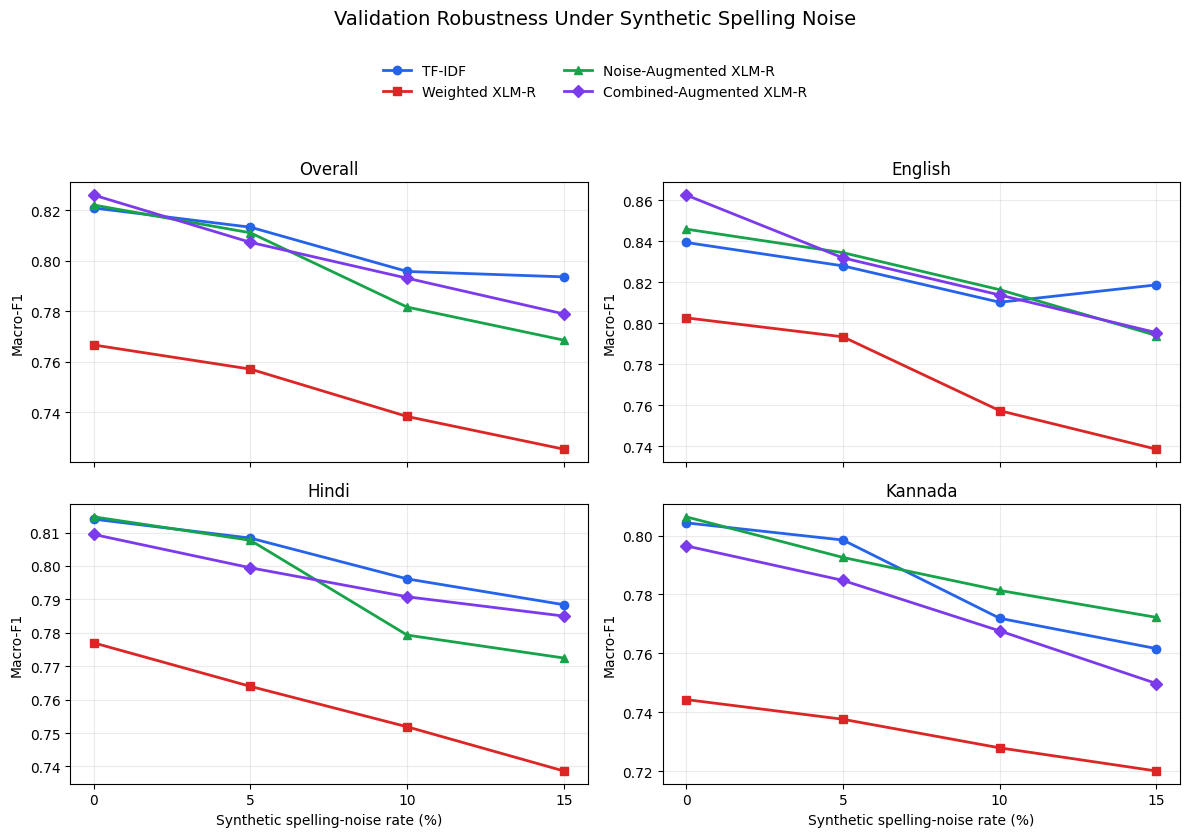

Updated figure saved: /content/robust-multilingual-intent-classification/results/figures/spelling_noise_robustness.png


In [68]:
import matplotlib.pyplot as plt

model_styles = {
    "TF-IDF": {
        "color": "#2563eb",
        "marker": "o"
    },
    "Weighted XLM-R": {
        "color": "#dc2626",
        "marker": "s"
    },
    "Noise-Augmented XLM-R": {
        "color": "#16a34a",
        "marker": "^"
    },
    "Combined-Augmented XLM-R": {
        "color": "#7c3aed",
        "marker": "D"
    }
}

panels = [
    ("Overall", complete_robustness_comparison),
    (
        "English",
        complete_language_results[
            complete_language_results["locale"]
            == "en-US"
        ]
    ),
    (
        "Hindi",
        complete_language_results[
            complete_language_results["locale"]
            == "hi-IN"
        ]
    ),
    (
        "Kannada",
        complete_language_results[
            complete_language_results["locale"]
            == "kn-IN"
        ]
    ),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8.5),
    sharex=True
)

for axis, (title, frame) in zip(
    axes.flat,
    panels
):
    for model_name, style in model_styles.items():
        model_results = (
            frame[
                frame["model"] == model_name
            ]
            .sort_values("noise_rate")
        )

        axis.plot(
            model_results["noise_rate"] * 100,
            model_results["macro_f1"],
            label=model_name,
            color=style["color"],
            marker=style["marker"],
            linewidth=2,
            markersize=6,
        )

    axis.set_title(title)
    axis.set_ylabel("Macro-F1")
    axis.set_xticks([0, 5, 10, 15])
    axis.grid(alpha=0.25)

for axis in axes[1]:
    axis.set_xlabel(
        "Synthetic spelling-noise rate (%)"
    )

handles, labels = (
    axes[0, 0].get_legend_handles_labels()
)

fig.suptitle(
    "Validation Robustness Under Synthetic Spelling Noise",
    fontsize=14,
    y=0.98
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.86])

figure_path = (
    repo / "results/figures/"
    "spelling_noise_robustness.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Updated figure saved:", figure_path)

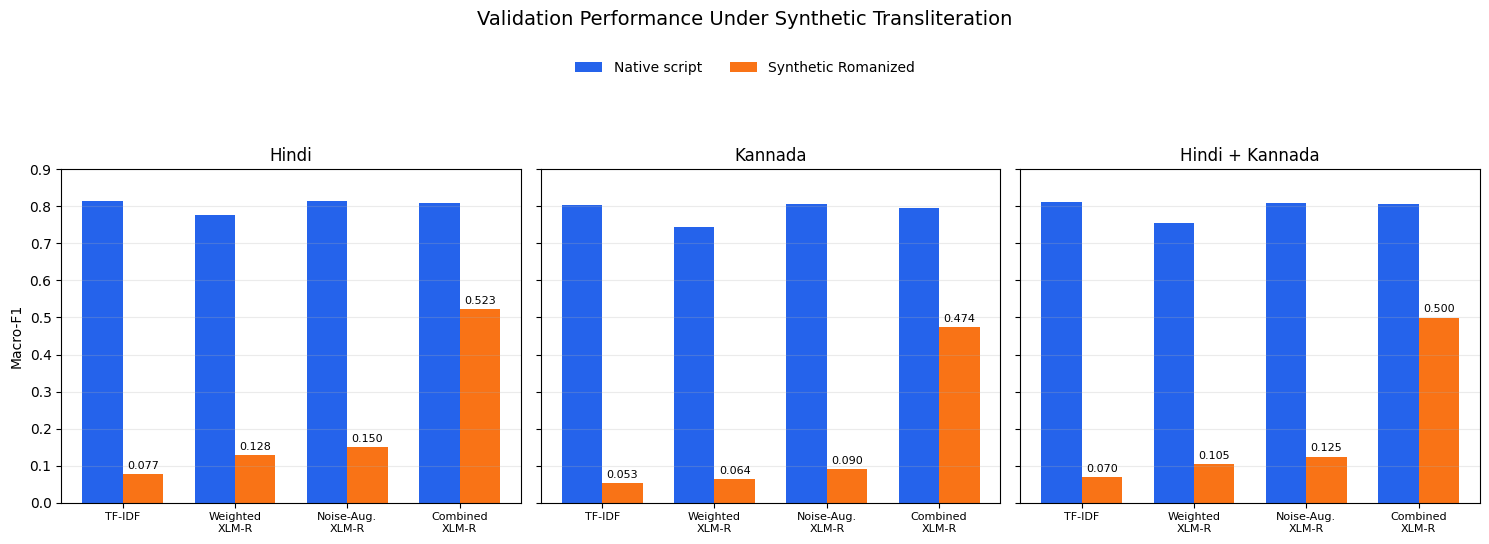

Updated figure saved: /content/robust-multilingual-intent-classification/results/figures/transliteration_robustness.png


In [69]:
import matplotlib.pyplot as plt
import numpy as np

plot_groups = [
    ("hindi_transliterated", "Hindi"),
    ("kannada_transliterated", "Kannada"),
    ("hindi_kannada_combined", "Hindi + Kannada"),
]

model_order = [
    "TF-IDF",
    "Weighted XLM-R",
    "Noise-Augmented XLM-R",
    "Combined-Augmented XLM-R",
]

short_model_names = [
    "TF-IDF",
    "Weighted\nXLM-R",
    "Noise-Aug.\nXLM-R",
    "Combined\nXLM-R",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5.5),
    sharey=True
)

x = np.arange(len(model_order))
bar_width = 0.36

for axis, (group_key, title) in zip(
    axes,
    plot_groups
):
    group_results = (
        complete_transliteration_results[
            complete_transliteration_results["group"]
            == group_key
        ]
        .set_index("model")
        .loc[model_order]
    )

    clean_values = group_results[
        "clean_macro_f1"
    ].to_numpy()

    transliterated_values = group_results[
        "transliterated_macro_f1"
    ].to_numpy()

    axis.bar(
        x - bar_width / 2,
        clean_values,
        width=bar_width,
        label="Native script",
        color="#2563eb",
    )

    axis.bar(
        x + bar_width / 2,
        transliterated_values,
        width=bar_width,
        label="Synthetic Romanized",
        color="#f97316",
    )

    axis.set_title(title)
    axis.set_xticks(x)
    axis.set_xticklabels(
        short_model_names,
        fontsize=8
    )
    axis.set_ylim(0, 0.9)
    axis.grid(axis="y", alpha=0.25)

    for position, value in zip(
        x + bar_width / 2,
        transliterated_values
    ):
        axis.text(
            position,
            value + 0.014,
            f"{value:.3f}",
            ha="center",
            fontsize=8,
        )

axes[0].set_ylabel("Macro-F1")

handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.suptitle(
    "Validation Performance Under Synthetic Transliteration",
    fontsize=14,
    y=0.98
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0, 1, 0.82])

figure_path = (
    repo / "results/figures/"
    "transliteration_robustness.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Updated figure saved:", figure_path)

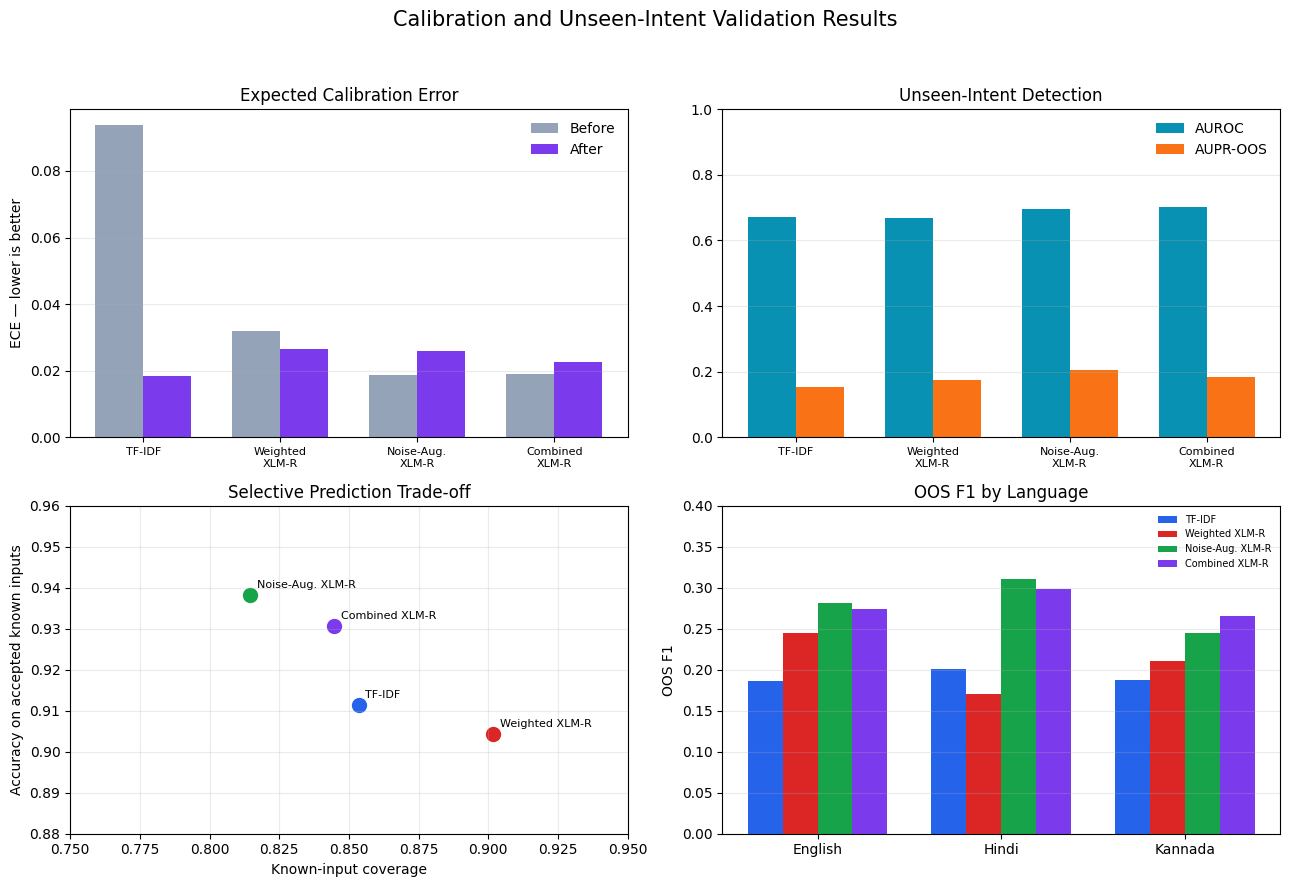

Updated figure saved: /content/robust-multilingual-intent-classification/results/figures/oos_calibration_summary.png


In [70]:
import matplotlib.pyplot as plt
import numpy as np

model_order = [
    "TF-IDF",
    "Weighted XLM-R",
    "Noise-Augmented XLM-R",
    "Combined-Augmented XLM-R",
]

short_names = [
    "TF-IDF",
    "Weighted\nXLM-R",
    "Noise-Aug.\nXLM-R",
    "Combined\nXLM-R",
]

colors = [
    "#2563eb",
    "#dc2626",
    "#16a34a",
    "#7c3aed",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)

x = np.arange(len(model_order))
width = 0.35

temperature_plot = (
    temperature_results
    .set_index("model")
    .loc[model_order]
)

axes[0, 0].bar(
    x - width / 2,
    temperature_plot["evaluation_ece_before"],
    width,
    label="Before",
    color="#94a3b8",
)

axes[0, 0].bar(
    x + width / 2,
    temperature_plot["evaluation_ece_after"],
    width,
    label="After",
    color="#7c3aed",
)

axes[0, 0].set_title(
    "Expected Calibration Error"
)
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(
    short_names,
    fontsize=8
)
axes[0, 0].set_ylabel(
    "ECE — lower is better"
)
axes[0, 0].legend(frameon=False)
axes[0, 0].grid(axis="y", alpha=0.25)

threshold_plot = (
    threshold_results
    .set_index("model")
    .loc[model_order]
)

axes[0, 1].bar(
    x - width / 2,
    threshold_plot["evaluation_auroc"],
    width,
    label="AUROC",
    color="#0891b2",
)

axes[0, 1].bar(
    x + width / 2,
    threshold_plot["evaluation_aupr_oos"],
    width,
    label="AUPR-OOS",
    color="#f97316",
)

axes[0, 1].set_title(
    "Unseen-Intent Detection"
)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(
    short_names,
    fontsize=8
)
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend(frameon=False)
axes[0, 1].grid(axis="y", alpha=0.25)

for model_name, short_name, color in zip(
    model_order,
    short_names,
    colors
):
    row = threshold_plot.loc[model_name]

    axes[1, 0].scatter(
        row["known_coverage"],
        row["selective_known_accuracy"],
        s=100,
        color=color,
    )

    axes[1, 0].annotate(
        short_name.replace("\n", " "),
        (
            row["known_coverage"],
            row["selective_known_accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

axes[1, 0].set_title(
    "Selective Prediction Trade-off"
)
axes[1, 0].set_xlabel(
    "Known-input coverage"
)
axes[1, 0].set_ylabel(
    "Accuracy on accepted known inputs"
)
axes[1, 0].set_xlim(0.75, 0.95)
axes[1, 0].set_ylim(0.88, 0.96)
axes[1, 0].grid(alpha=0.25)

language_plot = (
    language_oos_results
    .pivot(
        index="locale",
        columns="model",
        values="oos_f1"
    )
    .loc[
        ["en-US", "hi-IN", "kn-IN"],
        model_order
    ]
)

language_x = np.arange(3)
language_width = 0.19

for index, (model_name, color) in enumerate(
    zip(model_order, colors)
):
    axes[1, 1].bar(
        language_x
        + (index - 1.5) * language_width,
        language_plot[model_name],
        language_width,
        label=short_names[index].replace(
            "\n",
            " "
        ),
        color=color,
    )

axes[1, 1].set_title(
    "OOS F1 by Language"
)
axes[1, 1].set_xticks(language_x)
axes[1, 1].set_xticklabels(
    ["English", "Hindi", "Kannada"]
)
axes[1, 1].set_ylim(0, 0.4)
axes[1, 1].set_ylabel("OOS F1")
axes[1, 1].legend(
    frameon=False,
    fontsize=7
)
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Calibration and Unseen-Intent Validation Results",
    fontsize=15,
    y=0.98
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

figure_path = (
    repo / "results/figures/"
    "oos_calibration_summary.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Updated figure saved:", figure_path)

In [71]:
from pathlib import Path
import subprocess

readme_path = repo / "README.md"
readme = readme_path.read_text(encoding="utf-8")


def replace_readme_section(
    text,
    start_marker,
    end_marker,
    new_section
):
    assert start_marker in text
    assert end_marker in text

    before = text.split(start_marker, 1)[0]
    after = text.split(end_marker, 1)[1]

    return before + new_section + after


spelling_section = """<!-- SPELLING_NOISE_RESULTS_START -->
## Phase 3 — Synthetic spelling-noise robustness

Four models were evaluated under deterministic Unicode-aware spelling noise using single-grapheme deletion and adjacent-grapheme transposition.

The final combined model was trained on 38,127 examples: clean training data, balanced spelling-noise copies, balanced Romanized Hindi and Kannada examples, and matching English control copies. Each language contributes exactly 12,709 training rows.

| Model | Noise | Accuracy | Macro-F1 | Drop from clean |
|---|---:|---:|---:|---:|
| TF-IDF | 0% | 0.8369 | 0.8210 | 0.0000 |
| TF-IDF | 5% | 0.8283 | 0.8133 | 0.0076 |
| TF-IDF | 10% | 0.8177 | 0.7958 | 0.0252 |
| TF-IDF | 15% | 0.8062 | 0.7937 | 0.0273 |
| Weighted XLM-R | 0% | 0.8522 | 0.7667 | 0.0000 |
| Weighted XLM-R | 5% | 0.8365 | 0.7571 | 0.0096 |
| Weighted XLM-R | 10% | 0.8220 | 0.7383 | 0.0284 |
| Weighted XLM-R | 15% | 0.8075 | 0.7253 | 0.0413 |
| Noise-Augmented XLM-R | 0% | 0.8635 | 0.8221 | 0.0000 |
| Noise-Augmented XLM-R | 5% | 0.8516 | 0.8111 | 0.0110 |
| Noise-Augmented XLM-R | 10% | 0.8404 | 0.7817 | 0.0405 |
| Noise-Augmented XLM-R | 15% | 0.8280 | 0.7685 | 0.0536 |
| Combined-Augmented XLM-R | 0% | 0.8622 | 0.8261 | 0.0000 |
| Combined-Augmented XLM-R | 5% | 0.8505 | 0.8073 | 0.0188 |
| Combined-Augmented XLM-R | 10% | 0.8391 | 0.7931 | 0.0330 |
| Combined-Augmented XLM-R | 15% | 0.8270 | 0.7789 | 0.0472 |

The combined model produces the highest clean macro-F1. TF-IDF retains the highest macro-F1 at 5%, 10%, and 15% spelling noise, demonstrating that the classical character-aware baseline remains highly competitive under orthographic corruption.

These results use controlled synthetic perturbations and do not establish performance on naturally occurring typing errors. The final test set remained untouched during model development.

![Spelling-noise robustness](results/figures/spelling_noise_robustness.png)
<!-- SPELLING_NOISE_RESULTS_END -->"""

transliteration_section = """<!-- TRANSLITERATION_RESULTS_START -->
## Phase 4 — Synthetic transliteration robustness

Hindi and Kannada validation utterances were converted into simplified Latin text using `indic-transliteration` 2.3.82 with deterministic ITRANS-to-ASCII normalization. English was retained unchanged as a control.

| Model | Hindi native | Hindi Romanized | Kannada native | Kannada Romanized | Combined native | Combined Romanized |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF | 0.8140 | 0.0769 | 0.8043 | 0.0532 | 0.8121 | 0.0700 |
| Weighted XLM-R | 0.7770 | 0.1282 | 0.7443 | 0.0645 | 0.7552 | 0.1045 |
| Noise-Augmented XLM-R | 0.8147 | 0.1503 | 0.8064 | 0.0897 | 0.8101 | 0.1246 |
| Combined-Augmented XLM-R | 0.8094 | 0.5228 | 0.7965 | 0.4736 | 0.8064 | 0.4998 |

Without transliteration-aware training, all models fail severely on Romanized Hindi and Kannada. Combined augmentation raises the Hindi-and-Kannada Romanized macro-F1 from the previous best of 0.1246 to 0.4998 while maintaining strong native-script performance.

Synthetic scholarly transliteration does not capture the full variation of naturally typed Romanized Hindi or Kannada. These results should be interpreted as a controlled script-shift stress test.

![Transliteration robustness](results/figures/transliteration_robustness.png)
<!-- TRANSLITERATION_RESULTS_END -->"""

oos_section = """<!-- OOS_CALIBRATION_RESULTS_START -->
## Phase 5 — Calibration and unseen-intent rejection

Validation data was divided into calibration and evaluation subsets using a deterministic SHA-256 split grouped by parallel example ID. Temperature and confidence thresholds were selected only on calibration data and measured on the separate evaluation subset.

One known intent, `audio_volume_other`, has no official validation examples. Validation classification metrics therefore cover the 49 known intents present while every model retains 50 output classes.

### Calibration

| Model | Temperature | ECE before | ECE after | NLL before | NLL after |
|---|---:|---:|---:|---:|---:|
| TF-IDF | 0.7398 | 0.0938 | 0.0184 | 0.6917 | 0.6381 |
| Weighted XLM-R | 0.9204 | 0.0319 | 0.0266 | 0.6223 | 0.6177 |
| Noise-Augmented XLM-R | 0.9655 | 0.0187 | 0.0259 | 0.5761 | 0.5757 |
| Combined-Augmented XLM-R | 0.9661 | 0.0189 | 0.0227 | 0.5821 | 0.5809 |

### Unseen-intent detection

| Model | Threshold | AUROC | AUPR-OOS | OOS F1 | Known coverage | Accepted-known accuracy |
|---|---:|---:|---:|---:|---:|---:|
| TF-IDF | 0.536 | 0.6717 | 0.1524 | 0.1920 | 0.8535 | 0.9113 |
| Weighted XLM-R | 0.567 | 0.6693 | 0.1739 | 0.2079 | 0.9016 | 0.9044 |
| Noise-Augmented XLM-R | 0.797 | 0.6960 | 0.2050 | 0.2788 | 0.8145 | 0.9382 |
| Combined-Augmented XLM-R | 0.728 | 0.7033 | 0.1848 | 0.2792 | 0.8447 | 0.9306 |

The combined model achieves the best AUROC and OOS F1 while retaining more known inputs than the noise-only augmented model. However, OOS F1 remains low, demonstrating that maximum class confidence is not a reliable standalone unseen-intent detector.

Combined-model OOS F1 is 0.2740 for English, 0.2991 for Hindi, and 0.2651 for Kannada.

![Calibration and unseen-intent results](results/figures/oos_calibration_summary.png)
<!-- OOS_CALIBRATION_RESULTS_END -->"""

readme = replace_readme_section(
    readme,
    "<!-- SPELLING_NOISE_RESULTS_START -->",
    "<!-- SPELLING_NOISE_RESULTS_END -->",
    spelling_section,
)

readme = replace_readme_section(
    readme,
    "<!-- TRANSLITERATION_RESULTS_START -->",
    "<!-- TRANSLITERATION_RESULTS_END -->",
    transliteration_section,
)

readme = replace_readme_section(
    readme,
    "<!-- OOS_CALIBRATION_RESULTS_START -->",
    "<!-- OOS_CALIBRATION_RESULTS_END -->",
    oos_section,
)

readme_path.write_text(
    readme,
    encoding="utf-8"
)

print("README updated:", readme_path)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
 M results/figures/oos_calibration_summary.png
 M results/figures/spelling_noise_robustness.png
 M results/figures/transliteration_robustness.png
 M results/metrics/oos_calibration_validation_metrics.json
 M results/metrics/spelling_noise_validation_metrics.json
 M results/metrics/transliteration_validation_metrics.json
?? configs/combined_augmentation.json
?? results/metrics/xlmr_combined_augmented_validation_metrics.json



In [72]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

files_to_commit = [
    "README.md",
    "configs/combined_augmentation.json",
    "results/figures/oos_calibration_summary.png",
    "results/figures/spelling_noise_robustness.png",
    "results/figures/transliteration_robustness.png",
    "results/metrics/oos_calibration_validation_metrics.json",
    "results/metrics/spelling_noise_validation_metrics.json",
    "results/metrics/transliteration_validation_metrics.json",
    "results/metrics/xlmr_combined_augmented_validation_metrics.json",
]

subprocess.run(
    ["git", "add", *files_to_commit],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "model: add combined multilingual augmentation results",
    ],
    cwd=repo,
    check=True,
)

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: abce3fa model: add combined multilingual augmentation results
Status: ## main...origin/main


In [73]:
import subprocess

pull = subprocess.run(
    ["git", "pull", "--ff-only", "origin", "main"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print(pull.stdout)
print(pull.stderr)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("Status:", status.stdout.strip())

Updating abce3fa..23afbd0
Fast-forward
 notebooks/phase1_dataset_verification_tfidf.ipynb | 17140 ++++++++++++--------
 1 file changed, 10692 insertions(+), 6448 deletions(-)

From https://github.com/sharath7-dev/robust-multilingual-intent-classification
 * branch            main       -> FETCH_HEAD
   abce3fa..23afbd0  main       -> origin/main

Status: ## main...origin/main


In [74]:
import json
from datetime import date
import subprocess

frozen_temperatures = (
    temperature_results
    .set_index("model")["temperature"]
    .to_dict()
)

frozen_thresholds = (
    threshold_results
    .set_index("model")["threshold"]
    .to_dict()
)

final_test_protocol = {
    "protocol_version": 1,
    "frozen_on": str(date.today()),
    "selection_basis": "validation data only",
    "primary_final_model":
        "Combined-Augmented XLM-R",
    "comparison_models": [
        "TF-IDF",
        "Weighted XLM-R",
        "Noise-Augmented XLM-R",
        "Combined-Augmented XLM-R"
    ],
    "known_intents": 50,
    "test_known_rows": int(len(test_known)),
    "test_oos_rows": int(len(test_oos)),
    "test_oos_intents": sorted(
        test_oos["intent"].unique().tolist()
    ),
    "evaluation_conditions": {
        "clean_known": [
            "accuracy",
            "macro_f1",
            "per_language_accuracy",
            "per_language_macro_f1"
        ],
        "synthetic_spelling_noise": {
            "rates": [0.05, 0.10, 0.15],
            "metrics": [
                "accuracy",
                "macro_f1",
                "macro_f1_drop"
            ]
        },
        "synthetic_transliteration": {
            "languages": ["hi-IN", "kn-IN"],
            "english_control": True,
            "metrics": [
                "accuracy",
                "macro_f1",
                "macro_f1_drop"
            ]
        },
        "unseen_intents": {
            "score": (
                "1 - maximum temperature-scaled "
                "class probability"
            ),
            "metrics": [
                "auroc",
                "aupr_oos",
                "oos_f1",
                "known_coverage",
                "selective_known_accuracy"
            ]
        }
    },
    "frozen_temperatures": {
        model: round(float(value), 6)
        for model, value
        in frozen_temperatures.items()
    },
    "frozen_confidence_thresholds": {
        model: round(float(value), 6)
        for model, value
        in frozen_thresholds.items()
    },
    "random_seed": 42,
    "model_or_threshold_tuning_after_test":
        False,
    "test_set_evaluated_at_freeze_time":
        False
}

protocol_path = (
    repo / "configs/final_test_protocol.json"
)

with open(
    protocol_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        final_test_protocol,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Protocol frozen:", protocol_path)
print(
    "Primary model:",
    final_test_protocol["primary_final_model"]
)
print(
    "Frozen temperatures:",
    final_test_protocol["frozen_temperatures"]
)
print(
    "Frozen thresholds:",
    final_test_protocol[
        "frozen_confidence_thresholds"
    ]
)
print("Test set evaluated:", False)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Protocol frozen: /content/robust-multilingual-intent-classification/configs/final_test_protocol.json
Primary model: Combined-Augmented XLM-R
Frozen temperatures: {'TF-IDF': 0.739813, 'Weighted XLM-R': 0.920394, 'Noise-Augmented XLM-R': 0.96551, 'Combined-Augmented XLM-R': 0.9661}
Frozen thresholds: {'TF-IDF': 0.536, 'Weighted XLM-R': 0.567, 'Noise-Augmented XLM-R': 0.797, 'Combined-Augmented XLM-R': 0.728}
Test set evaluated: False

Git status:
?? configs/final_test_protocol.json



In [75]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

subprocess.run(
    [
        "git",
        "add",
        "configs/final_test_protocol.json",
    ],
    cwd=repo,
    check=True,
)

subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "eval: freeze final test protocol",
    ],
    cwd=repo,
    check=True,
)

token = userdata.get("GITHUB_TOKEN")
assert token, "GITHUB_TOKEN was not found."

askpass = Path("/tmp/github-askpass.sh")
askpass.write_text(
    """#!/bin/sh
case "$1" in
  *Username*) echo "x-access-token" ;;
  *Password*) echo "$GITHUB_TOKEN" ;;
esac
""",
    encoding="utf-8",
)
askpass.chmod(0o700)

environment = os.environ.copy()
environment["GITHUB_TOKEN"] = token
environment["GIT_ASKPASS"] = str(askpass)
environment["GIT_TERMINAL_PROMPT"] = "0"

try:
    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=environment,
        check=True,
    )
finally:
    askpass.unlink(missing_ok=True)
    environment.pop("GITHUB_TOKEN", None)
    token = None

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

Latest commit: 66d38a4 eval: freeze final test protocol
Status: ## main...origin/main


In [76]:
import gc
import numpy as np
import pandas as pd
import torch
from scipy.special import softmax

# --------------------------------------------------
# 1. Create frozen test conditions
# --------------------------------------------------

test_true_labels = test_known["intent"].tolist()
test_locale_array = test_known["locale"].to_numpy()

test_noisy_sets = {}

for rate in [0.05, 0.10, 0.15]:
    frame = test_known[
        ["id", "locale", "intent", "utt"]
    ].copy()

    frame["utt_noisy"] = [
        add_spelling_noise(
            text,
            locale,
            example_id,
            rate,
        )
        for text, locale, example_id in zip(
            frame["utt"],
            frame["locale"],
            frame["id"],
        )
    ]

    test_noisy_sets[rate] = frame

test_transliterated = test_known[
    ["id", "locale", "intent", "utt"]
].copy()

test_transliterated["utt_transliterated"] = [
    create_synthetic_transliteration(
        text,
        locale
    )
    for text, locale in zip(
        test_transliterated["utt"],
        test_transliterated["locale"],
    )
]

test_condition_texts = {
    "clean": test_known["utt"].tolist(),
    "noise_05":
        test_noisy_sets[0.05]["utt_noisy"].tolist(),
    "noise_10":
        test_noisy_sets[0.10]["utt_noisy"].tolist(),
    "noise_15":
        test_noisy_sets[0.15]["utt_noisy"].tolist(),
    "transliterated":
        test_transliterated[
            "utt_transliterated"
        ].tolist(),
}

test_detection_data = pd.concat(
    [
        test_known[
            ["id", "locale", "intent", "utt"]
        ].assign(is_oos=0),
        test_oos[
            ["id", "locale", "intent", "utt"]
        ].assign(is_oos=1),
    ],
    ignore_index=True,
)

test_detection_texts = (
    test_detection_data["utt"].tolist()
)


def collect_test_logits(
    model,
    texts,
    batch_size=64
):
    collected = []
    model.eval()

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[
            start:start + batch_size
        ]

        encoded = weighted_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt",
        ).to("cuda")

        with torch.inference_mode():
            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(**encoded).logits

        collected.append(
            logits.float().cpu().numpy()
        )

    return np.concatenate(
        collected,
        axis=0
    )


test_raw_outputs = {}

# --------------------------------------------------
# 2. TF-IDF test inference
# --------------------------------------------------

print("Running final TF-IDF test inference...")

tfidf_condition_predictions = {}

for condition, texts in test_condition_texts.items():
    tfidf_condition_predictions[condition] = (
        tfidf_model.predict(texts).tolist()
    )

tfidf_test_detection_probabilities = (
    tfidf_model.predict_proba(
        test_detection_texts
    )
)

test_raw_outputs["TF-IDF"] = {
    "classes": tfidf_classes,
    "condition_predictions":
        tfidf_condition_predictions,
    "detection_logits": np.log(
        np.clip(
            tfidf_test_detection_probabilities,
            1e-12,
            1.0
        )
    ),
}

# --------------------------------------------------
# 3. XLM-R test inference, one model at a time
# --------------------------------------------------

xlmr_test_models = {
    "Weighted XLM-R": weighted_model,
    "Noise-Augmented XLM-R":
        augmented_trainer.model,
    "Combined-Augmented XLM-R":
        combined_trainer.model,
}

xlmr_classes = np.array(
    [id2label[index] for index in range(50)]
)

for model_name, model in xlmr_test_models.items():
    print(
        f"Running final {model_name} test inference..."
    )

    model.to("cuda")

    condition_predictions = {}

    for condition, texts in (
        test_condition_texts.items()
    ):
        logits = collect_test_logits(
            model,
            texts
        )

        condition_predictions[condition] = (
            xlmr_classes[
                logits.argmax(axis=1)
            ].tolist()
        )

    detection_logits = collect_test_logits(
        model,
        test_detection_texts
    )

    test_raw_outputs[model_name] = {
        "classes": xlmr_classes,
        "condition_predictions":
            condition_predictions,
        "detection_logits": detection_logits,
    }

    model.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

# Restore only the selected final model to GPU
combined_trainer.model.to("cuda")

# --------------------------------------------------
# 4. Integrity checks
# --------------------------------------------------

print("\nTest spelling-noise changes:")

for rate, frame in test_noisy_sets.items():
    changed = int(
        (
            frame["utt"]
            != frame["utt_noisy"]
        ).sum()
    )

    print(
        f"{rate:.0%}:",
        changed,
        "of",
        len(frame)
    )

native_script_remaining = sum(
    bool(
        regex.search(
            r"\p{Script=Devanagari}|\p{Script=Kannada}",
            text
        )
    )
    for text in test_transliterated.loc[
        test_transliterated["locale"].isin(
            ["hi-IN", "kn-IN"]
        ),
        "utt_transliterated"
    ]
)

print(
    "Native-script residues after transliteration:",
    native_script_remaining
)

for model_name, output in test_raw_outputs.items():
    print(
        model_name,
        "detection shape:",
        output["detection_logits"].shape
    )

print(
    "\nFINAL TEST RAW PREDICTIONS COLLECTED:",
    True
)
print(
    "Further model or threshold tuning allowed:",
    False
)

Running final TF-IDF test inference...
Running final Weighted XLM-R test inference...
Running final Noise-Augmented XLM-R test inference...
Running final Combined-Augmented XLM-R test inference...

Test spelling-noise changes:
5%: 1084 of 6831
10%: 2047 of 6831
15%: 2851 of 6831
Native-script residues after transliteration: 0
TF-IDF detection shape: (8205, 50)
Weighted XLM-R detection shape: (8205, 50)
Noise-Augmented XLM-R detection shape: (8205, 50)
Combined-Augmented XLM-R detection shape: (8205, 50)

FINAL TEST RAW PREDICTIONS COLLECTED: True
Further model or threshold tuning allowed: False


In [77]:
import numpy as np
import pandas as pd

from scipy.special import softmax
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)

# --------------------------------------------------
# 1. Clean and spelling-noise classification
# --------------------------------------------------

condition_noise_rates = {
    "clean": 0.00,
    "noise_05": 0.05,
    "noise_10": 0.10,
    "noise_15": 0.15,
}

test_condition_rows = []
test_condition_language_rows = []

for model_name, output in test_raw_outputs.items():
    clean_predictions = output[
        "condition_predictions"
    ]["clean"]

    clean_macro_f1 = f1_score(
        test_true_labels,
        clean_predictions,
        average="macro",
        zero_division=0,
    )

    language_clean_f1 = {}

    for locale in ["en-US", "hi-IN", "kn-IN"]:
        mask = test_locale_array == locale

        language_clean_f1[locale] = f1_score(
            np.array(test_true_labels)[mask],
            np.array(clean_predictions)[mask],
            average="macro",
            zero_division=0,
        )

    for condition, noise_rate in (
        condition_noise_rates.items()
    ):
        predictions = output[
            "condition_predictions"
        ][condition]

        macro_f1 = f1_score(
            test_true_labels,
            predictions,
            average="macro",
            zero_division=0,
        )

        test_condition_rows.append({
            "model": model_name,
            "condition": condition,
            "noise_rate": noise_rate,
            "accuracy": accuracy_score(
                test_true_labels,
                predictions
            ),
            "macro_f1": macro_f1,
            "macro_f1_drop":
                clean_macro_f1 - macro_f1,
        })

        prediction_array = np.array(
            predictions
        )

        true_array_test = np.array(
            test_true_labels
        )

        for locale in [
            "en-US",
            "hi-IN",
            "kn-IN"
        ]:
            mask = test_locale_array == locale

            locale_macro_f1 = f1_score(
                true_array_test[mask],
                prediction_array[mask],
                average="macro",
                zero_division=0,
            )

            test_condition_language_rows.append({
                "model": model_name,
                "condition": condition,
                "noise_rate": noise_rate,
                "locale": locale,
                "samples": int(mask.sum()),
                "accuracy": accuracy_score(
                    true_array_test[mask],
                    prediction_array[mask],
                ),
                "macro_f1":
                    locale_macro_f1,
                "macro_f1_drop":
                    language_clean_f1[locale]
                    - locale_macro_f1,
            })

test_condition_results = pd.DataFrame(
    test_condition_rows
)

test_condition_language_results = (
    pd.DataFrame(
        test_condition_language_rows
    )
)

# --------------------------------------------------
# 2. Transliteration evaluation
# --------------------------------------------------

test_transliteration_groups = {
    "all_languages": np.ones(
        len(test_known),
        dtype=bool
    ),
    "english_control":
        test_locale_array == "en-US",
    "hindi_transliterated":
        test_locale_array == "hi-IN",
    "kannada_transliterated":
        test_locale_array == "kn-IN",
    "hindi_kannada_combined":
        np.isin(
            test_locale_array,
            ["hi-IN", "kn-IN"]
        ),
}

test_transliteration_rows = []

for model_name, output in test_raw_outputs.items():
    clean_predictions = np.array(
        output["condition_predictions"]["clean"]
    )

    transliterated_predictions = np.array(
        output[
            "condition_predictions"
        ]["transliterated"]
    )

    true_array_test = np.array(
        test_true_labels
    )

    for group_name, mask in (
        test_transliteration_groups.items()
    ):
        clean_f1 = f1_score(
            true_array_test[mask],
            clean_predictions[mask],
            average="macro",
            zero_division=0,
        )

        transliterated_f1 = f1_score(
            true_array_test[mask],
            transliterated_predictions[mask],
            average="macro",
            zero_division=0,
        )

        test_transliteration_rows.append({
            "model": model_name,
            "group": group_name,
            "samples": int(mask.sum()),
            "clean_accuracy": accuracy_score(
                true_array_test[mask],
                clean_predictions[mask],
            ),
            "transliterated_accuracy":
                accuracy_score(
                    true_array_test[mask],
                    transliterated_predictions[mask],
                ),
            "clean_macro_f1": clean_f1,
            "transliterated_macro_f1":
                transliterated_f1,
            "macro_f1_drop":
                clean_f1 - transliterated_f1,
        })

test_transliteration_results = (
    pd.DataFrame(
        test_transliteration_rows
    )
)

# --------------------------------------------------
# 3. Frozen unseen-intent evaluation
# --------------------------------------------------

test_true_oos = (
    test_detection_data["is_oos"]
    .to_numpy()
    .astype(int)
)

test_detection_locales = (
    test_detection_data["locale"]
    .to_numpy()
)

test_detection_true_intents = (
    test_detection_data["intent"]
    .to_numpy()
)

test_oos_rows = []
test_oos_language_rows = []
test_calibrated_outputs = {}

for model_name, output in test_raw_outputs.items():
    temperature = float(
        frozen_temperatures[model_name]
    )

    threshold = float(
        frozen_thresholds[model_name]
    )

    probabilities = softmax(
        output["detection_logits"]
        / temperature,
        axis=1
    )

    confidence = probabilities.max(axis=1)

    predicted_indices = probabilities.argmax(
        axis=1
    )

    predicted_intents = output["classes"][
        predicted_indices
    ]

    predicted_oos = (
        confidence < threshold
    ).astype(int)

    oos_scores = 1.0 - confidence

    precision, recall, oos_f1, _ = (
        precision_recall_fscore_support(
            test_true_oos,
            predicted_oos,
            average="binary",
            zero_division=0,
        )
    )

    fpr, tpr, _ = roc_curve(
        test_true_oos,
        oos_scores
    )

    eligible_fpr = fpr[tpr >= 0.95]

    fpr_at_95_tpr = (
        float(eligible_fpr.min())
        if len(eligible_fpr)
        else 1.0
    )

    known_mask_test = test_true_oos == 0

    accepted_known = (
        known_mask_test
        & (predicted_oos == 0)
    )

    test_oos_rows.append({
        "model": model_name,
        "temperature": temperature,
        "threshold": threshold,
        "auroc": roc_auc_score(
            test_true_oos,
            oos_scores
        ),
        "aupr_oos":
            average_precision_score(
                test_true_oos,
                oos_scores
            ),
        "fpr_at_95_tpr":
            fpr_at_95_tpr,
        "binary_accuracy":
            accuracy_score(
                test_true_oos,
                predicted_oos
            ),
        "balanced_accuracy":
            balanced_accuracy_score(
                test_true_oos,
                predicted_oos
            ),
        "binary_macro_f1":
            f1_score(
                test_true_oos,
                predicted_oos,
                average="macro",
                zero_division=0,
            ),
        "oos_precision": precision,
        "oos_recall": recall,
        "oos_f1": oos_f1,
        "known_coverage":
            float(accepted_known.sum())
            / float(known_mask_test.sum()),
        "selective_known_accuracy":
            accuracy_score(
                test_detection_true_intents[
                    accepted_known
                ],
                predicted_intents[
                    accepted_known
                ],
            ),
    })

    for locale in [
        "en-US",
        "hi-IN",
        "kn-IN"
    ]:
        locale_mask = (
            test_detection_locales == locale
        )

        locale_true_oos = test_true_oos[
            locale_mask
        ]

        locale_predicted_oos = predicted_oos[
            locale_mask
        ]

        locale_scores = oos_scores[
            locale_mask
        ]

        locale_precision, locale_recall, (
            locale_f1
        ), _ = precision_recall_fscore_support(
            locale_true_oos,
            locale_predicted_oos,
            average="binary",
            zero_division=0,
        )

        locale_known = locale_true_oos == 0
        locale_accepted = (
            locale_known
            & (locale_predicted_oos == 0)
        )

        test_oos_language_rows.append({
            "model": model_name,
            "locale": locale,
            "samples": int(locale_mask.sum()),
            "auroc": roc_auc_score(
                locale_true_oos,
                locale_scores
            ),
            "aupr_oos":
                average_precision_score(
                    locale_true_oos,
                    locale_scores
                ),
            "oos_precision":
                locale_precision,
            "oos_recall":
                locale_recall,
            "oos_f1": locale_f1,
            "known_coverage":
                float(locale_accepted.sum())
                / float(locale_known.sum()),
            "selective_known_accuracy":
                accuracy_score(
                    test_detection_true_intents[
                        locale_mask
                    ][locale_accepted],
                    predicted_intents[
                        locale_mask
                    ][locale_accepted],
                ),
        })

    test_calibrated_outputs[model_name] = {
        "probabilities": probabilities,
        "confidence": confidence,
        "predicted_oos": predicted_oos,
        "predicted_intents":
            predicted_intents,
    }

test_oos_results = pd.DataFrame(
    test_oos_rows
)

test_oos_language_results = pd.DataFrame(
    test_oos_language_rows
)

# --------------------------------------------------
# 4. Display the frozen final results
# --------------------------------------------------

print("\nFINAL TEST — CLEAN AND SPELLING NOISE")
print(
    test_condition_results.to_string(
        index=False,
        formatters={
            "noise_rate":
                lambda value: f"{value:.0%}",
            "accuracy":
                lambda value: f"{value:.4f}",
            "macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print(
    "\nFINAL TEST — HINDI + KANNADA TRANSLITERATION"
)

print(
    test_transliteration_results[
        test_transliteration_results["group"]
        == "hindi_kannada_combined"
    ].to_string(
        index=False,
        formatters={
            "clean_accuracy":
                lambda value: f"{value:.4f}",
            "transliterated_accuracy":
                lambda value: f"{value:.4f}",
            "clean_macro_f1":
                lambda value: f"{value:.4f}",
            "transliterated_macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print("\nFINAL TEST — UNSEEN INTENTS")
print(
    test_oos_results.to_string(
        index=False,
        formatters={
            column: (
                lambda value: f"{value:.4f}"
            )
            for column in test_oos_results.columns
            if column != "model"
        },
    )
)

print(
    "\nKnown intents represented in test:",
    test_known["intent"].nunique()
)
print("Final test evaluation completed:", True)
print("Post-test tuning performed:", False)


FINAL TEST — CLEAN AND SPELLING NOISE
                   model condition noise_rate accuracy macro_f1 macro_f1_drop
                  TF-IDF     clean         0%   0.8258   0.8048        0.0000
                  TF-IDF  noise_05         5%   0.8169   0.7950        0.0098
                  TF-IDF  noise_10        10%   0.8071   0.7836        0.0212
                  TF-IDF  noise_15        15%   0.7943   0.7720        0.0328
          Weighted XLM-R     clean         0%   0.8494   0.7903        0.0000
          Weighted XLM-R  noise_05         5%   0.8381   0.7806        0.0097
          Weighted XLM-R  noise_10        10%   0.8254   0.7663        0.0240
          Weighted XLM-R  noise_15        15%   0.8075   0.7484        0.0419
   Noise-Augmented XLM-R     clean         0%   0.8603   0.8144        0.0000
   Noise-Augmented XLM-R  noise_05         5%   0.8538   0.8084        0.0060
   Noise-Augmented XLM-R  noise_10        10%   0.8437   0.7984        0.0161
   Noise-Augmented XLM-R 

In [78]:
primary_model_name = (
    "Combined-Augmented XLM-R"
)

print(
    "FINAL TEST — COMBINED MODEL "
    "SPELLING NOISE BY LANGUAGE"
)

print(
    test_condition_language_results[
        test_condition_language_results["model"]
        == primary_model_name
    ].to_string(
        index=False,
        formatters={
            "noise_rate":
                lambda value: f"{value:.0%}",
            "accuracy":
                lambda value: f"{value:.4f}",
            "macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print(
    "\nFINAL TEST — COMBINED MODEL "
    "TRANSLITERATION"
)

print(
    test_transliteration_results[
        test_transliteration_results["model"]
        == primary_model_name
    ].to_string(
        index=False,
        formatters={
            "clean_accuracy":
                lambda value: f"{value:.4f}",
            "transliterated_accuracy":
                lambda value: f"{value:.4f}",
            "clean_macro_f1":
                lambda value: f"{value:.4f}",
            "transliterated_macro_f1":
                lambda value: f"{value:.4f}",
            "macro_f1_drop":
                lambda value: f"{value:.4f}",
        },
    )
)

print(
    "\nFINAL TEST — COMBINED MODEL "
    "OOS BY LANGUAGE"
)

print(
    test_oos_language_results[
        test_oos_language_results["model"]
        == primary_model_name
    ].to_string(
        index=False,
        formatters={
            column: (
                lambda value: f"{value:.4f}"
            )
            for column in (
                test_oos_language_results.columns
            )
            if column not in [
                "model",
                "locale",
                "samples"
            ]
        },
    )
)

print("\nPost-test tuning performed:", False)

FINAL TEST — COMBINED MODEL SPELLING NOISE BY LANGUAGE
                   model condition noise_rate locale  samples accuracy macro_f1 macro_f1_drop
Combined-Augmented XLM-R     clean         0%  en-US     2277   0.8783   0.8518        0.0000
Combined-Augmented XLM-R     clean         0%  hi-IN     2277   0.8634   0.8145        0.0000
Combined-Augmented XLM-R     clean         0%  kn-IN     2277   0.8292   0.7959        0.0000
Combined-Augmented XLM-R  noise_05         5%  en-US     2277   0.8713   0.8453        0.0065
Combined-Augmented XLM-R  noise_05         5%  hi-IN     2277   0.8599   0.8133        0.0012
Combined-Augmented XLM-R  noise_05         5%  kn-IN     2277   0.8208   0.7890        0.0068
Combined-Augmented XLM-R  noise_10        10%  en-US     2277   0.8494   0.8221        0.0297
Combined-Augmented XLM-R  noise_10        10%  hi-IN     2277   0.8577   0.8094        0.0051
Combined-Augmented XLM-R  noise_10        10%  kn-IN     2277   0.8125   0.7775        0.0184
Combi

In [79]:
import json
import subprocess
from datetime import date

test_noise_changed_rows = {
    str(rate): int(
        (
            frame["utt"]
            != frame["utt_noisy"]
        ).sum()
    )
    for rate, frame in test_noisy_sets.items()
}

final_test_metrics = {
    "dataset": "MASSIVE 1.1",
    "evaluation_date": str(date.today()),
    "protocol_commit": "66d38a4",
    "primary_model":
        "Combined-Augmented XLM-R",
    "test_rows": {
        "known": int(len(test_known)),
        "oos": int(len(test_oos)),
        "total": int(
            len(test_known) + len(test_oos)
        )
    },
    "known_intents_present": int(
        test_known["intent"].nunique()
    ),
    "oos_intents": sorted(
        test_oos["intent"].unique().tolist()
    ),
    "noise_changed_rows":
        test_noise_changed_rows,
    "native_script_residues_after_transliteration":
        int(native_script_remaining),
    "clean_and_spelling_noise_results":
        json.loads(
            test_condition_results
            .round(6)
            .to_json(orient="records")
        ),
    "clean_and_spelling_noise_per_language":
        json.loads(
            test_condition_language_results
            .round(6)
            .to_json(orient="records")
        ),
    "transliteration_results":
        json.loads(
            test_transliteration_results
            .round(6)
            .to_json(orient="records")
        ),
    "unseen_intent_results":
        json.loads(
            test_oos_results
            .round(6)
            .to_json(orient="records")
        ),
    "unseen_intent_per_language":
        json.loads(
            test_oos_language_results
            .round(6)
            .to_json(orient="records")
        ),
    "frozen_temperatures": {
        model: round(float(value), 6)
        for model, value
        in frozen_temperatures.items()
    },
    "frozen_thresholds": {
        model: round(float(value), 6)
        for model, value
        in frozen_thresholds.items()
    },
    "post_test_tuning_performed": False
}

final_metrics_path = (
    repo / "results/metrics/"
    "final_test_metrics.json"
)

with open(
    final_metrics_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        final_test_metrics,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Final test metrics saved:", final_metrics_path)
print(
    "Post-test tuning performed:",
    final_test_metrics[
        "post_test_tuning_performed"
    ]
)

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("\nGit status:")
print(status.stdout)

Final test metrics saved: /content/robust-multilingual-intent-classification/results/metrics/final_test_metrics.json
Post-test tuning performed: False

Git status:
?? results/metrics/final_test_metrics.json



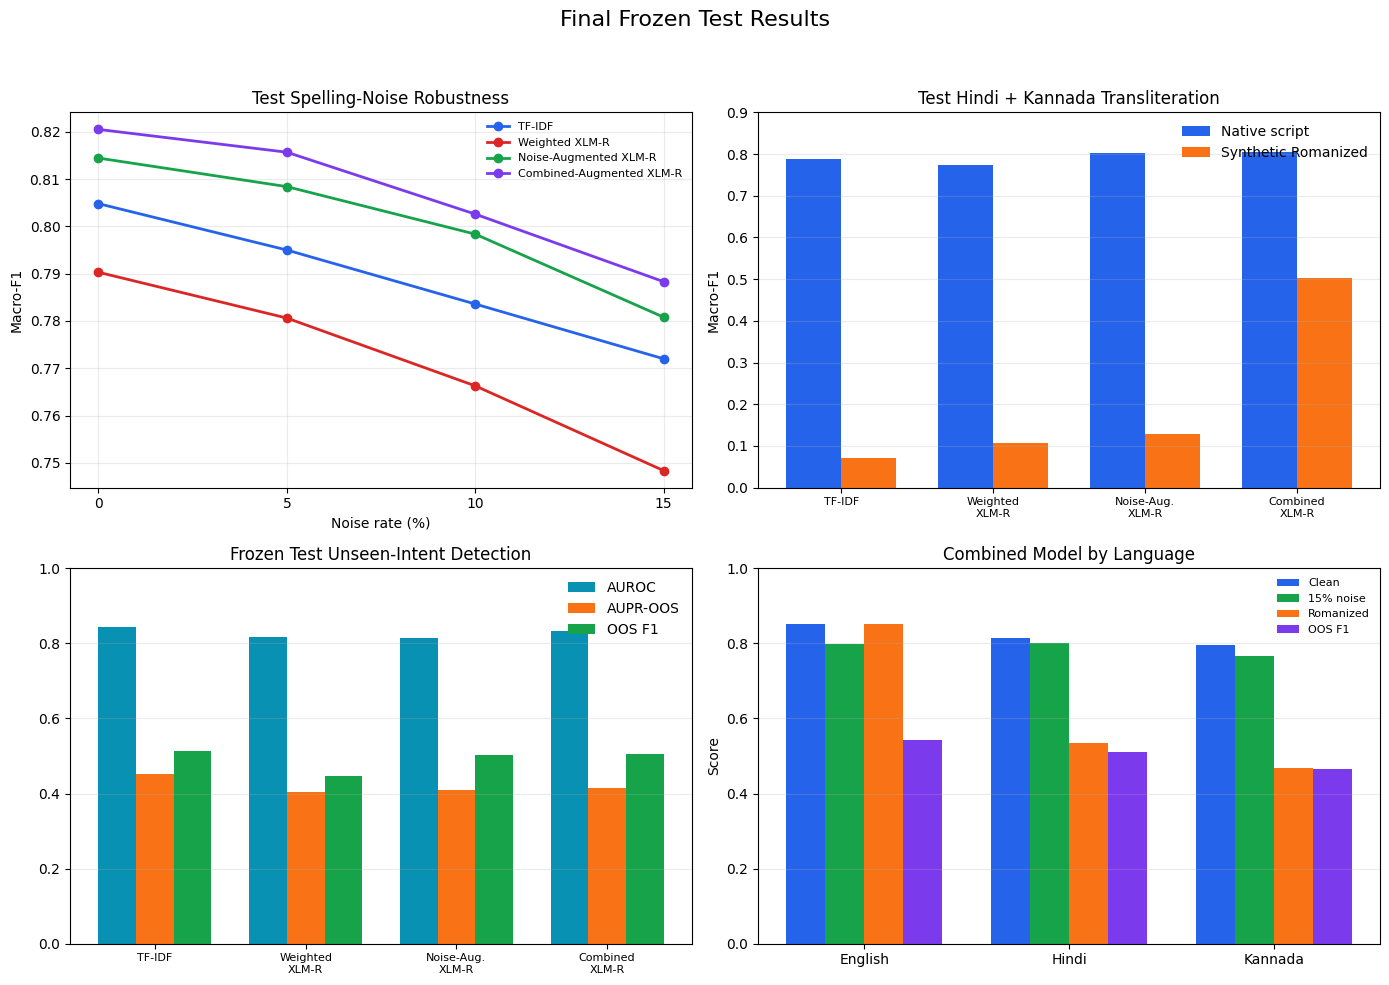

Final figure saved: /content/robust-multilingual-intent-classification/results/figures/final_test_summary.png
Post-test tuning performed: False


In [80]:
import matplotlib.pyplot as plt
import numpy as np

model_order = [
    "TF-IDF",
    "Weighted XLM-R",
    "Noise-Augmented XLM-R",
    "Combined-Augmented XLM-R",
]

short_names = [
    "TF-IDF",
    "Weighted\nXLM-R",
    "Noise-Aug.\nXLM-R",
    "Combined\nXLM-R",
]

model_colors = [
    "#2563eb",
    "#dc2626",
    "#16a34a",
    "#7c3aed",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

# Panel 1: spelling-noise robustness
for model_name, color in zip(
    model_order,
    model_colors
):
    frame = (
        test_condition_results[
            test_condition_results["model"]
            == model_name
        ]
        .sort_values("noise_rate")
    )

    axes[0, 0].plot(
        frame["noise_rate"] * 100,
        frame["macro_f1"],
        marker="o",
        linewidth=2,
        color=color,
        label=model_name,
    )

axes[0, 0].set_title(
    "Test Spelling-Noise Robustness"
)
axes[0, 0].set_xlabel("Noise rate (%)")
axes[0, 0].set_ylabel("Macro-F1")
axes[0, 0].set_xticks([0, 5, 10, 15])
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend(
    frameon=False,
    fontsize=8
)

# Panel 2: transliteration
combined_translit_test = (
    test_transliteration_results[
        test_transliteration_results["group"]
        == "hindi_kannada_combined"
    ]
    .set_index("model")
    .loc[model_order]
)

x = np.arange(len(model_order))
width = 0.36

axes[0, 1].bar(
    x - width / 2,
    combined_translit_test["clean_macro_f1"],
    width,
    label="Native script",
    color="#2563eb",
)

axes[0, 1].bar(
    x + width / 2,
    combined_translit_test[
        "transliterated_macro_f1"
    ],
    width,
    label="Synthetic Romanized",
    color="#f97316",
)

axes[0, 1].set_title(
    "Test Hindi + Kannada Transliteration"
)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(
    short_names,
    fontsize=8
)
axes[0, 1].set_ylabel("Macro-F1")
axes[0, 1].set_ylim(0, 0.9)
axes[0, 1].legend(frameon=False)
axes[0, 1].grid(axis="y", alpha=0.25)

# Panel 3: unseen-intent metrics
oos_plot = (
    test_oos_results
    .set_index("model")
    .loc[model_order]
)

metric_width = 0.25

axes[1, 0].bar(
    x - metric_width,
    oos_plot["auroc"],
    metric_width,
    label="AUROC",
    color="#0891b2",
)

axes[1, 0].bar(
    x,
    oos_plot["aupr_oos"],
    metric_width,
    label="AUPR-OOS",
    color="#f97316",
)

axes[1, 0].bar(
    x + metric_width,
    oos_plot["oos_f1"],
    metric_width,
    label="OOS F1",
    color="#16a34a",
)

axes[1, 0].set_title(
    "Frozen Test Unseen-Intent Detection"
)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(
    short_names,
    fontsize=8
)
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend(frameon=False)
axes[1, 0].grid(axis="y", alpha=0.25)

# Panel 4: combined model by language
language_names = [
    "English",
    "Hindi",
    "Kannada"
]

locale_order = [
    "en-US",
    "hi-IN",
    "kn-IN"
]

primary_conditions = (
    test_condition_language_results[
        test_condition_language_results["model"]
        == primary_model_name
    ]
)

clean_by_language = (
    primary_conditions[
        primary_conditions["condition"]
        == "clean"
    ]
    .set_index("locale")
    .loc[locale_order]["macro_f1"]
    .to_numpy()
)

noise_15_by_language = (
    primary_conditions[
        primary_conditions["condition"]
        == "noise_15"
    ]
    .set_index("locale")
    .loc[locale_order]["macro_f1"]
    .to_numpy()
)

primary_transliteration = (
    test_transliteration_results[
        test_transliteration_results["model"]
        == primary_model_name
    ]
    .set_index("group")
)

romanized_by_language = np.array([
    primary_transliteration.loc[
        "english_control",
        "transliterated_macro_f1"
    ],
    primary_transliteration.loc[
        "hindi_transliterated",
        "transliterated_macro_f1"
    ],
    primary_transliteration.loc[
        "kannada_transliterated",
        "transliterated_macro_f1"
    ],
])

primary_oos_language = (
    test_oos_language_results[
        test_oos_language_results["model"]
        == primary_model_name
    ]
    .set_index("locale")
    .loc[locale_order]["oos_f1"]
    .to_numpy()
)

language_x = np.arange(3)
language_width = 0.19

axes[1, 1].bar(
    language_x - 1.5 * language_width,
    clean_by_language,
    language_width,
    label="Clean",
    color="#2563eb",
)

axes[1, 1].bar(
    language_x - 0.5 * language_width,
    noise_15_by_language,
    language_width,
    label="15% noise",
    color="#16a34a",
)

axes[1, 1].bar(
    language_x + 0.5 * language_width,
    romanized_by_language,
    language_width,
    label="Romanized",
    color="#f97316",
)

axes[1, 1].bar(
    language_x + 1.5 * language_width,
    primary_oos_language,
    language_width,
    label="OOS F1",
    color="#7c3aed",
)

axes[1, 1].set_title(
    "Combined Model by Language"
)
axes[1, 1].set_xticks(language_x)
axes[1, 1].set_xticklabels(language_names)
axes[1, 1].set_ylim(0, 1)
axes[1, 1].set_ylabel("Score")
axes[1, 1].legend(
    frameon=False,
    fontsize=8
)
axes[1, 1].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Final Frozen Test Results",
    fontsize=16,
    y=0.98
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

final_figure_path = (
    repo / "results/figures/"
    "final_test_summary.png"
)

fig.savefig(
    final_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Final figure saved:", final_figure_path)
print("Post-test tuning performed:", False)

In [81]:
from pathlib import Path
import subprocess

repo = Path("/content/robust-multilingual-intent-classification")
readme_path = repo / "README.md"

start_marker = "<!-- FINAL_TEST_RESULTS_START -->"
end_marker = "<!-- FINAL_TEST_RESULTS_END -->"

section = f"""
{start_marker}
## Final frozen test results

The test protocol, model selection, calibration temperatures, and unseen-intent
thresholds were frozen before evaluating the test set. No post-test tuning was
performed.

### Main results

| Model | Clean Macro-F1 | 15% Noise Macro-F1 | Romanized Hindi + Kannada Macro-F1 | OOS AUROC | OOS F1 |
|---|---:|---:|---:|---:|---:|
| TF-IDF | 0.8048 | 0.7720 | 0.0718 | **0.8439** | **0.5122** |
| Weighted XLM-R | 0.7903 | 0.7484 | 0.1064 | 0.8174 | 0.4457 |
| Noise-Augmented XLM-R | 0.8144 | 0.7808 | 0.1299 | 0.8137 | 0.5025 |
| **Combined-Augmented XLM-R** | **0.8205** | **0.7883** | **0.5038** | 0.8329 | 0.5050 |

The Combined-Augmented XLM-R achieved the strongest clean, spelling-noise, and
transliterated-input Macro-F1. The TF-IDF baseline achieved the best frozen-test
unseen-intent AUROC and OOS F1, showing that the best intent classifier was not
automatically the best rejection model.

![Final frozen test results](results/figures/final_test_summary.png)

### Combined model by language

| Language | Clean Macro-F1 | 15% Noise Macro-F1 | Romanized Macro-F1 | OOS F1 |
|---|---:|---:|---:|---:|
| English | 0.8518 | 0.7978 | 0.8518 | 0.5423 |
| Hindi | 0.8145 | 0.8019 | 0.5341 | 0.5097 |
| Kannada | 0.7959 | 0.7664 | 0.4681 | 0.4663 |

Synthetic Romanization remains substantially harder than native-script input,
especially for Kannada. These results apply to the controlled MASSIVE 1.1
evaluation and should not be interpreted as performance on naturally typed
code-mixed or Romanized user data.
{end_marker}
"""

readme = readme_path.read_text(encoding="utf-8")

if start_marker in readme and end_marker in readme:
    before = readme.split(start_marker)[0].rstrip()
    after = readme.split(end_marker, 1)[1].lstrip()
    readme = before + "\n\n" + section.strip() + "\n\n" + after
else:
    readme = readme.rstrip() + "\n\n" + section.strip() + "\n"

readme_path.write_text(readme, encoding="utf-8")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("README updated:", readme_path)
print("\nGit status:")
print(status.stdout)

README updated: /content/robust-multilingual-intent-classification/README.md

Git status:
 M README.md
?? results/figures/final_test_summary.png
?? results/metrics/final_test_metrics.json



In [82]:
from pathlib import Path
import subprocess

repo = Path("/content/robust-multilingual-intent-classification")
readme_path = repo / "README.md"
readme = readme_path.read_text(encoding="utf-8")

replacements = {
    "- [ ] Noise robustness evaluation": "- [x] Noise robustness evaluation",
    "- [ ] Transliteration diagnostic": "- [x] Transliteration diagnostic",
    "- [ ] OOS detection and calibration": "- [x] OOS detection and calibration",
    "- [ ] Final test evaluation": "- [x] Final test evaluation",
}

for old, new in replacements.items():
    readme = readme.replace(old, new)

# Add this completed milestone if it is not already listed.
combined_line = "- [x] Combined noise and transliteration augmentation"
final_line = "- [x] Final test evaluation"

if combined_line not in readme:
    readme = readme.replace(final_line, combined_line + "\n" + final_line)

readme_path.write_text(readme, encoding="utf-8")

status = subprocess.run(
    ["git", "status", "--short"],
    cwd=repo,
    capture_output=True,
    text=True,
)

print("README status checklist updated.")
print("\nGit status:")
print(status.stdout)

README status checklist updated.

Git status:
 M README.md
?? results/figures/final_test_summary.png
?? results/metrics/final_test_metrics.json



In [83]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata

repo = Path("/content/robust-multilingual-intent-classification")

files = [
    "README.md",
    "results/figures/final_test_summary.png",
    "results/metrics/final_test_metrics.json",
]

subprocess.run(["git", "add", *files], cwd=repo, check=True)
subprocess.run(["git", "diff", "--cached", "--check"], cwd=repo, check=True)

commit = subprocess.run(
    ["git", "commit", "-m", "eval: report frozen final test results"],
    cwd=repo,
    capture_output=True,
    text=True,
)
print(commit.stdout)
print(commit.stderr)

token = userdata.get("GITHUB_TOKEN")
askpass = Path("/tmp/github_askpass.sh")
askpass.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
    'esac\n',
    encoding="utf-8",
)
askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

push = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd=repo,
    env=env,
    capture_output=True,
    text=True,
    check=True,
)

latest = subprocess.run(
    ["git", "log", "-1", "--oneline"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

status = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=repo,
    capture_output=True,
    text=True,
    check=True,
)

print("Latest commit:", latest.stdout.strip())
print("Status:", status.stdout.strip())

[main e4ba706] eval: report frozen final test results
 3 files changed, 1106 insertions(+), 4 deletions(-)
 create mode 100644 results/figures/final_test_summary.png
 create mode 100644 results/metrics/final_test_metrics.json


Latest commit: e4ba706 eval: report frozen final test results
Status: ## main...origin/main
